# Same Food, Different Bodies
### Do invertebrate-eating birds come in body types, and do those types hunt differently?

Every bird in this study gets at least 80% of its food from invertebrates (4,119 species). Holding the diet constant is deliberate: across all birds, body shape mostly reflects *what* is eaten, so within one diet the remaining differences must come from *how* the food is caught. We describe how a bird hunts by its **technique**: aerial screening (continuous flight), sallying (short flights from a perch), gleaning (picking prey off a surface) and bark foraging (climbing trunks).

Two questions: **(1) does body shape come in discrete types, or vary continuously? (2) Either way, does shape predict the main technique, even on lineages a model has never seen?**

| Chapter | Question | Answer in one line |
|---|---|---|
| 0 · The cast | What do we analyse, and why logs and ratios? | 4,119 species, 9 shape features, kept apart from the 13 variables that judge them |
| I · Shape | Do invertivores form distinct body types? | One sharply separated type (M1, aerial build, 322 species); the other three blend into a continuum |
| II · Function | Do the groups hunt differently? | Yes. M1 screens, M3 sallies, M4 gleans, M2 holds the bark foragers; geography adds little |
| III · Prediction | Does shape predict the main technique on unseen families and orders? | Yes: macro ROC-AUC 0.87–0.88 on unseen families and 0.82 on unseen orders, 0.99 for aerial screening |
| Conclusions | What stays open? | Only M1 is separated; species are not independent, so p-values and prediction scores are optimistic |

**Methods:** PCA; k-means, with k chosen by bootstrap ARI stability and checked against a shuffled-data silhouette; UMAP as a visual check; two-block validation; χ² with Cramér's V and Kruskal–Wallis with ε² (Benjamini–Hochberg); pairwise Fisher exact tests with Holm correction; surrogate models with permutation importance; logistic regression and random forest with family- and order-grouped cross-validation; SHAP. **Controls:** shuffled labels, folds that hold out whole families and whole orders, family-level bootstrap intervals.

# Chapter 0 · The cast
**What this chapter does:** we fix the cohort, what the algorithm is allowed to see (9 shape features) and what it must not see (13 variables kept aside to judge the result).

## 0.1 · Setup
**What this cell does.** Imports the libraries, fixes the random seed (42), creates the `figures/` folder and sets one visual style for every figure: the same palette, fonts and grid throughout. Two helpers are defined: `save()` writes a figure to disk at 200 dpi, `suptitle()` adds a title and a one-line subtitle.

In [1]:
import logging, re, warnings
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import umap
from adjustText import adjust_text
from matplotlib import font_manager as _fm
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.legend_handler import HandlerBase
from matplotlib.patches import FancyBboxPatch, Patch
from matplotlib.text import Text
from matplotlib.ticker import PercentFormatter
from scipy import stats
from scipy.stats import gaussian_kde
from skimage.measure import find_contours
from sklearn.cluster import KMeans, MeanShift, estimate_bandwidth
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    adjusted_rand_score, average_precision_score, confusion_matrix,
    precision_recall_curve, roc_auc_score, roc_curve, silhouette_score,
)
from sklearn.model_selection import LeaveOneGroupOut, StratifiedGroupKFold, StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

SEED = 42
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# ---- visual system ----
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MT_TXT = ["#1f62b5", "#b8451a", "#0f7550", "#8a5d00"]
OTHER, INK, INK2, MUTED, GRID, AXIS = "#b5b3ab", "#23302A", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
OCHRE, FOREST, SAGE = "#B07A2A", "#2E5A45", "#688153"

SEQ = LinearSegmentedColormap.from_list("seq", [(0.0, "#f6f6f6"), (0.25, "#e3e7e0"), (0.6, "#bac5b1"), (0.85, "#8fa180"), (1.0, SAGE)])
DIV = LinearSegmentedColormap.from_list("div", [
    (0.0, "#313f47"), (0.093, "#566269"), (0.225, "#8c9498"), (0.357, "#c1c5c7"), (0.424, "#dcdedf"),
    (0.5, "#f6f6f6"), (0.57, "#e3e7e0"), (0.71, "#bac5b1"), (0.86, "#8fa180"), (1.0, SAGE),
])

plt.rcParams.update({
    "font.family": ["Helvetica", "Arial", "Liberation Sans", "DejaVu Sans"], "font.size": 9.5,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "figure.facecolor": "white",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.frameon": False, "legend.fontsize": 8.5,
})

def save(fig, name, dpi=200, facecolor="white"):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=dpi, facecolor=facecolor)
    plt.show()

def suptitle(fig, text, sub=None, y=1.02):
    fig.suptitle(text, x=0.01, ha="left", va="top", fontweight="bold", fontsize=13, y=y, color=INK)
    if sub:
        fig.text(0.01, y - 0.27 / fig.get_figheight(), sub, ha="left", va="top", fontsize=9.5, color=INK2)

for _d in ("./fonts", "/tmp/fnt/package"):
    for _f in Path(_d).rglob("*.ttf"):
        _fm.fontManager.addfont(str(_f))

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 0.2 · Who is in the study: building the cohort
**Question it serves.** We want differences in body shape to tell us *how* a bird hunts, so all the birds we compare should eat the same thing.
**What this cell does.** It loads AVONET and AVONICHE and joins them on the Avibase ID (11,009 species). AVONET supplies body measurements, range, migration, habitat and taxonomy; AVONICHE supplies each species' share of foraging effort in each feeding niche. It keeps the species whose **seven invertebrate niches add up to at least 80%** of foraging, and removes the 5 kiwis, whose wing is coded 0.1 ("no functional wing") and would distort every wing ratio.
**How.** The seven invertebrate niches are aerial screening `IAE`, sally-to-air `ISA`, sally-to-surface `ISS`, sally-to-ground `ISG`, vertical substrate `IVS`, glean elevated `IGE` and glean ground `IGG`. AVONICHE has no aquatic invertebrate niche, so seabirds and most waders drop out by construction.
**Why 80%.** The four technique shares then describe almost all of a bird's foraging, so the "main technique" in Chapters II–III is a real summary of how it feeds.

In [2]:
avonet = pd.read_csv("./datasets/AVONET1_BirdLife.csv")
avoniche = pd.read_csv("./datasets/Avoniche1_Birdlife2020.csv").rename(columns={"Avibase_id": "Avibase.ID1"})
df_all = avonet.merge(avoniche, on="Avibase.ID1", how="inner", validate="one_to_one", suffixes=("", "_niche"))

I_COLS = ["IAE", "ISA", "ISS", "ISG", "IVS", "IGE", "IGG"]
RAW_MORPH = [
    "Beak.Length_Culmen", "Beak.Length_Nares", "Beak.Width", "Beak.Depth",
    "Tarsus.Length", "Wing.Length", "Tail.Length", "Hand-Wing.Index", "Mass",
]
PLACEHOLDER = 0.1  # AVONET code for "no functional wing" (kiwis)
PERCENTAGE_I = 80


def counts(d):
    return f"{len(d):,} species · {d.Family1.nunique()} families · {d.Order1.nunique()} orders"


inv_all = df_all[I_COLS].sum(axis=1)
funnel = [("species in AVONET + AVONICHE", counts(df_all))]

df = df_all.loc[inv_all >= PERCENTAGE_I].copy()
funnel.append((f"invertebrate niches ≥ {PERCENTAGE_I}% of foraging", counts(df)))

is_ph = (df[["Wing.Length", "Tail.Length", "Hand-Wing.Index"]] == PLACEHOLDER).any(axis=1)
print("Removed (wing coded as placeholder 0.1):", sorted(df.loc[is_ph, "Species1"]))

df = df.loc[~is_ph].reset_index(drop=True)
funnel.append(("after removing kiwis (wing coded 0.1)", counts(df)))

assert df[RAW_MORPH].notna().all().all() and (df[RAW_MORPH] > 0).all().all()
has_coords = df[["Centroid.Latitude", "Centroid.Longitude"]].notna().all(axis=1)
funnel.append(("with a range centre (maps only)", counts(df.loc[has_coords])))

for label, summary in funnel:
    print(f"{summary:<52} {label}")

Removed (wing coded as placeholder 0.1): ['Apteryx australis', 'Apteryx haastii', 'Apteryx mantelli', 'Apteryx owenii', 'Apteryx rowi']
11,009 species · 243 families · 36 orders            species in AVONET + AVONICHE
4,124 species · 138 families · 16 orders             invertebrate niches ≥ 80% of foraging
4,119 species · 137 families · 15 orders             after removing kiwis (wing coded 0.1)
4,095 species · 137 families · 15 orders             with a range centre (maps only)


#### What "invertivore" means here
**What this cell does.** It plots, for all 11,009 species, the share of foraging effort spent on invertebrates (the sum of the seven invertebrate niches), with the 80% cut-off.

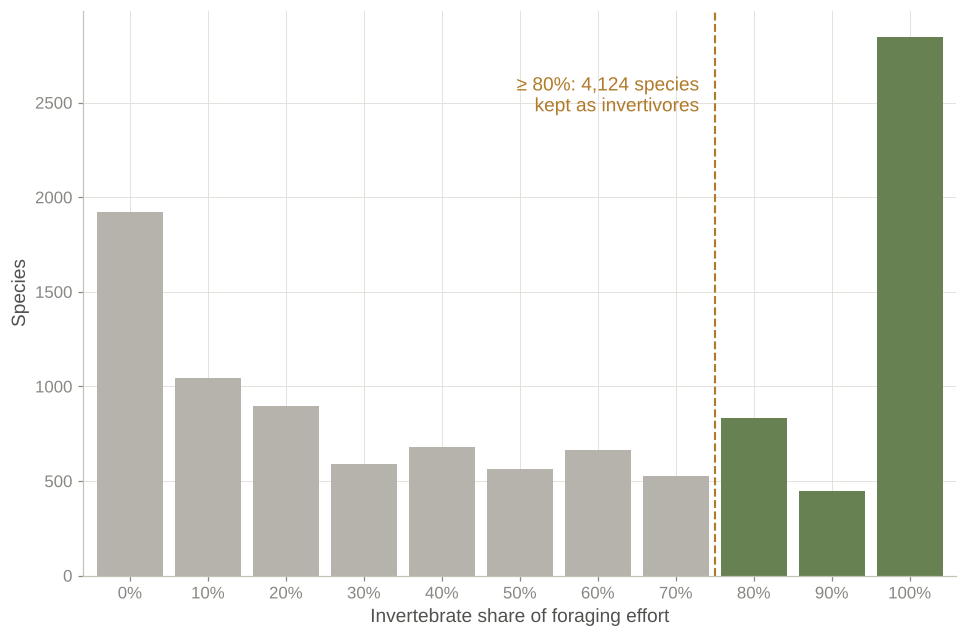

In [3]:
# What "invertivore" means here: the invertebrate share of foraging, all species
BIG = {"font.size": 13.5, "axes.titlesize": 13.5, "axes.labelsize": 12.5, "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11.5}
with plt.rc_context(BIG):
    fig, ax = plt.subplots(figsize=(9, 6))

    centers = np.arange(0, 110, 10)
    bins = np.arange(-5, 115, 10)
    h, _ = np.histogram(inv_all, bins=bins)

    ax.bar(centers, h, width=8.5, color=[SAGE if x >= PERCENTAGE_I else OTHER for x in centers])
    ax.axvline(PERCENTAGE_I - 5, color=OCHRE, lw=1.4, ls="--")

    n_in = int((inv_all >= PERCENTAGE_I).sum())
    ax.text(
        PERCENTAGE_I - 7,
        h.max() * 0.93,
        f"≥ {PERCENTAGE_I}%: {n_in:,} species\nkept as invertivores",
        color=OCHRE,
        fontsize=12.5,
        ha="right",
        va="top",
    )

    ax.set_xticks(centers)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_xlim(-6, 106)
    ax.set_ylim(0, None)
    ax.set_xlabel("Invertebrate share of foraging effort")
    ax.set_ylabel("Species")

    fig.tight_layout()
    save(fig, "00b_what_is_an_invertivore")

**Reading the figure** · Green bars are kept; the dashed line is the 80% cut-off.

**Takeaway.** The two ends of the scale are the most common: 1,921 species never eat invertebrates and 2,844 eat nothing else. The cut-off keeps 4,124 species (4,119 after removing the kiwis).

## 0.3 · Two blocks of variables: what the algorithm sees and what judges it
**Question it serves.** How do we make sure later tests are not circular?
**What this cell does.**
- **Internal block** (the only input to PCA and clustering): 9 shape features: body mass, relative beak length, beak length/width, beak depth/width, nares/beak length, relative tarsus (leg), relative wing, tail/wing and hand-wing index.
- **External block** (never shown to the clustering, 13 variables): the four technique shares (screening, sally, glean, bark), the dominant technique, primary lifestyle, habitat, migration, habitat density, |latitude|, range size, order and family.
- **Dominant technique (y4).** The largest of the four technique shares, one label per species. It is used in Chapters II and III. 64 species (1.6%) have a tie; they get the first technique in the order screening, sally, glean, bark.

**How.** A ratio is a difference of logs. "Relative" means divided by mass^(1/3): mass is a volume, so its cube root is a length on the same scale as a wing or a leg. An `assert` stops the notebook if any column appears in both blocks.
**Why.** If foraging or taxonomy helped build the groups, finding afterwards that the groups forage differently would be guaranteed and would prove nothing.

In [4]:
log_raw = np.log10(df[RAW_MORPH])
log_mass = log_raw["Mass"]

NICE = {
    "log_Mass": "Body mass",
    "Rel_Beak_Length": "Relative beak length",
    "Beak_Aspect": "Beak length/width",
    "Beak_Depth_Width": "Beak depth/width",
    "Nares_Beak": "Nares/beak length",
    "Rel_Tarsus": "Relative tarsus (leg)",
    "Rel_Wing": "Relative wing",
    "Tail_Wing": "Tail/wing",
    "log_HWI": "Hand-wing index",
}
INTERNAL_MORPH_COLS = list(NICE)

STRAT_COLS = ["I_Screen", "I_Sally", "I_Glean", "I_Bark"]
STRAT_LAB = ["Screening", "Sally", "Glean", "Bark"]

df = df.assign(
    log_Mass=log_mass,
    Rel_Beak_Length=log_raw["Beak.Length_Culmen"] - log_mass / 3,
    Beak_Aspect=log_raw["Beak.Length_Culmen"] - log_raw["Beak.Width"],
    Beak_Depth_Width=log_raw["Beak.Depth"] - log_raw["Beak.Width"],
    Nares_Beak=log_raw["Beak.Length_Nares"] - log_raw["Beak.Length_Culmen"],
    Rel_Tarsus=log_raw["Tarsus.Length"] - log_mass / 3,
    Rel_Wing=log_raw["Wing.Length"] - log_mass / 3,
    Tail_Wing=log_raw["Tail.Length"] - log_raw["Wing.Length"],
    log_HWI=log_raw["Hand-Wing.Index"],
    # ---- external block: never shown to PCA or clustering ----
    I_Screen=df["IAE"],
    I_Sally=df["ISA"] + df["ISS"] + df["ISG"],
    I_Glean=df["IGE"] + df["IGG"],
    I_Bark=df["IVS"],
    Abs_Latitude=df["Centroid.Latitude"].abs(),
    Log_Range_Size=np.log10(df["Range.Size"] + 1),
)

# Dominant foraging technique (y4): integer code for Chapter III, string label for Chapter II
assert df[STRAT_COLS].notna().all().all(), "Missing values in STRAT_COLS would corrupt argmax labels"
shares_mat = df[STRAT_COLS].to_numpy(dtype=float)
df["y4_idx"] = shares_mat.argmax(axis=1)
df["y4_label"] = [STRAT_LAB[i] for i in df["y4_idx"]]

n_tied = int(((shares_mat == shares_mat.max(axis=1, keepdims=True)).sum(axis=1) > 1).sum())

# Single source of truth for the 7 external variables tested in Chapter II
EXT_VARS = [
    ("Dominant technique (y4)", "y4_label", "cat", "foraging & ecology"),
    ("Primary lifestyle (AVONET)", "Primary.Lifestyle", "cat", "foraging & ecology"),
    ("Habitat", "Habitat", "cat", "foraging & ecology"),
    ("Migration", "Migration", "cat", "geography controls"),
    ("Habitat density", "Habitat.Density", "cat", "geography controls"),
    ("|Latitude|", "Abs_Latitude", "num", "geography controls"),
    ("Range size", "Log_Range_Size", "num", "geography controls"),
]

# Full list of held-out columns (shares + y4 + 6 ecology/geography controls + taxonomy)
EXTERNAL_VAL_COLS = STRAT_COLS + [col for _, col, _, _ in EXT_VARS] + ["Order1", "Family1"]

assert not set(INTERNAL_MORPH_COLS) & set(EXTERNAL_VAL_COLS), "leakage: a column is in both blocks"

cond_num = np.linalg.cond(df[INTERNAL_MORPH_COLS].corr())
print(f"Internal block: {len(INTERNAL_MORPH_COLS)} features, condition number {cond_num:.1f} (full rank)")
print(f"External block: {len(EXTERNAL_VAL_COLS)} held-out variables ({len(EXT_VARS)} tested in Ch. II)")
print(f"Dominant-technique ties: {n_tied:,} / {len(df):,} ({n_tied / len(df):.1%})")
print(f"Niches inferred from relatives: {(df.Inferred > 0).mean():.0%} | Passeriformes: {(df.Order1 == 'Passeriformes').mean():.0%}")

Internal block: 9 features, condition number 20.9 (full rank)
External block: 13 held-out variables (7 tested in Ch. II)
Dominant-technique ties: 64 / 4,119 (1.6%)
Niches inferred from relatives: 22% | Passeriformes: 79%


In [5]:

ext_labels = {col: name for name, col, _, _ in EXT_VARS}

print(f"=== INTERNAL BLOCK ({len(INTERNAL_MORPH_COLS)} features) ===")
for i, col in enumerate(INTERNAL_MORPH_COLS, 1):
    print(f"  {i:2d}. {col:<18} ({NICE[col]})")

print(f"\n=== EXTERNAL BLOCK ({len(EXTERNAL_VAL_COLS)} variables) ===")
for i, col in enumerate(EXTERNAL_VAL_COLS, 1):
    label = f" ({ext_labels[col]})" if col in ext_labels else ""
    print(f"  {i:2d}. {col:<18}{label}")

=== INTERNAL BLOCK (9 features) ===
   1. log_Mass           (Body mass)
   2. Rel_Beak_Length    (Relative beak length)
   3. Beak_Aspect        (Beak length/width)
   4. Beak_Depth_Width   (Beak depth/width)
   5. Nares_Beak         (Nares/beak length)
   6. Rel_Tarsus         (Relative tarsus (leg))
   7. Rel_Wing           (Relative wing)
   8. Tail_Wing          (Tail/wing)
   9. log_HWI            (Hand-wing index)

=== EXTERNAL BLOCK (13 variables) ===
   1. I_Screen          
   2. I_Sally           
   3. I_Glean           
   4. I_Bark            
   5. y4_label           (Dominant technique (y4))
   6. Primary.Lifestyle  (Primary lifestyle (AVONET))
   7. Habitat            (Habitat)
   8. Migration          (Migration)
   9. Habitat.Density    (Habitat density)
  10. Abs_Latitude       (|Latitude|)
  11. Log_Range_Size     (Range size)
  12. Order1            
  13. Family1           


## 0.5 · Why a log scale
**Question it serves.** Can we use the raw measurements directly in PCA and k-means?
**What these cells do.** The first plots the nine raw measurements as measured and in log10. The second compares the skewness of the nine features before and after the log.
**Why.** PCA uses variances and k-means uses Euclidean distances, and both are dominated by a few giant species when the data are skewed. On a log scale a 2 g → 20 g difference counts the same as a 200 g → 2 kg difference.

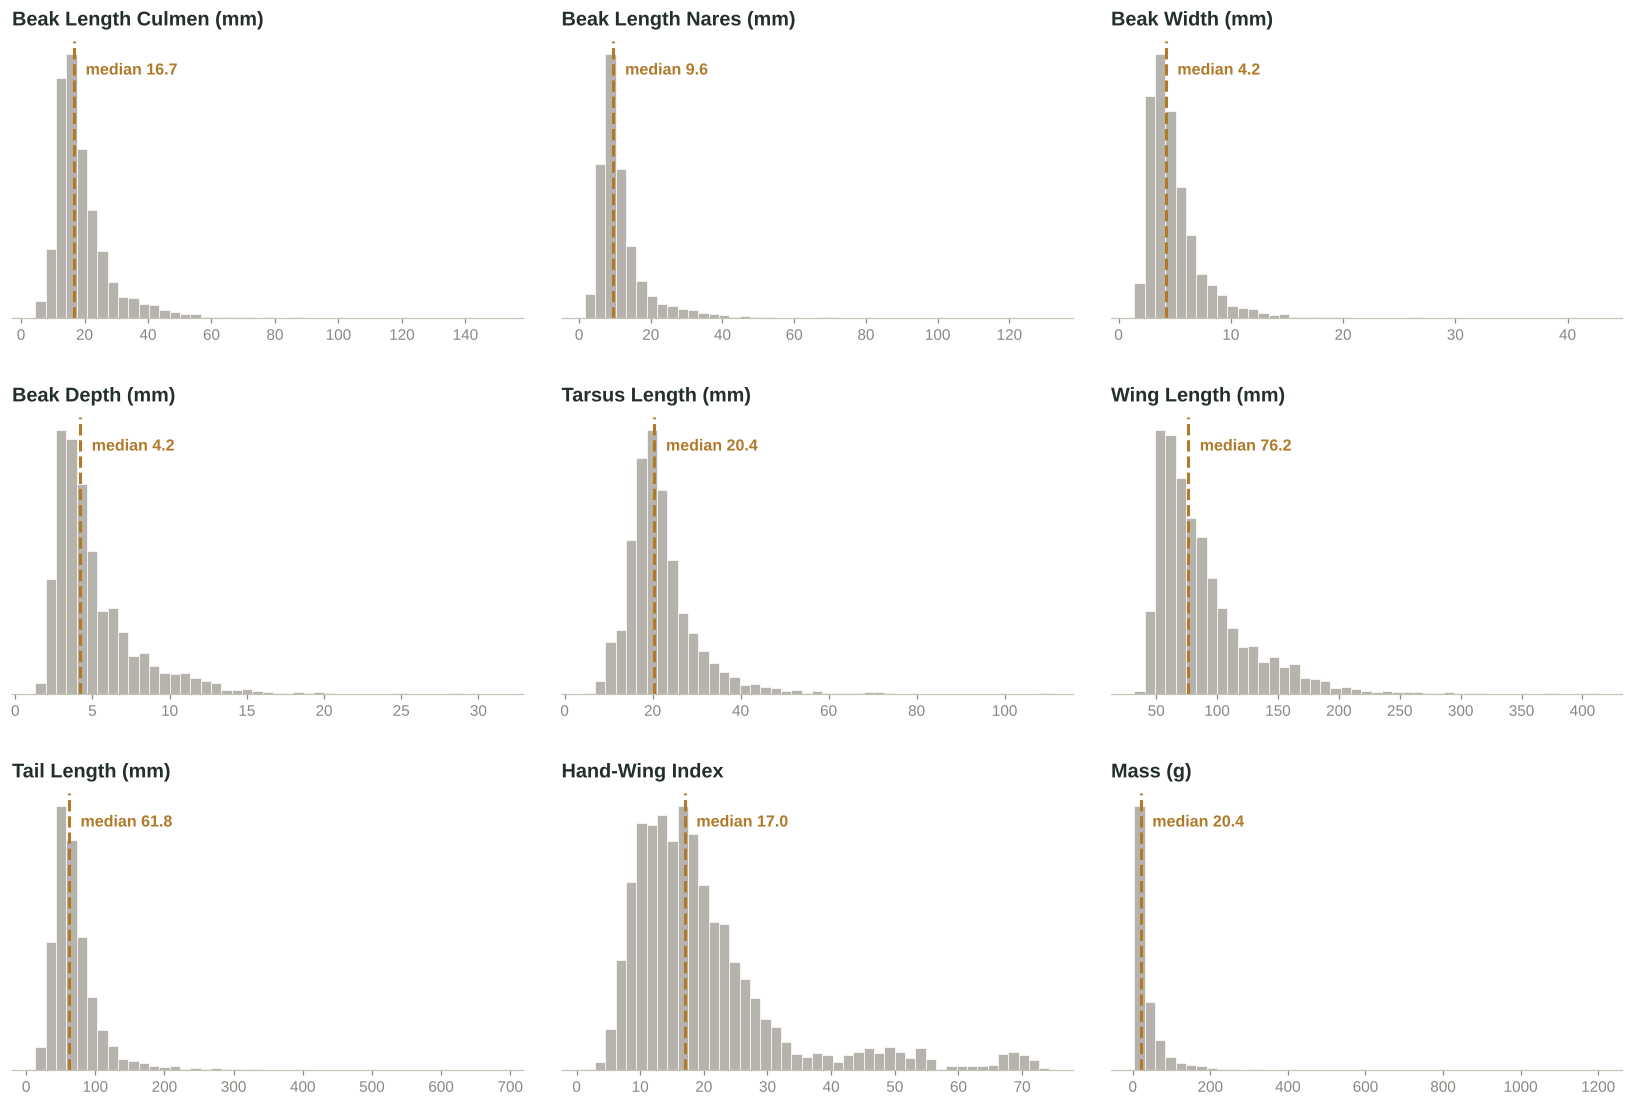

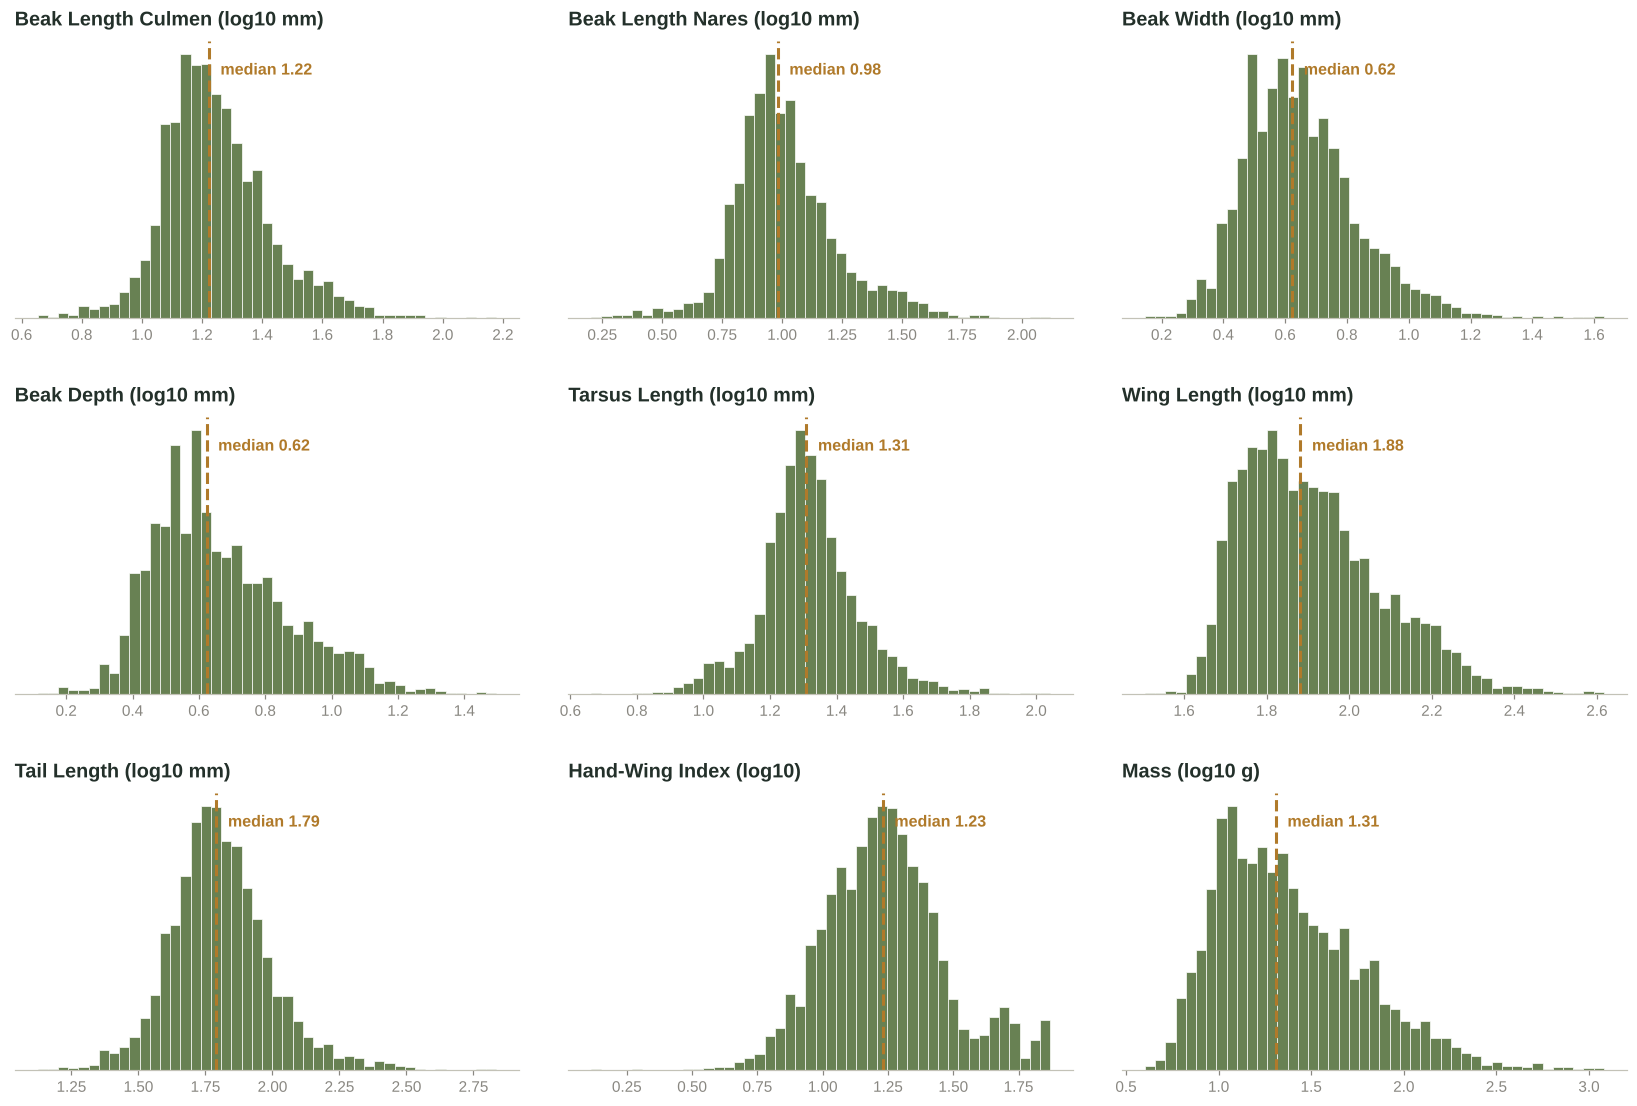

In [6]:
RAW_UNITS = {
    "Mass": "g",
    "Beak.Length_Culmen": "mm",
    "Beak.Length_Nares": "mm",
    "Beak.Width": "mm",
    "Beak.Depth": "mm",
    "Tarsus.Length": "mm",
    "Wing.Length": "mm",
    "Tail.Length": "mm",
}
RAW_LABELS = {c: c.replace(".", " ").replace("_", " ") for c in RAW_MORPH}


def format_median(val, is_log):
    if is_log:
        return f"median {val:.2f}"
    return f"median {val:,.0f}" if abs(val) >= 100 else f"median {val:.1f}"


n_cols = 3
n_rows = int(np.ceil(len(RAW_MORPH) / n_cols))

with plt.rc_context({"font.size": 11.5, "axes.titlesize": 13, "xtick.labelsize": 10}):
    for is_log, bar_color, fname in [(False, OTHER, "02a_raw_distributions"), (True, SAGE, "02a_log_distributions")]:
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.4 * n_rows))
        axes_flat = axes.ravel()

        for ax, col in zip(axes_flat, RAW_MORPH):
            vals = (log_raw[col] if is_log else df[col]).to_numpy()
            med = np.median(vals)

            ax.hist(vals, bins=45, color=bar_color, edgecolor="white", linewidth=0.45)
            ax.axvline(med, color=OCHRE, lw=2, ls="--")

            span = vals.max() - vals.min()
            near_right = (vals.max() - med) < 0.28 * span
            ax.text(
                med + span * (-0.025 if near_right else 0.025),
                ax.get_ylim()[1] * 0.92,
                format_median(med, is_log),
                color=OCHRE,
                fontsize=10.5,
                fontweight="bold",
                ha="right" if near_right else "left",
                va="top",
            )

            parts = [p for p in ("log10" if is_log else "", RAW_UNITS.get(col, "")) if p]
            unit_str = f" ({' '.join(parts)})" if parts else ""
            ax.set_title(f"{RAW_LABELS[col]}{unit_str}", pad=10)
            ax.set_ylim(0, None)
            ax.get_yaxis().set_visible(False)
            ax.spines["left"].set_visible(False)
            ax.grid(False)

        for ax in axes_flat[len(RAW_MORPH):]:
            ax.set_visible(False)

        fig.tight_layout(w_pad=2.0, h_pad=2.5)
        save(fig, fname)

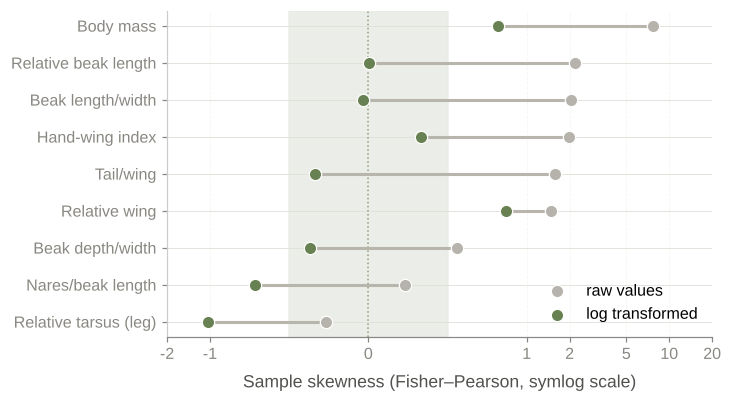

In [7]:
with plt.rc_context({"font.size": 11.5, "axes.labelsize": 11.5, "xtick.labelsize": 10.5, "ytick.labelsize": 10.5}):
    sk = pd.DataFrame({
        "raw": (10 ** df[INTERNAL_MORPH_COLS]).apply(stats.skew),
        "log": df[INTERNAL_MORPH_COLS].apply(stats.skew),
    }).sort_values("raw")


    fig, ax = plt.subplots(figsize=(6.8, 3.8))
    yy = np.arange(len(sk))

    ax.axvspan(-0.5, 0.5, color="#e8ece4", alpha=0.85, zorder=0)
    ax.axvline(0, color=SAGE, lw=1, ls=":", alpha=0.7, zorder=1)
    ax.hlines(yy, sk["raw"], sk["log"], color="#b8b5ad", lw=2, zorder=2)

    ax.scatter(sk["raw"], yy, s=65, color=OTHER, zorder=3, label="raw values", edgecolor="white", linewidth=0.8)
    ax.scatter(sk["log"], yy, s=65, color=SAGE, zorder=4, label="log transformed", edgecolor="white", linewidth=0.8)

    ax.set_yticks(yy)
    ax.set_yticklabels([NICE[c] for c in sk.index])
    ax.set_xscale("symlog", linthresh=1)
    ticks = [-2, -1, 0, 1, 2, 5, 10, 20]
    ax.set_xticks(ticks)
    ax.set_xticklabels(map(str, ticks))

    ax.set_xlabel("Sample skewness (Fisher–Pearson, symlog scale)", labelpad=8)
    ax.legend(loc="lower right", fontsize=10.5)
    ax.spines["left"].set_color("#cccccc")
    ax.spines["bottom"].set_color("#888888")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

    fig.tight_layout()
    save(fig, "02b_skewness_clustering_features")

**Reading the figures** · Skewness measures the long tail; the grey band (−0.5 to 0.5) is roughly symmetric.

**Takeaway.** Raw measurements pile up on the left with a long right tail. Body mass is the extreme case (skewness 7.7 raw, 0.8 in log). After the log every feature lies between −1.0 and 0.9. Range size, kept aside for the tests, is just as skewed raw (5.2), which is one reason its test uses ranks.

## 0.6 · Why shape ratios instead of raw measurements
**Question it serves.** Would the clustering find *body plans*, or just big and small birds?
**What this cell does.** It compares Spearman correlations among the raw measurements with correlations among our 9 features.
**Why.** Every raw length grows with body size, so raw measurements move together and a clustering on them would sort birds by size. The 9 features keep size once (body mass) and express everything else as proportions.

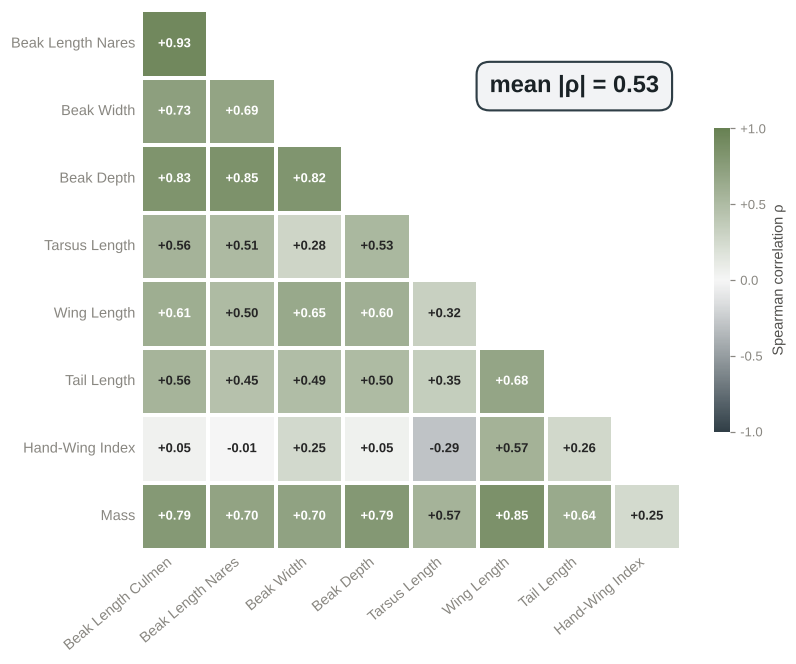

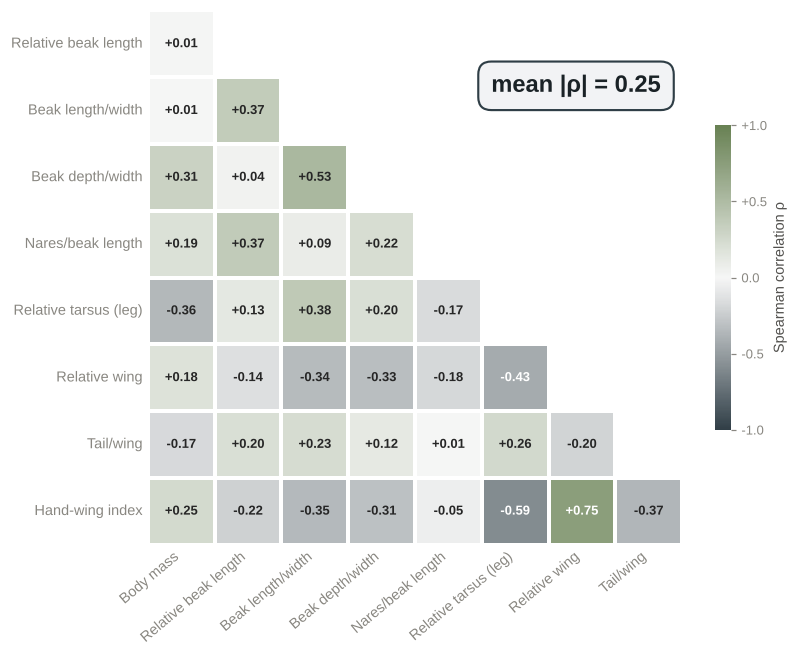

In [8]:
raw_named = df[RAW_MORPH].rename(columns=RAW_LABELS)
feat_named = df[INTERNAL_MORPH_COLS].rename(columns=NICE)

for M, fname in [(raw_named, "02b_corr_original"), (feat_named, "02b_corr_derived")]:
    fig, ax = plt.subplots(figsize=(7.6, 6.2))
    c = M.corr(method="spearman")
    off = np.abs(c.values[np.tril_indices(len(c), -1)]).mean()
    c_low = c.iloc[1:, :-1]

    sns.heatmap(
        c_low,
        mask=np.triu(np.ones_like(c_low, bool), k=1),
        cmap=DIV,
        vmin=-1,
        vmax=1,
        center=0,
        annot=True,
        fmt="+.2f",
        annot_kws={"size": 8.5, "fontweight": "bold"},
        square=True,
        cbar_kws=dict(shrink=0.55, label="Spearman correlation ρ", ticks=[-1, -0.5, 0, 0.5, 1]),
        ax=ax,
        linewidths=1.5,
        linecolor="white",
    )

    cbar = ax.collections[0].colorbar
    cbar.set_ticklabels(["-1.0", "-0.5", "0.0", "+0.5", "+1.0"])
    cbar.outline.set_visible(False)

    ax.text(
        0.96,
        0.88,
        f"mean |ρ| = {off:.2f}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=15.5,
        fontweight="heavy",
        color="#1a2226",
        bbox=dict(boxstyle="round,pad=0.55", facecolor="#f2f3f5", edgecolor="#2f3e46", lw=1.4),
    )

    ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9.5)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=9.5)
    ax.tick_params(length=0)
    ax.grid(False)

    fig.tight_layout()
    save(fig, fname)

**Reading the figure** · Each cell is a Spearman correlation: green = the two move together, slate = in opposite directions.

**Takeaway.** Raw measurements are mostly "size" (mean |ρ| 0.53; the first principal component takes 56% of the variance). The ratios remove most of it (mean |ρ| 0.25; first component 37%), so the axes describe *shape*. Nares/beak length is only weakly tied to the other features (|ρ| ≤ 0.37), so it adds information.

# Chapter I · Shape: do invertivores form distinct body plans?
**Last chapter → this chapter:** 4,119 birds described by 9 shape features. **Question:** is there structure in that cloud, or only a smooth continuum? We find groups with PCA and k-means, check their stability with resampling, look at them on UMAP, and describe them. **Caution:** these are shapes only; whether they mean anything is the question of the next chapters.

## I.1 · PCA: the main axes of body shape
**Question it serves.** In which directions do invertivore bodies differ most?
**What this cell does.** It standardises the 9 features (z-scores), fits a PCA and computes the **loadings** (the correlation of each feature with each component). It flips signs so that PC1 is positive for pointed wings, and prints a name for the first four axes.
**Why standardise.** Without z-scores the most variable ratio would dominate both PCA and k-means.
**Why PCA.** To see the cloud in 2 dimensions and name its axes. The **clustering runs on all 9 standardised features**, not on the PCs.

In [9]:
scaler = StandardScaler()
Xs = scaler.fit_transform(df[INTERNAL_MORPH_COLS])
pca = PCA(random_state=SEED)
pcs = pca.fit_transform(Xs)
# Sign convention: PC1 positive = higher hand-wing index (more aerial to the right)
if pca.components_[0, INTERNAL_MORPH_COLS.index("log_HWI")] < 0:
    pca.components_[0] *= -1
    pcs[:, 0] *= -1

evr = pca.explained_variance_ratio_
load = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    index=INTERNAL_MORPH_COLS,
    columns=[f"PC{i + 1}" for i in range(len(evr))],  # correlation of each feature with each PC
)

def axis_name(pc):
    s = load[pc].sort_values()
    return f"{NICE[s.index[-1]]} ↔ {NICE[s.index[0]]}"

for i in range(4):
    pc = f"PC{i + 1}"
    hi, lo = axis_name(pc).split(" ↔ ")
    print(f"{pc}: {evr[i]:.1%} (cumulative {evr[:i + 1].sum():.1%}) | high: {hi} · low: {lo}")
print(load.iloc[:, :4].round(2))

PC1: 36.9% (cumulative 36.9%) | high: Hand-wing index · low: Relative tarsus (leg)
PC2: 18.1% (cumulative 55.0%) | high: Body mass · low: Relative tarsus (leg)
PC3: 12.4% (cumulative 67.4%) | high: Beak depth/width · low: Relative beak length
PC4: 10.3% (cumulative 77.7%) | high: Beak length/width · low: Nares/beak length
                   PC1   PC2   PC3   PC4
log_Mass          0.17  0.76  0.25 -0.08
Rel_Beak_Length  -0.58  0.35 -0.54  0.30
Beak_Aspect      -0.63  0.29  0.25  0.54
Beak_Depth_Width -0.55  0.47  0.56 -0.03
Nares_Beak       -0.41  0.54 -0.50 -0.39
Rel_Tarsus       -0.69 -0.44  0.26 -0.04
Rel_Wing          0.82  0.13  0.01  0.39
Tail_Wing        -0.49 -0.23 -0.25  0.42
log_HWI           0.85  0.24 -0.06  0.24


#### Drawing the PCA
**What this cell does.** Scree plot (variance per component and cumulative) and loading heatmap, from the numbers computed above.

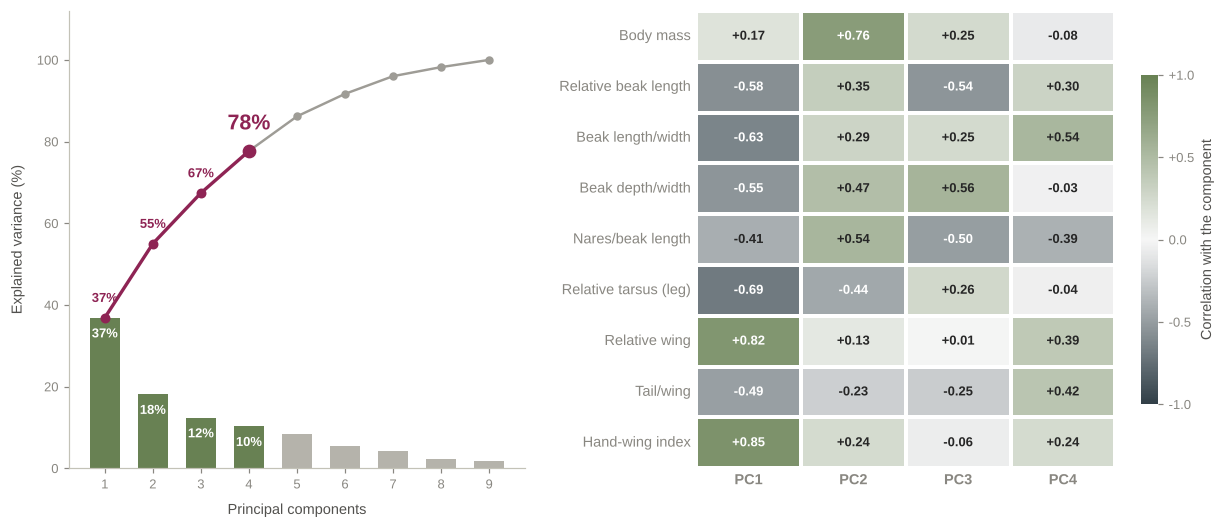

In [10]:
N_PCS = 4
PLUM = "#8e2454"

fig = plt.figure(figsize=(13.5, 5.4))
gsp = fig.add_gridspec(1, 2, width_ratios=[1.0, 1.15], wspace=0.35)

# --- 1. Pareto / Scree plot (PC1–PC4 highlighted) ---
ax1 = fig.add_subplot(gsp[0])
k_ = np.arange(1, len(evr) + 1)
cum_evr = np.cumsum(evr) * 100

bar_colors = [SAGE if i < N_PCS else OTHER for i in range(len(evr))]
ax1.bar(k_, evr * 100, color=bar_colors, width=0.62, zorder=2)

ax1.plot(k_[N_PCS - 1:], cum_evr[N_PCS - 1:], color="#9e9c96", marker="o", ms=4.5, lw=1.6, zorder=3)
ax1.plot(k_[:N_PCS], cum_evr[:N_PCS], color=PLUM, marker="o", ms=5.5, lw=2.2, zorder=4)
ax1.plot(k_[N_PCS - 1], cum_evr[N_PCS - 1], color=PLUM, marker="o", ms=8.0, zorder=5)

for i in range(N_PCS):
    ind_val = evr[i] * 100
    cum_val = cum_evr[i]
    is_tall = ind_val > 8
    is_last = i == N_PCS - 1

    ax1.text(
        k_[i],
        ind_val - 2.5 if is_tall else ind_val + 1.2,
        f"{ind_val:.0f}%",
        ha="center",
        va="top" if is_tall else "bottom",
        fontsize=8.5,
        fontweight="bold",
        color="white" if is_tall else SAGE,
        zorder=5,
    )
    ax1.text(
        k_[i],
        cum_val + (4.2 if is_last else 3.2),
        f"{cum_val:.0f}%",
        ha="center",
        va="bottom",
        fontsize=14.0 if is_last else 8.5,
        fontweight="heavy" if is_last else "bold",
        color=PLUM,
        zorder=6,
    )

ax1.set_ylim(0, 112)
ax1.set_xticks(k_)
ax1.set_xlabel("Principal components", labelpad=8)
ax1.set_ylabel("Explained variance (%)", labelpad=8)
ax1.grid(False)

# --- 2. Heatmap: Correlation with the components (PC1–PC4) ---
ax2 = fig.add_subplot(gsp[1])
L4 = load.iloc[:, :N_PCS].rename(index=NICE)

sns.heatmap(
    L4,
    cmap=DIV,
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt="+.2f",
    annot_kws={"size": 8.5, "fontweight": "bold"},
    cbar_kws={"shrink": 0.72, "label": "Correlation with the component", "ticks": [-1, -0.5, 0, 0.5, 1]},
    ax=ax2,
    linewidths=1.5,
    linecolor="white",
)

cbar = ax2.collections[0].colorbar
cbar.set_ticklabels(["-1.0", "-0.5", "0.0", "+0.5", "+1.0"])
cbar.outline.set_visible(False)

ax2.set_xticklabels(L4.columns, rotation=0, fontsize=9.5, fontweight="bold")
ax2.set_yticklabels(ax2.get_yticklabels(), fontsize=9.5)
ax2.tick_params(length=0)
ax2.grid(False)

fig.tight_layout()
save(fig, "03_pca_scree_loadings")

**Reading the figure** · Left: variance per component (bars) and cumulative (line). Right: loadings; green = the feature rises with the axis, slate = it falls.

**Takeaway.** Four axes carry 78% of the variance. **PC1 (37%)** trades wings against legs: long, pointed wings (hand-wing index +0.85, relative wing +0.82) at one end; long legs (relative tarsus −0.69), narrow, long beaks and longer tails at the other. **PC2 (18%)** is size and beak build: heavier birds (+0.76) with more bill in front of the nostrils (+0.54) and deeper beaks (+0.47). **PC3 (12%)** separates deep beaks from long ones; **PC4 (10%)** narrow beaks and long tails from long nares.

## I.2 · How many body plans? Choosing k (lecture 6a)
**Question it serves.** Is there structure in the cloud, and how many groups should we describe?
**What this cell does.** It fits k-means (50 starts) for k = 2…8 and records three criteria:
* **Elbow**: within-cluster sum of squares.
* **Silhouette**, compared with k-means on 5 **column-shuffled** copies of the data. Shuffling each column keeps every feature's distribution but destroys how features go together, so it shows what "no structure" scores.
* **Stability**: 20 bootstrap resamples, each refitted and used to predict all species; agreement (ARI) with the full-data partition.

**Rule.** k ≥ 3 and mean ARI − SD ≥ 0.90; among the k that pass, the **largest**. Silhouette is reported but not used to choose, because on a continuum it always favours the fewest groups.
**Why k ≥ 3.** k = 2 cuts the cloud in two along PC1 without isolating the aerial group.

In [11]:
rng = np.random.default_rng(SEED)

n = len(Xs)
n_boot = 20
n_null = 5
sil_sample = 4000 if n > 5000 else None

boots = [rng.choice(n, n, replace=True) for _ in range(n_boot)]
X_nulls = [
    np.column_stack([rng.permutation(Xs[:, j]) for j in range(Xs.shape[1])])
    for _ in range(n_null)
]

models = {}
sel = []
for k in range(2, 9):
    km = KMeans(k, n_init=50, random_state=SEED).fit(Xs)
    models[k] = km

    sil = silhouette_score(Xs, km.labels_, sample_size=sil_sample, random_state=SEED)
    sil0 = np.mean([
        silhouette_score(
            Xn,
            KMeans(k, n_init=5, random_state=SEED + m).fit_predict(Xn),
            sample_size=sil_sample,
            random_state=SEED,
        )
        for m, Xn in enumerate(X_nulls)
    ])

    aris = [
        adjusted_rand_score(km.labels_, KMeans(k, n_init=20, random_state=b).fit(Xs[idx]).predict(Xs))
        for b, idx in enumerate(boots)
    ]
    sel.append(
        dict(
            k=k,
            SSD=km.inertia_,
            silhouette=sil,
            silhouette_null=sil0,
            stability=np.mean(aris),
            stability_sd=np.std(aris),
        )
    )

sel = pd.DataFrame(sel).set_index("k")
ARI_THRESHOLD = 0.90
ok = sel[(sel.index >= 3) & (sel.stability - sel.stability_sd >= ARI_THRESHOLD)]
K = int(ok.index.max()) if len(ok) else 3  # largest k that passes stability

print("k = 2 split sizes:", np.bincount(models[2].labels_).tolist())
print(sel.round(3).to_string())
if len(ok):
    best_sil_k = int(ok.silhouette.idxmax())
    print(f"k passing the thresholds: {list(ok.index)} · rule picks k = {K} (highest silhouette among them: k = {best_sil_k})")
else:
    print(f"No k ≥ 3 passed stability ≥ {ARI_THRESHOLD} · falling back to k = {K}")

k = 2 split sizes: [3560, 559]
         SSD  silhouette  silhouette_null  stability  stability_sd
k                                                                 
2  28540.420       0.376            0.099      0.884         0.183
3  24165.197       0.237            0.091      0.933         0.043
4  21057.257       0.183            0.086      0.950         0.029
5  19144.680       0.191            0.087      0.921         0.026
6  17974.391       0.152            0.089      0.696         0.232
7  16970.945       0.159            0.092      0.879         0.046
8  16174.324       0.159            0.095      0.790         0.128
k passing the thresholds: [4] · rule picks k = 4 (highest silhouette among them: k = 4)


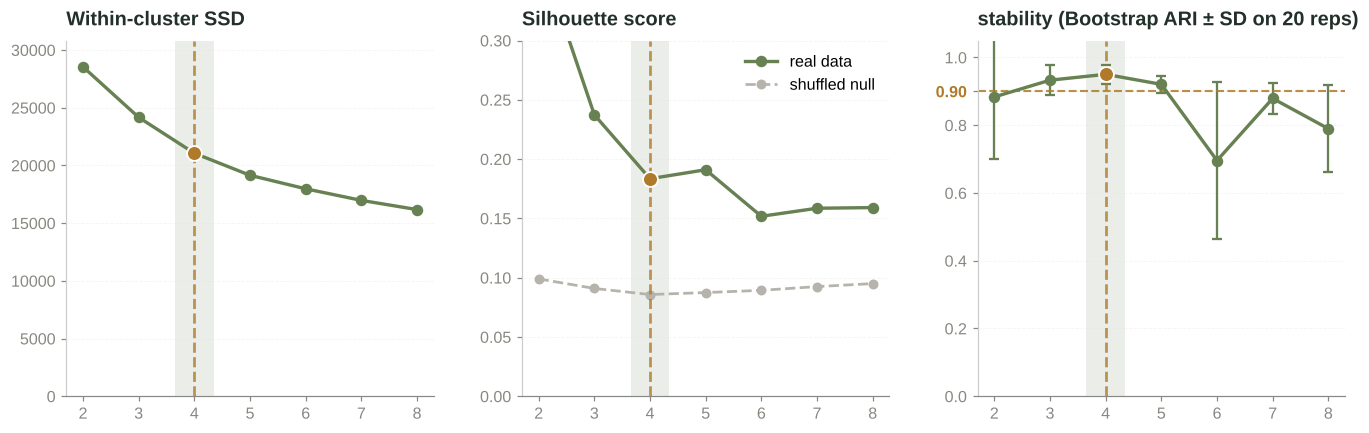

In [12]:
BIG = {"font.size": 11.5, "axes.titlesize": 13, "axes.labelsize": 11.5, "xtick.labelsize": 10.5, "ytick.labelsize": 10.5}

with plt.rc_context(BIG):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"wspace": 0.24})

    # Panel A: Elbow (within-cluster SSD)
    axes[0].plot(sel.index, sel.SSD, marker="o", markersize=6.5, lw=2.2, color="#688153")
    axes[0].set_title("Within-cluster SSD", loc="left", fontweight="bold", pad=10)
    axes[0].set_ylim(0, sel.SSD.max() * 1.08)

    # Panel B: Silhouette vs shuffled null
    axes[1].plot(sel.index, sel.silhouette, marker="o", markersize=6.5, lw=2.2, color="#688153", label="real data")
    axes[1].plot(sel.index, sel.silhouette_null, marker="o", markersize=5.5, lw=1.8, color=OTHER, ls="--", label="shuffled null")
    axes[1].set_title("Silhouette score", loc="left", fontweight="bold", pad=10)
    axes[1].set_ylim(0, 0.3)
    axes[1].legend(loc="upper right", frameon=False, fontsize=10.5)

    # Panel C: Bootstrap stability (ARI ± SD) with 0.8 and 0.90 on y-axis ticks
    axes[2].errorbar(
        sel.index, sel.stability, yerr=sel.stability_sd,
        marker="o", markersize=6.5, lw=2.2, color="#688153",
        ecolor="#688153", elinewidth=1.5, capsize=3.5, capthick=1.5,
    )
    axes[2].axhline(ARI_THRESHOLD, color=OCHRE, ls="--", lw=1.4, alpha=0.85)
    axes[2].set_title("stability (Bootstrap ARI ± SD on 20 reps)", loc="left", fontweight="bold", pad=10)
    axes[2].set_ylim(0, 1.05)

    yticks_c = [0.0, 0.2, 0.4, 0.6, 0.8, 0.90, 1.0]
    axes[2].set_yticks(yticks_c)
    axes[2].set_yticklabels(["0.0", "0.2", "0.4", "0.6", "0.8", "0.90", "1.0"])
    for val, tick_lbl in zip(yticks_c, axes[2].get_yticklabels()):
        if np.isclose(val, 0.90):
            tick_lbl.set_color(OCHRE)
            tick_lbl.set_fontweight("bold")

    r = sel.loc[K]
    for a in axes:
        # Shaded sage-green band ONLY around K (k = 4)
        a.axvspan(K - 0.35, K + 0.35, color="#e8ece4", alpha=0.85, lw=0, zorder=0)

        # Chosen k vertical line
        a.axvline(K, color=OCHRE, lw=1.8, ls="--", alpha=0.8, zorder=2)
        a.set_xticks(sel.index)

        # Clean spines and subtle horizontal grid matching previous plots
        for spine in ["top", "right"]:
            a.spines[spine].set_visible(False)
        a.spines["left"].set_color("#cccccc")
        a.spines["bottom"].set_color("#888888")
        a.grid(axis="y", linestyle="--", alpha=0.3)
        a.grid(axis="x", visible=False)

    # Highlight the chosen k=K dot in OCHRE across all three panels
    axes[0].scatter([K], [r.SSD], s=95, color=OCHRE, edgecolor="white", linewidth=1.2, zorder=5)
    axes[1].scatter([K], [r.silhouette], s=95, color=OCHRE, edgecolor="white", linewidth=1.2, zorder=5)
    axes[2].scatter([K], [r.stability], s=95, color=OCHRE, edgecolor="white", linewidth=1.2, zorder=5)

    fig.tight_layout(rect=[0, 0.04, 1, 1])
    save(fig, "04a_choose_k")

**Reading the figure** · (A) elbow, (B) silhouette against the shuffled null (grey), (C) bootstrap stability ± SD with the 0.90 threshold. The ochre line is the chosen k.

**Takeaway.** No sharp elbow. Only **k = 4** passes the rule (ARI 0.95 ± 0.03); k = 3 (0.93 ± 0.04) and k = 5 (0.92 ± 0.03) just miss it. At k = 4 the silhouette is 0.18 against 0.09 for shuffled data: the structure is real but weak, as expected for a continuum. k = 2 has the highest silhouette (0.38) but splits the species 3,560 / 559 along PC1.

## I.3 · The final k-means and the names of the morphotypes
**What this cell does.** It takes the k = 4 fit from the selection step and **relabels** the clusters M1…M4 by mean hand-wing index (M1 = most pointed wings), with one colour per morphotype for the rest of the notebook.
**Why relabel.** k-means numbers its clusters arbitrarily; ordering by hand-wing index makes the names stable and meaningful.

In [13]:
km = models[K]  # the same fit (n_init=50) that passed the stability check
# Order morphotypes by mean hand-wing index, most aerial first: M1 = most pointed wings
order_map = pd.Series(df["log_HWI"].values).groupby(km.labels_).mean().sort_values(ascending=False)
relabel = {old: new for new, old in enumerate(order_map.index)}
df["Cluster"] = np.array([relabel[l] for l in km.labels_])
centers = np.vstack([Xs[df.Cluster == c].mean(axis=0) for c in range(K)])
MT = [f"M{c + 1}" for c in range(K)]
CL_PAL = {c: PAL[c] for c in range(K)}
sizes = np.bincount(df.Cluster)
MT_N = [f"M{c + 1} (n={sizes[c]:,})" for c in range(K)]
print({MT[c]: int(sizes[c]) for c in range(K)})
XF = df[INTERNAL_MORPH_COLS].to_numpy()   # the 9 features, unscaled (Chapter III)
groups = df.Family1.values               # family of every species, for grouped folds and family checks

{'M1': 322, 'M2': 930, 'M3': 1250, 'M4': 1617}


## I.4 · The morphotypes in shape space
**What this cell does.** Every species on PC1–PC2, coloured by morphotype, with the main loadings as arrows (a biplot). It is a 2-D view of a 9-D clustering.

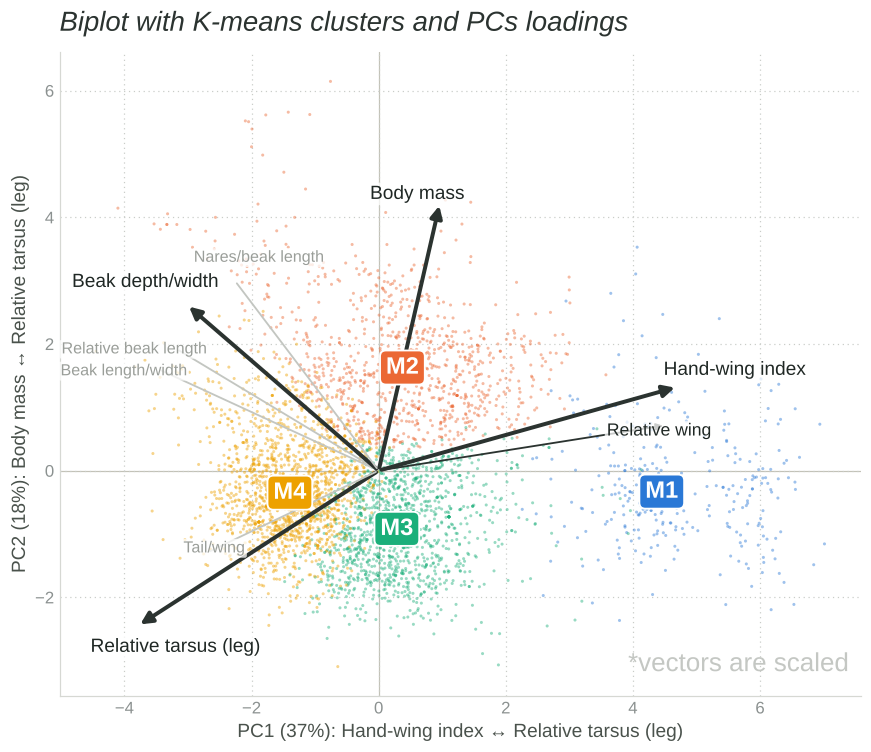

In [14]:
# The morphotypes in PCA space: key loadings as bold arrows, the rest in grey
KEY = ["log_Mass", "Beak_Depth_Width", "log_HWI", "Rel_Tarsus"]   # the axes that matter
MID = ["Rel_Wing"]                                                   # thin dark arrow
FS = dict(title=18, label=12.5, badge=15.5)

with plt.rc_context({"font.size": 12.5, "xtick.labelsize": 11, "ytick.labelsize": 11, "axes.labelsize": 12.5}):
    fig, ax = plt.subplots(figsize=(9.4, 7.6))
    cl = df["Cluster"].to_numpy()
    o_ = np.random.default_rng(SEED).permutation(len(df))
    a_, b_ = 0, 1

    ax.scatter(pcs[o_, a_], pcs[o_, b_], c=[CL_PAL[c] for c in cl[o_]], s=4, lw=0, alpha=0.45, rasterized=True)

    for c in range(K):  # morphotype badge at its median position
        m_ = cl == c
        ax.text(np.median(pcs[m_, a_]), np.median(pcs[m_, b_]), MT[c], fontsize=FS["badge"], fontweight="bold",
                color="white", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.25", fc=CL_PAL[c], ec="white", lw=1.2), zorder=6)

    sc_ = 0.9 * min(np.abs(pcs[:, a_]).max(), np.abs(pcs[:, b_]).max())  # arrows scaled to the cloud
    texts = []
    for f in INTERNAL_MORPH_COLS:
        x_, y_ = load.loc[f, f"PC{a_ + 1}"] * sc_, load.loc[f, f"PC{b_ + 1}"] * sc_
        if f in KEY:
            arrow = dict(arrowstyle="-|>", color="#2b3330", lw=2.6, mutation_scale=16)
            txt = dict(fontsize=FS["label"], color="#1f2724", zorder=7)
        elif f in MID:
            arrow = dict(arrowstyle="-|>", color="#2b3330", lw=1.2, mutation_scale=9)
            txt = dict(fontsize=11.5, color="#1f2724", zorder=7)
        else:
            arrow = dict(arrowstyle="-", color="#c3c6c1", lw=1.2)
            txt = dict(fontsize=10.5, color="#9a9e99", zorder=7)
        ax.annotate("", xy=(x_, y_), xytext=(0, 0), arrowprops=arrow, zorder=5)
        texts.append(ax.text(x_ * 1.07, y_ * 1.07, NICE[f], ha="center", va="center",
                             bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.75), **txt))
    adjust_text(texts, ax=ax)

    ax.axhline(0, color=AXIS, lw=0.8, zorder=0)
    ax.axvline(0, color=AXIS, lw=0.8, zorder=0)
    ax.grid(True, ls=(0, (1, 3)), lw=0.8, color="#c9ccc8")
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
    for s_ in ("left", "bottom"):
        ax.spines[s_].set_color("#d6d8d3")
    ax.tick_params(length=0, colors="#8b9190")

    ax.set_xlabel(f"PC{a_ + 1} ({evr[a_]:.0%}): {axis_name(f'PC{a_ + 1}')}", color="#4a524c")
    ax.set_ylabel(f"PC{b_ + 1} ({evr[b_]:.0%}): {axis_name(f'PC{b_ + 1}')}", color="#4a524c")
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_title("Biplot with K-means clusters and PCs loadings", loc="left", fontsize=FS["title"],
                 fontstyle="italic", fontweight="normal", color="#2b3330", pad=14)
    ax.text(0.985, 0.03, "*vectors are scaled", transform=ax.transAxes, ha="right", va="bottom",
            fontsize=17, color="#c4c7c3")

    save(fig, "04c_morphotypes_biplot")

**Reading the figure** · An arrow points the way a feature increases; bold arrows are the features that define the axes. A label sits at the median of its morphotype.

**Takeaway.** M1 sits apart on the right, toward long, pointed wings. M2 is up, toward heavy birds with deep beaks. M4 lies left, toward long legs and tails; M3 sits in the middle, low on PC2 (small birds). Only M1 is separated by a gap; M2, M3 and M4 overlap.

## I.5 · Block or continuum? The morphotypes on UMAP
**What these cells do.** UMAP (30 neighbours, min_dist 0.15) on the 9 standardised features, coloured by morphotype; then the same projection with three random seeds.
**Why.** UMAP keeps local neighbourhoods, so real gaps show up as islands. Distances between islands and their positions are not meaningful, which is why we check that the picture survives a change of seed.

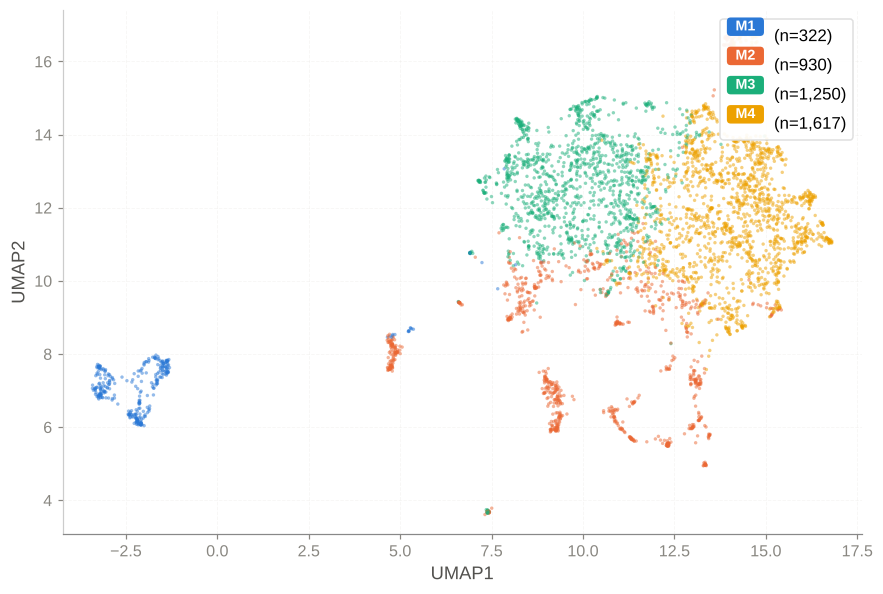

In [15]:
class MorphBadgeHandler(HandlerBase):
    """Rounded morphotype badge in the legend, aligned with the text."""
    def create_artists(self, legend, orig_handle, xdescent, ydescent, width, height, fontsize, trans):
        color, code = orig_handle
        badge_h = height * 0.92
        y_center = ydescent + height * 0.50

        badge = FancyBboxPatch(
            (xdescent, y_center - badge_h / 2.0),
            width,
            badge_h,
            boxstyle="round,pad=0.04,rounding_size=2.5",
            facecolor=color,
            edgecolor="none",
            transform=trans,
        )
        txt = Text(
            xdescent + width / 2.0,
            y_center,
            code,
            color="white",
            fontsize=fontsize * 0.85,
            fontweight="bold",
            ha="center",
            va="center",
            transform=trans,
        )
        return [badge, txt]

# UMAP projection of the 9 standardized features (Xs)
reducer = umap.UMAP(
    n_neighbors=30,
    min_dist=0.15,
    metric="euclidean",
    random_state=SEED,
)
emb_umap = reducer.fit_transform(Xs)

BIG = {"font.size": 12, "axes.labelsize": 12, "xtick.labelsize": 10.5, "ytick.labelsize": 10.5, "legend.fontsize": 11}
with plt.rc_context(BIG):
    fig, ax_km = plt.subplots(figsize=(8.2, 6.6))
    o_ = np.random.default_rng(SEED).permutation(len(df))

    # Tight limits (4% margin)
    xmin, xmax = emb_umap[:, 0].min(), emb_umap[:, 0].max()
    ymin, ymax = emb_umap[:, 1].min(), emb_umap[:, 1].max()
    xpad = (xmax - xmin) * 0.04
    ypad = (ymax - ymin) * 0.04

    # k-means morphotypes on UMAP
    ax_km.scatter(
        emb_umap[o_, 0], emb_umap[o_, 1],
        c=[CL_PAL[c] for c in df.Cluster.values[o_]],
        s=5, lw=0, alpha=0.50, rasterized=True,
    )

    badge_handles = [(CL_PAL[c], MT[c]) for c in range(K)]
    badge_labels = [f"(n={(df.Cluster.values == c).sum():,})" for c in range(K)]
    ax_km.legend(
        handles=badge_handles,
        labels=badge_labels,
        handler_map={tuple: MorphBadgeHandler()},
        loc="upper right",
        frameon=True,
        facecolor="white",
        edgecolor="#dddddd",
        framealpha=0.92,
        handlelength=2.2,
        handleheight=1.45,
        handletextpad=0.6,
        labelspacing=0.55,
        fontsize=11,
    )

    # Axis formatting
    for ax in (ax_km,):
        ax.set_xlim(xmin - xpad, xmax + xpad)
        ax.set_ylim(ymin - ypad, ymax + ypad)
        ax.set_xlabel("UMAP1")
        ax.set_ylabel("UMAP2")
        ax.set_aspect("equal", adjustable="box")
        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)
        ax.spines["left"].set_color("#cccccc")
        ax.spines["bottom"].set_color("#888888")
        ax.grid(True, linestyle="--", alpha=0.25)

    fig.tight_layout()
    save(fig, "04g_umap_kmeans")

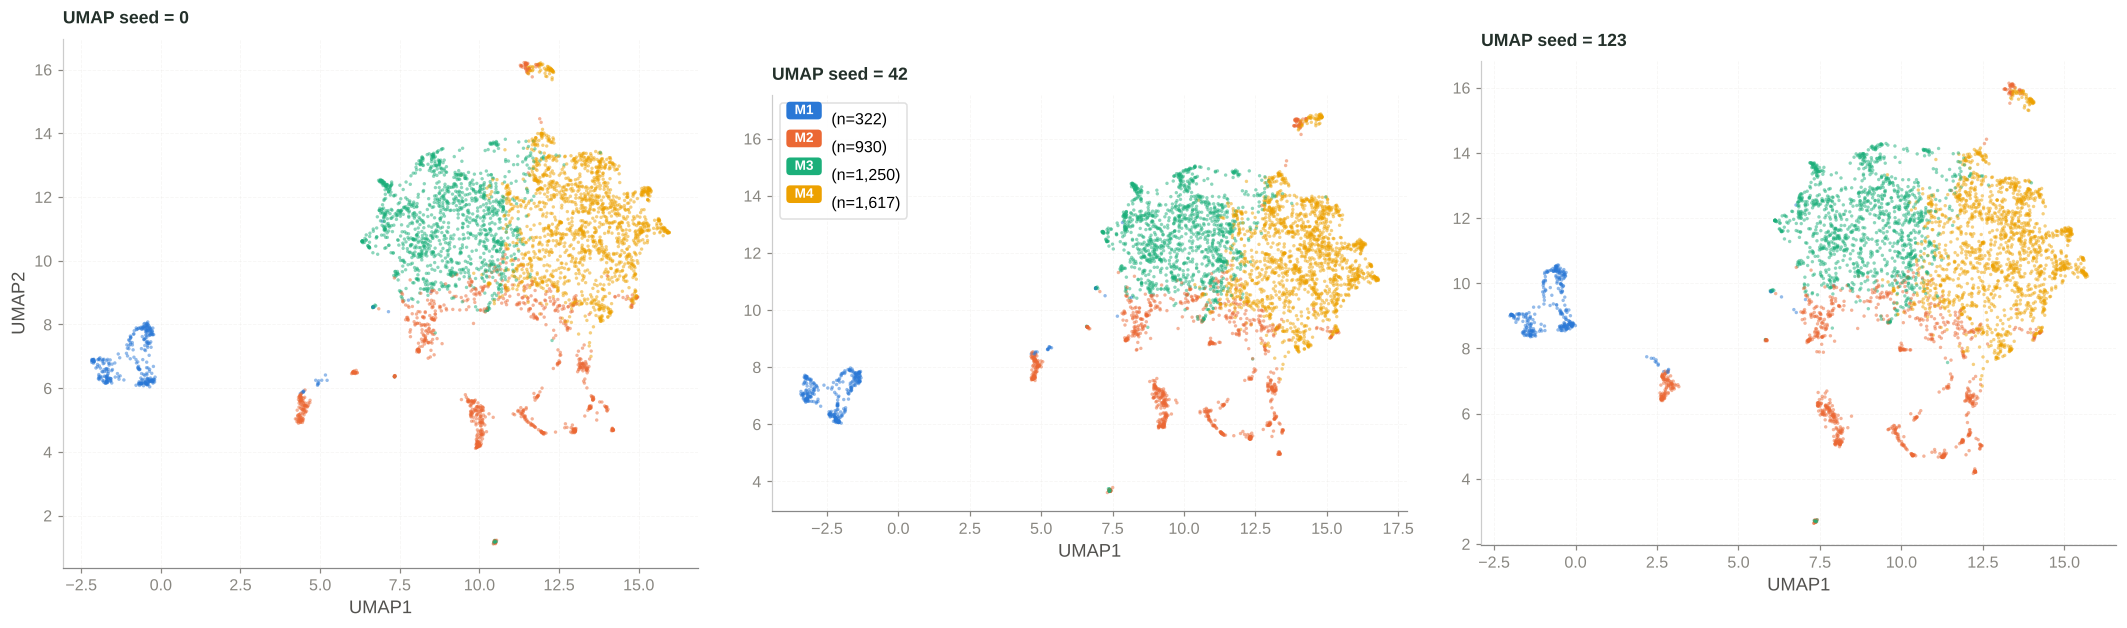

In [16]:
seeds_umap = [0, 42, 123]
ref_labels = df.Cluster.values

BIG = {"font.size": 12, "axes.labelsize": 12, "xtick.labelsize": 10.5, "ytick.labelsize": 10.5, "legend.fontsize": 10.5}
with plt.rc_context(BIG):
    fig, axes = plt.subplots(1, 3, figsize=(19.5, 6.2))
    o_ = np.random.default_rng(SEED).permutation(len(df))

    for idx, (ax, s_) in enumerate(zip(axes, seeds_umap)):
        # Re-run UMAP with a different random_state for each subplot
        emb_s = umap.UMAP(
            n_neighbors=30,
            min_dist=0.15,
            metric="euclidean",
            random_state=s_,
        ).fit_transform(Xs)

        # Individual axis limits per projection (since coordinates rotate/shift per seed)
        xmin, xmax = emb_s[:, 0].min(), emb_s[:, 0].max()
        ymin, ymax = emb_s[:, 1].min(), emb_s[:, 1].max()
        xpad = (xmax - xmin) * 0.05
        ypad = (ymax - ymin) * 0.05

        ax.scatter(
            emb_s[o_, 0], emb_s[o_, 1],
            c=[CL_PAL[c] for c in ref_labels[o_]],
            s=5, lw=0, alpha=0.50, rasterized=True,
        )

        # Show legend only on the last subplot to avoid clutter (labels/counts are identical across all 3)
        if idx == 1:
            badge_handles = [(CL_PAL[c], MT[c]) for c in range(K)]
            badge_labels = [f"(n={(ref_labels == c).sum():,})" for c in range(K)]
            ax.legend(
                handles=badge_handles,
                labels=badge_labels,
                handler_map={tuple: MorphBadgeHandler()},
                loc="upper left",
                frameon=True,
                facecolor="white",
                edgecolor="#dddddd",
                framealpha=0.92,
                handlelength=2.2,
                handleheight=1.45,
                handletextpad=0.6,
                labelspacing=0.55,
                fontsize=10.5,
            )

        ax.set_title(f"UMAP seed = {s_}", fontsize=11.5, fontweight="bold", pad=10)
        ax.set_xlim(xmin - xpad, xmax + xpad)
        ax.set_ylim(ymin - ypad, ymax + ypad)
        ax.set_xlabel("UMAP1")
        ax.set_aspect("equal", adjustable="box")
        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)
        ax.spines["left"].set_color("#cccccc")
        ax.spines["bottom"].set_color("#888888")
        ax.grid(True, linestyle="--", alpha=0.25)

    axes[0].set_ylabel("UMAP2")
    fig.tight_layout(w_pad=2.0)
    save(fig, "04i_umap_3seeds_geometry")

**Reading the figures** · **Takeaway.** M1 is a separate island under all three seeds. M2 breaks into several small satellite groups at the edge of the main cloud, and M3 and M4 share one continuous cloud with no gap between them. Same conclusion as PCA: one block (M1), the rest a continuum.

## I.6 · Anatomy of the four morphotypes (descriptive only)
These differences are guaranteed by construction (these features built the groups), so the figures name the groups; they are not evidence that the groups are real.

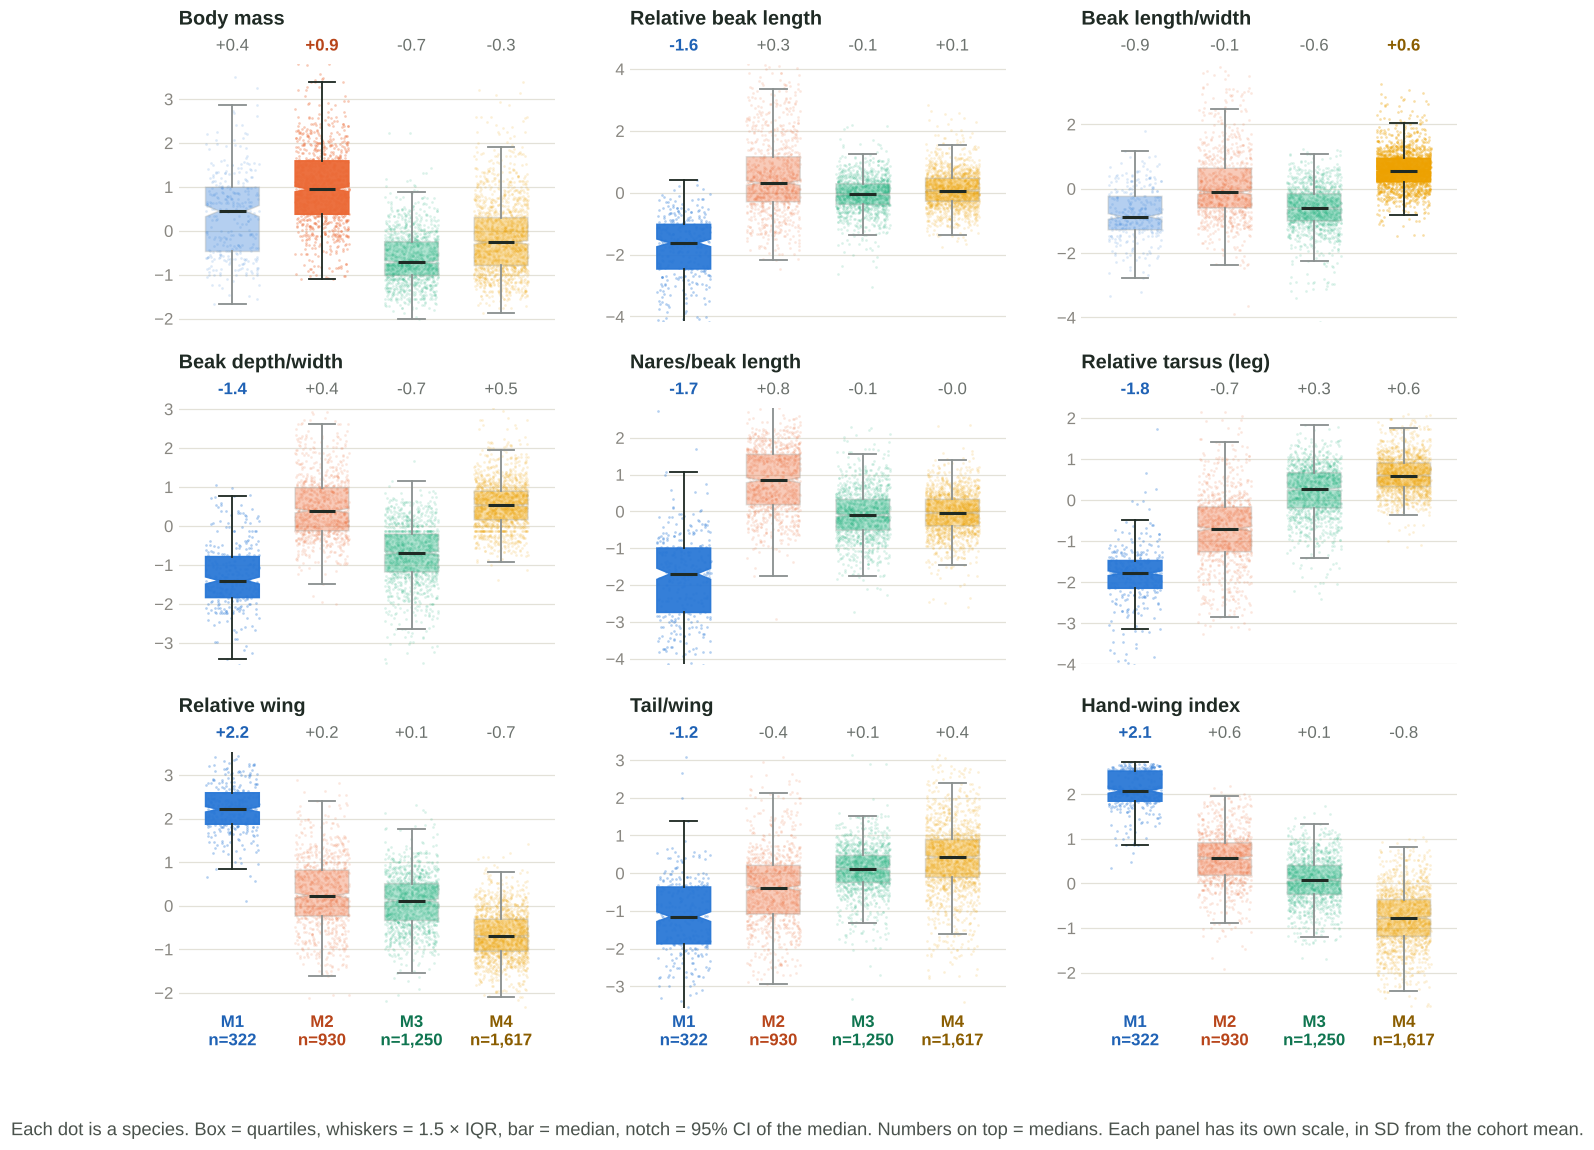

In [17]:
Z=pd.DataFrame(Xs,columns=INTERNAL_MORPH_COLS); cl=df.Cluster.values
feats=list(INTERNAL_MORPH_COLS)
NM={"log_Mass":"Body mass","Rel_Beak_Length":"Relative beak length","Beak_Aspect":"Beak length/width","Beak_Depth_Width":"Beak depth/width","Nares_Beak":"Nares/beak length","Rel_Tarsus":"Relative tarsus (leg)","Rel_Wing":"Relative wing","Tail_Wing":"Tail/wing","log_HWI":"Hand-wing index"}
sizes_=[int((cl==c).sum()) for c in range(K)]
fig,axs=plt.subplots(3,3,figsize=(15,11),gridspec_kw=dict(hspace=0.34,wspace=0.2))
rng_jit=np.random.default_rng(1)
for ax,f in zip(axs.ravel(),feats):
    data=[Z.loc[cl==c,f].values for c in range(K)]
    med=np.array([np.median(v) for v in data])
    gap=[abs(med[c]-np.mean(np.delete(med,c))) for c in range(K)]
    star=int(np.argmax(gap))
    for c,v in enumerate(data):
        a=0.35 if c==star else 0.16
        ax.scatter(c+rng_jit.uniform(-0.3,0.3,len(v)),v,s=3,color=PAL[c],alpha=a,lw=0,rasterized=True,zorder=1)
    bp=ax.boxplot(data,positions=range(K),widths=0.6,notch=True,patch_artist=True,showfliers=False,whis=1.5,zorder=4,
                  medianprops=dict(color="#1f2a24",lw=2),boxprops=dict(lw=1),whiskerprops=dict(lw=1.2),capprops=dict(lw=1.2))
    for c,b_ in enumerate(bp["boxes"]):
        b_.set_facecolor(PAL[c]); b_.set_alpha(0.95 if c==star else 0.35); b_.set_edgecolor(PAL[c] if c==star else "#a8aaa6")
    for c in range(K):
        col="#1f2a24" if c==star else "#8b9190"
        for w in (bp["whiskers"][2*c],bp["whiskers"][2*c+1],bp["caps"][2*c],bp["caps"][2*c+1]): w.set_color(col)
    ax.grid(axis="y",color="#e3e1d8",lw=0.8); ax.set_axisbelow(True); ax.grid(axis="x",visible=False)
    ax.set_xticks(range(K),[f"{MT[c]}"+chr(10)+f"n={sizes_[c]:,}" for c in range(K)])
    for t_,c_ in zip(ax.get_xticklabels(),MT_TXT): t_.set_color(c_); t_.set_fontweight("bold"); t_.set_fontsize(11)
    ax.tick_params(length=0,labelsize=11)
    if ax not in axs[-1]: ax.set_xticklabels([])
    for s_ in ax.spines.values(): s_.set_visible(False)
    ax.set_xlim(-0.6,K-0.4)
    allv=np.concatenate(data); ax.set_ylim(np.percentile(allv,0.3)-0.3,np.percentile(allv,99.7)+0.3)
    ax.set_title(f"{NM[f]}",fontsize=13,fontweight=700,color="#1f2a24",loc="left",pad=26)
    for c in range(K):
        ax.text(c,1.04,f"{med[c]:+.1f}",transform=ax.get_xaxis_transform(),ha="center",va="bottom",fontsize=11,
                fontweight=700 if c==star else 400,color=MT_TXT[c] if c==star else "#6b716d")
fig.subplots_adjust(bottom=0.1)
fig.text(0.5,-0.005,"Each dot is a species. Box = quartiles, whiskers = 1.5 × IQR, bar = median, notch = 95% CI of the median. Numbers on top = medians. Each panel has its own scale, in SD from the cohort mean.",ha="center",fontsize=12,color="#4a524c")
save(fig, "box_shape_sm", dpi=130); plt.show()

**Reading the figure** · One panel per feature, in SD from the cohort mean; every species is a dot. Box = quartiles, whiskers = 1.5 × IQR, notch = 95% CI of the median; numbers on top are medians.

**Takeaway.** M1 is the most extreme on almost every feature: long, pointed wings, short legs, short and flat beaks. M2 is the heaviest, with the longest bill in front of the nostrils. M3 is the lightest, with broad, flat beaks. M4 has long legs and tails, narrow beaks and rounded wings. M2, M3 and M4 overlap on most features.

## I.7 · Median of each feature per morphotype

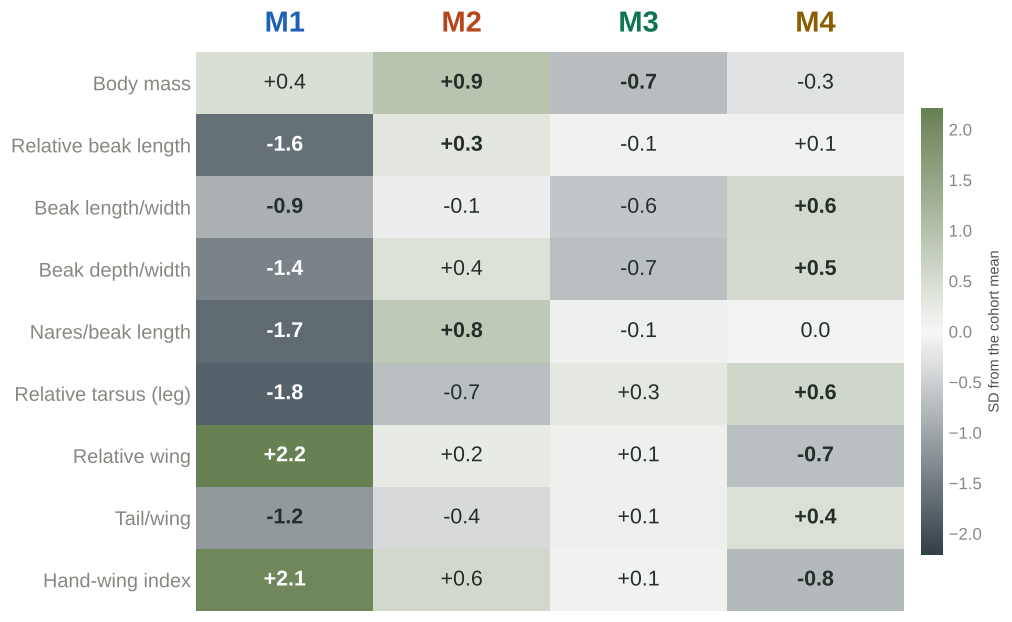

In [18]:
z_med = pd.DataFrame(Xs, columns=INTERNAL_MORPH_COLS).groupby(df.Cluster.values).median().T
for c in range(K):
    fams = df.loc[df.Cluster == c, "Family1"].value_counts().head(3).index

fig, a1 = plt.subplots(figsize=(10, 6.6))
lim = np.abs(z_med.values).max()
im1 = a1.imshow(z_med.values, cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
for i, f in enumerate(z_med.index):
    row = z_med.iloc[i].values
    for j in range(K):
        v = row[j]
        txt = f"{v:+.1f}".replace("-0.0", "0.0").replace("+0.0", "0.0")
        extreme = v == row.max() or v == row.min()          # highest and lowest of the row in bold
        a1.text(j, i, txt, ha="center", va="center", fontsize=14, fontweight="bold" if extreme else "normal",
                color="white" if abs(v) > 0.6 * lim else INK)
a1.set_yticks(range(len(z_med)), [NICE[f] for f in z_med.index], fontsize=13)
a1.set_xticks([])
a1.tick_params(length=0)
for s in a1.spines.values(): s.set_visible(False)
a1.grid(False)
for j in range(K):                                           # cluster names on top, in the cluster colour
    a1.text(j, -0.95, MT[j], ha="center", va="center", fontsize=19, fontweight="bold",
            color=["#1f62b5", "#b8451a", "#0f7550", "#8a5d00"][j], clip_on=False)
cb = fig.colorbar(im1, ax=a1, shrink=0.8, pad=0.02, label="SD from the cohort mean")
cb.outline.set_visible(False); cb.ax.tick_params(labelsize=11, length=0)
save(fig, '06_portrait_slide')

**Reading the figure** · Median of each feature per morphotype, in SD from the cohort mean (green above, slate below); the highest and lowest of each row are in bold.

**Takeaway.** **M1** (322): pointed wings (+2.2), short legs (−1.8), short, flat beak. **M2** (930): heaviest (+1.0), long nares (+0.9), deep beak. **M3** (1,250): lightest (−0.7), broad, flat beak. **M4** (1,617): long legs (+0.6), narrow beak, rounded wings (hand-wing index −0.8).

### Findings · structure
* Nine shape features, one PCA: the first four components carry 78% of the variance.
* k = 4 is the only k that passes the stability rule (bootstrap ARI 0.95); the silhouette is 0.18 against 0.09 for shuffled data, so the structure is real but weak.
* **Only the aerial morphotype (M1, 322 species) is a separate region**, in PCA and on UMAP under three seeds.
* M2, M3 and M4 share one cloud: graded types, and four is our choice of cut.

# Chapter II · Function: do the groups hunt differently?
**Last chapter → this chapter:** Chapter I found one aerial island and a continuum cut into four morphotypes from shape alone. **Question:** do they differ on variables the clustering never saw, above all the dominant technique?

**Plan.** II.1 tests the 7 external variables. II.2 shows the dominant technique per morphotype and where each technique sits in shape space. II.3 compares the morphotypes pair by pair. II.4 asks which external variables a model needs to recognise the morphotypes.

## II.1 · The test engine
**What this cell does.** It defines one test per variable type and applies Benjamini–Hochberg across all tested variables.
* **Categorical:** χ² test with **Cramér's V** (small/medium/large cut-offs 0.10/0.30/0.50 divided by √df*, so 0.06/0.17/0.29 with four morphotypes). Categories with fewer than 70 species are pooled into "Other"; the cell warns if an expected count falls below 5.
* **Continuous:** Kruskal–Wallis with **ε² = H / (N − 1)** (0.01/0.08/0.26).

**Why effect sizes.** With 4,119 species almost any difference is significant, so the effect size says whether it matters. Species-level p-values are also optimistic, because relatives are not independent.
**Why the dominant technique and not the four shares.** The shares add up to roughly 100%, so four separate tests would not be independent evidence. One χ² test on the dominant technique avoids that.

In [19]:
def magnitude(e, kind, df_star=1):
    cuts = (0.01, 0.08, 0.26) if kind == "ε²" else tuple(c / np.sqrt(max(1, df_star)) for c in (0.10, 0.30, 0.50))
    return ("negligible", "small", "medium", "large")[np.searchsorted(cuts, e, side="right")]


def _test_numeric(v, lab, **_):
    groups = [v[lab == c] for c in np.unique(lab)]
    H, p = stats.kruskal(*groups)
    return dict(
        test="Kruskal–Wallis",
        stat=H,
        df_star=1,
        effect=H / (len(v) - 1),
        effect_size="ε²",
        p=p,
        min_expected=np.nan,
    )


def _test_categorical(v, lab, var_name="", min_cat_n=15):
    cats = v.astype(int).astype(str) if np.issubdtype(v.dtype, np.number) else v.astype(str)
    tab = pd.crosstab(lab, cats)

    rare = tab.columns[tab.sum() < min_cat_n]
    if len(rare) >= 2:
        cats = np.where(np.isin(cats, rare), "Other", cats)
        tab = pd.crosstab(lab, cats)

    if tab.shape[1] < 2:
        return dict(test="χ²", stat=0.0, df_star=1, effect=0.0, effect_size="Cramér's V", p=1.0, min_expected=np.nan)

    chi2, p, _, exp = stats.chi2_contingency(tab)
    df_star = min(tab.shape) - 1
    v_stat = np.sqrt(chi2 / (tab.to_numpy().sum() * df_star))
    min_exp = float(exp.min())

    if min_exp < 5.0:
        print(f"ERROR [{var_name}]: min expected count is {min_exp:.2f} (< 5) — χ² approximation invalid, use Fisher's exact test instead.")

    return dict(
        test="χ²",
        stat=chi2,
        df_star=df_star,
        effect=v_stat,
        effect_size="Cramér's V",
        p=p,
        min_expected=min_exp,
    )


TESTS = {"num": _test_numeric, "cat": _test_categorical}


def level1(data, ext_vars, cluster_col="Cluster", min_cat_n=15):
    rows = []
    for label, col, kind, block in ext_vars:
        sub = data[[col, cluster_col]].dropna()
        res = TESTS[kind](
            sub[col].to_numpy(),
            sub[cluster_col].to_numpy(),
            var_name=col,
            min_cat_n=min_cat_n,
        )
        res["magnitude"] = magnitude(res["effect"], res["effect_size"], res["df_star"])
        rows.append(dict(block=block, variable=col, label=label, n=len(sub), **res))

    out = pd.DataFrame(rows)
    out["q"] = multipletests(out["p"], method="fdr_bh")[1] if len(out) else []
    return out

**What this cell does.** It runs the engine on the 7 external variables: dominant technique, primary lifestyle and habitat, plus four geography controls (migration, habitat density, |latitude|, range size).

In [20]:
EXT = level1(df, EXT_VARS, min_cat_n=70)
print(EXT[["block", "label", "test", "n", "effect_size", "effect", "magnitude", "min_expected", "q"]].round(3).to_string(index=False))

             block                      label           test    n effect_size  effect  magnitude  min_expected   q
foraging & ecology    Dominant technique (y4)             χ² 4119  Cramér's V   0.630      large        22.905 0.0
foraging & ecology Primary lifestyle (AVONET)             χ² 4119  Cramér's V   0.544      large        21.654 0.0
foraging & ecology                    Habitat             χ² 4071  Cramér's V   0.193     medium         7.242 0.0
geography controls                  Migration             χ² 4106  Cramér's V   0.211      small        20.277 0.0
geography controls            Habitat density             χ² 4119  Cramér's V   0.112      small        35.960 0.0
geography controls                 |Latitude| Kruskal–Wallis 4095          ε²   0.007 negligible           NaN 0.0
geography controls                 Range size Kruskal–Wallis 4095          ε²   0.032      small           NaN 0.0


**Reading the output** · **Takeaway.** All seven differ between morphotypes (q < 0.001), but the effect sizes separate them. The **dominant technique** is the strongest (V = 0.63, large), followed by primary lifestyle (0.54). Habitat (0.19) and migration (0.21) are moderate; habitat density is small (0.11). |Latitude| (ε² = 0.007) and range size (0.03) barely differ: geography adds little.

## II.2 · Which technique each morphotype uses
**What this cell does.** For each morphotype, the share of its species whose dominant technique is screening, sally, glean or bark, with a 95% confidence interval.

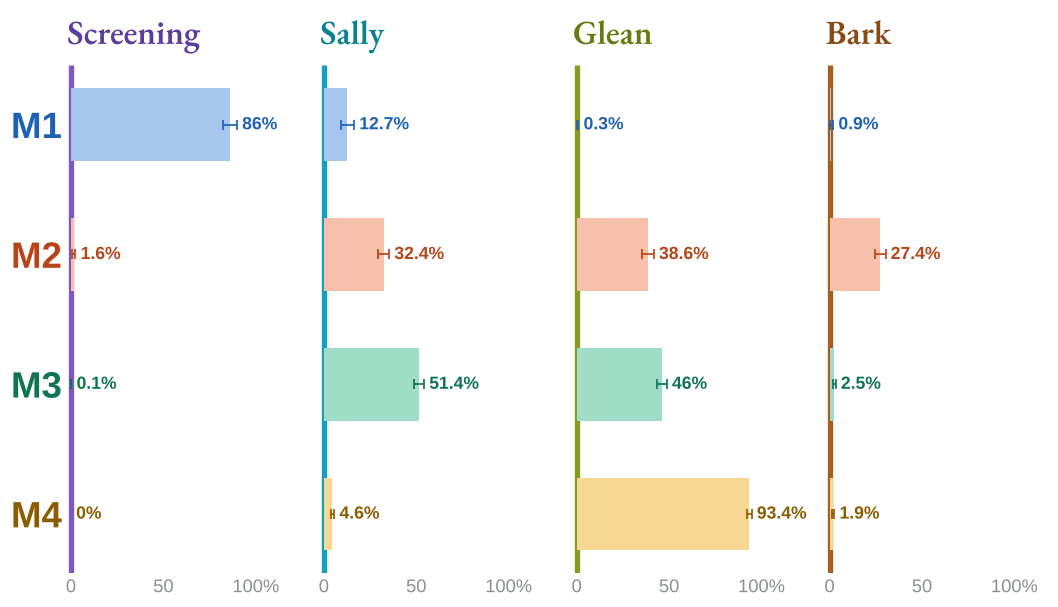

In [21]:
MIX = [
    ("Screening", "Screening", "#5b3d9e", "#7e57c2"),
    ("Sally", "Sally", "#0b8294", "#12a1b8"),
    ("Glean", "Glean", "#6a7a10", "#8a9a1a"),
    ("Bark", "Bark", "#8a4a14", "#a65f1f"),
]
SERIF_FONT = ["EB Garamond", "Georgia", "DejaVu Serif"]


def fade(color, alpha):
    rgb = np.array(to_rgb(color))
    return tuple(1 - alpha * (1 - rgb))


def normal_ci_pct(k, n, z=1.959964):
    """Standard 95% normal-approximation confidence interval in percent (clipped to [0, 100])."""
    p = k / n
    se = np.sqrt(p * (1.0 - p) / n)
    return 100.0 * p, 100.0 * max(0.0, p - z * se), 100.0 * min(1.0, p + z * se)


def style_panel(ax, title, title_col, bar_col):
    ax.set_xlim(-2, 118)
    ax.set_xticks([0, 50, 100])
    ax.set_xticklabels(["0", "50", "100%"], fontsize=12, color="#8a908b")
    ax.grid(False)
    ax.tick_params(length=0)
    ax.set_title(title, fontsize=22, fontweight="600", color=title_col, family=SERIF_FONT, pad=14)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.axvline(0, color=bar_col, lw=3.5, zorder=1, solid_capstyle="butt")


yy = np.arange(K)[::-1]
cl = df["Cluster"].to_numpy()
n_per_cl = np.bincount(cl, minlength=K)

fig, axes = plt.subplots(1, len(MIX), figsize=(11.5, 6.0), sharey=True, gridspec_kw=dict(wspace=0.14))

for ax, (guild, title, title_col, bar_col) in zip(axes, MIX):
    is_guild = (df["y4_label"] == guild).to_numpy()

    for k_, y_ in enumerate(yy):
        k_cnt = int(is_guild[cl == k_].sum())
        pct, lo, hi = normal_ci_pct(k_cnt, int(n_per_cl[k_]))

        ax.barh(y_, pct, height=0.56, color=fade(PAL[k_], 0.42), edgecolor="none", zorder=2)

        if hi > lo:
            ax.errorbar(
                pct, y_, xerr=[[pct - lo], [hi - pct]],
                fmt="none", ecolor=MT_TXT[k_], elinewidth=1.35,
                capsize=3.2, capthick=1.35, alpha=0.85, zorder=3
            )

        lbl = f"{pct:.1f}".rstrip("0").rstrip(".") + "%"
        ax.text(
            hi + 2.8, y_, lbl,
            va="center", ha="left", fontsize=11.5, fontweight="bold", color=MT_TXT[k_], zorder=4
        )

    style_panel(ax, title, title_col, bar_col)

axes[0].set_yticks(yy, MT)
for tick_lbl, col in zip(axes[0].get_yticklabels(), MT_TXT[:K]):
    tick_lbl.set_color(col)
    tick_lbl.set_fontweight("bold")
    tick_lbl.set_fontsize(24)

save(fig, "y4_share_ci")

**Reading the figure** · One panel per technique, one bar per morphotype; each morphotype's four bars add up to 100%.

**Takeaway.** **M1** is the aerial screeners (86%). **M4** is the gleaners (93%). **M3** splits between sallying (51%) and gleaning (46%). **M2** is mixed (glean 39%, sally 32%) and holds almost all the bark foragers (27%, against ≤ 3% elsewhere).

#### Where each technique sits in shape space
**What these cells do.** For each technique, a density map of its species on PC1–PC2: the darker region holds the densest 50% of the technique's species, the lighter one 88%. Dashed outlines enclose 85% of each morphotype.
**Caution.** A 2-D view of 9 features (PC1–PC2 carry 55% of the variance), and the shapes depend on the smoothing bandwidth. Descriptive only.

In [22]:
import numpy as np
from scipy.stats import gaussian_kde
from skimage.measure import find_contours


def prep_contours(E, cl, n_clusters=None, mass=0.85, bw=0.3, min_island_ratio=0.25):
    """Compute plot bounds, cluster medians, and smooth KDE contours enclosing `mass` of each cluster."""
    n_cl = K if n_clusters is None else n_clusters
    lo, hi = np.percentile(E, [0.25, 99.75], axis=0)
    pad = 0.06 * (hi - lo)
    bounds = (lo[0] - pad[0], hi[0] + pad[0], lo[1] - pad[1], hi[1] + pad[1])

    x_grid = np.linspace(bounds[0], bounds[1], 240)
    y_grid = np.linspace(bounds[2], bounds[3], 200)
    gx, gy = np.meshgrid(x_grid, y_grid)
    grid_pts = np.vstack([gx.ravel(), gy.ravel()])

    contours, medians = {}, {}
    for c in range(n_cl):
        P = E[cl == c]
        medians[c] = np.median(P, axis=0)
        kde = gaussian_kde(P.T, bw_method=bw)
        z = kde(grid_pts).reshape(gx.shape)
        lines = find_contours(z, np.quantile(kde(P.T), 1 - mass))
        if lines:
            max_len = max(len(line) for line in lines)
            contours[c] = [
                (
                    np.interp(line[:, 1], np.arange(len(x_grid)), x_grid),
                    np.interp(line[:, 0], np.arange(len(y_grid)), y_grid),
                )
                for line in lines
                if len(line) >= min_island_ratio * max_len
            ]
        else:
            contours[c] = []

    return bounds, contours, medians

In [23]:
import numpy as np
import matplotlib.pyplot as plt

Y4_SPEC = [
    ("Screening", "Aerial screening", "#5b3d9e"),
    ("Sally", "Sally", "#0b8294"),
    ("Glean", "Glean", "#6a7a10"),
    ("Bark", "Bark", "#8a4a14"),
]

PANEL_TITLE_FONT = dict(
    fontfamily=SERIF_FONT,
    fontsize=18,
    fontweight=600,
    loc="left",
)


def kde_mass_thresholds(z, dx, dy, masses=(0.50, 0.88)):
    """Return KDE density cutoffs enclosing each specified probability mass (HDR)."""
    cell_mass = z * dx * dy
    total_mass = cell_mass.sum()
    if total_mass <= 0:
        raise ValueError("KDE grid has zero probability mass.")

    cell_mass /= total_mass
    flat_density = z.ravel()
    order = np.argsort(flat_density)[::-1]
    cum_mass = np.cumsum(cell_mass.ravel()[order])

    return {
        m: flat_density[order[min(np.searchsorted(cum_mass, m), len(order) - 1)]]
        for m in masses
    }


def draw_embedding_overlay(ax, bounds, contours, medians, show_axes=True):
    """Overlay neutral slate morphotype contours and crisp median badges."""
    for c, lines in contours.items():
        for xs_, ys_ in lines:
            ax.plot(xs_, ys_, color="#68737d", lw=1.1, ls=(0, (4, 3)), alpha=0.65, zorder=6)
        ax.text(
            *medians[c],
            MT[c],
            ha="center",
            va="center",
            fontsize=8.8,
            fontweight="bold",
            color="#2b3138",
            zorder=8,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#d4d8dd", lw=0.6, alpha=0.92),
        )

    ax.set_xlim(bounds[0], bounds[1])
    ax.set_ylim(bounds[2], bounds[3])
    for spine in ("left", "bottom"):
        ax.spines[spine].set_visible(False)

    if show_axes:
        ax.grid(True)
        ax.tick_params(length=0)
    else:
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)


def plot_y4_gradient_grid(
    E,
    cl,
    y4_labels,
    map_name,
    xl,
    yl,
    core_mass=0.50,
    outer_mass=0.88,
    bw=0.22,
    contour_bw=0.34,
    show_axes=True,
    show_points=True,
):
    """Plot a calm 2x2 Highest-Density-Region (HDR) map of dominant foraging guilds (y4)."""
    bounds, contours, medians = prep_contours(E, cl, n_clusters=len(MT), bw=contour_bw)

    x_grid = np.linspace(bounds[0], bounds[1], 300)
    y_grid = np.linspace(bounds[2], bounds[3], 260)
    gx, gy = np.meshgrid(x_grid, y_grid)
    grid_pts = np.vstack([gx.ravel(), gy.ravel()])
    dx, dy = x_grid[1] - x_grid[0], y_grid[1] - y_grid[0]

    grid_rc = {
        "grid.linestyle": ":",
        "grid.linewidth": 0.65,
        "grid.color": "#dcdad2",
        "grid.alpha": 0.55,
    }

    with plt.rc_context(grid_rc):
        fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.6), sharex=True, sharey=True)

        for ax, (guild, lab, tc) in zip(axes.ravel(), Y4_SPEC):
            is_guild = np.asarray(y4_labels == guild)
            P_g = E[is_guild]
            n = len(P_g)

            if n < 3:
                ax.set_title(lab, color=tc, pad=8, **PANEL_TITLE_FONT)
                continue

            # 1. Subtle cohort silhouette
            ax.scatter(
                E[:, 0], E[:, 1],
                c="#dfddd4", s=3, lw=0, alpha=0.2, rasterized=True, zorder=1,
            )

           # 2. Within-guild KDE & gentle smoothing
            z = gaussian_kde(P_g.T, bw_method=bw)(grid_pts).reshape(gx.shape)

            # Very subtle smoothing to remove small irregularities
            #z = gaussian_filter(z, sigma=1.2)

            thresholds = kde_mass_thresholds(
                z, dx, dy, masses=(core_mass, outer_mass)
            )

            t_outer = thresholds[outer_mass]
            t_core = thresholds[core_mass]
            z_top = z.max() * 1.001

            # 3. Soft nested HDR regions
            ax.contourf(
                gx, gy, z,
                levels=[t_outer, z_top],
                colors=[tc],
                alpha=0.04,
                zorder=2
            )

            ax.contourf(
                gx, gy, z,
                levels=[t_core, z_top],
                colors=[tc],
                alpha=0.14,
                zorder=3
            )

            # Subtle outer boundary
            ax.contour(
                gx, gy, z,
                levels=[t_outer],
                colors=[tc],
                linewidths=0.1,
                alpha=0.25,
                zorder=4
            )

            # Soft inner boundary
            ax.contour(
                gx, gy, z,
                levels=[t_core],
                colors=[tc],
                linewidths=0.4,
                alpha=0.35,
                zorder=4
            )

            # 4. Crisp yet translucent individual species points
            if show_points:
                ax.scatter(
                    P_g[:, 0], P_g[:, 1],
                    s=5, c=tc, alpha=0.24, edgecolors="none", rasterized=True, zorder=5,
                )

            # 5. Neutral morphotype boundaries and median badges
            draw_embedding_overlay(ax, bounds, contours, medians, show_axes=show_axes)

            # 6. Panel title and sample size badge
            ax.set_title(lab, color=tc, pad=8, **PANEL_TITLE_FONT)
            ax.text(
                0.97, 0.95,
                f"n = {n:,} ({is_guild.mean():.0%})",
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=9.2,
                color=INK2,
                bbox=dict(boxstyle="round,pad=0.22", fc="white", ec="none", alpha=0.88),
                zorder=9,
            )

        for ax in axes[1]:
            ax.set_xlabel(xl)
        for ax in axes[:, 0]:
            ax.set_ylabel(yl)

        suptitle(
            fig,
            "Dominant foraging guilds (y4) occupy distinct regions of body-shape space",
            (
                f"{map_name} · soft shading encloses {int(outer_mass * 100)}% of each guild, "
                f"solid line encloses the {int(core_mass * 100)}% core · "
                "dashed outlines enclose 85% of each morphotype"
            ),
            y=1.01,
        )
        save(fig, f"06e_maps_y4_gradient_{map_name.lower()}")

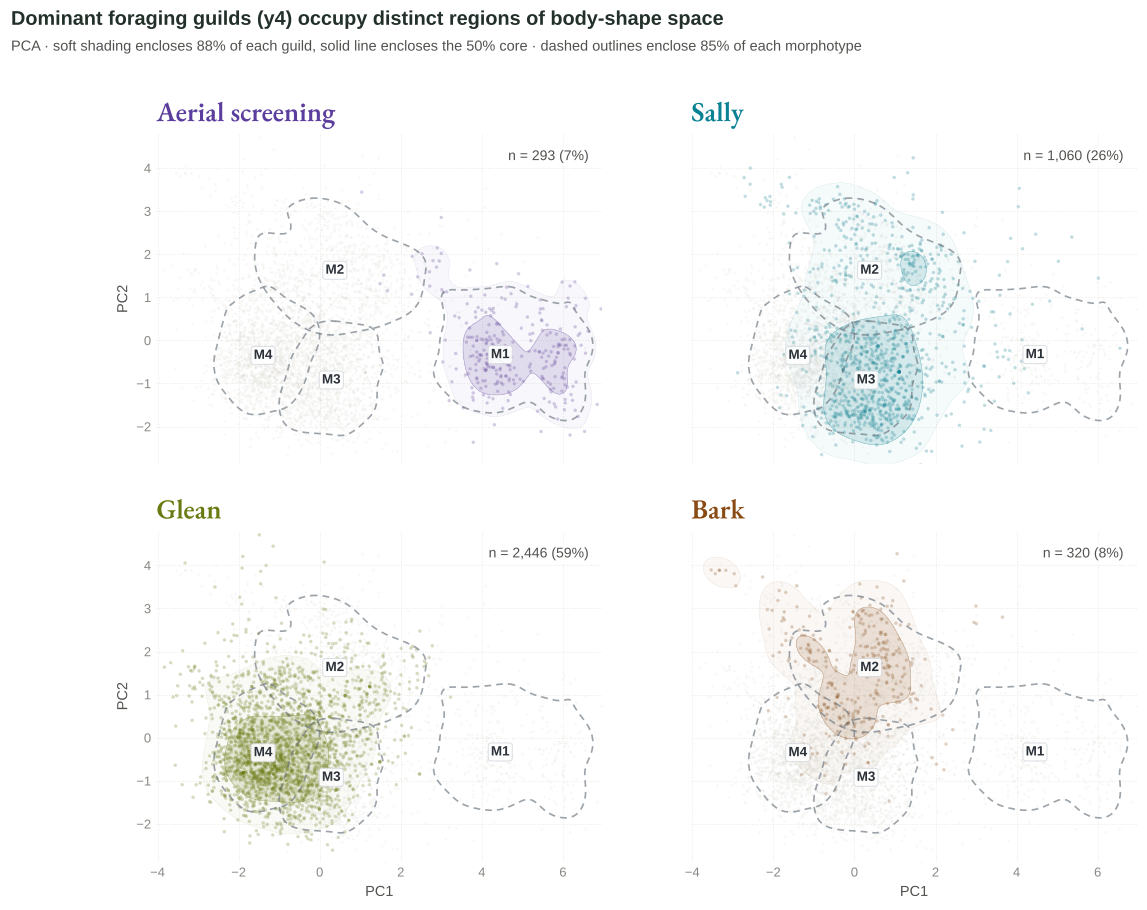

In [24]:

plot_y4_gradient_grid(pcs[:, :2], df["Cluster"].to_numpy(), df["y4_label"].to_numpy(), "PCA", "PC1", "PC2", bw=0.3)

**Reading the figure** · **Takeaway.** Screening sits only on the M1 island. Sallying has its core in M3 and spreads up into M2. Gleaning is centred on M4 and overlaps M3. Bark is concentrated in M2. Sally and glean overlap in the middle of the cloud: a gradient, not separate blocks.

## II.3 · Pairwise comparisons
**What these cells do.** For each technique and each of the 6 pairs of morphotypes, a Fisher exact test on "this technique vs any other", Holm-corrected within the technique. The effect size is the difference in share, in percentage points (pp).

In [25]:
from scipy.stats import fisher_exact

guild_order = ["Screening", "Sally", "Glean", "Bark"]
ct = pd.crosstab(df["Cluster"], df["y4_label"]).reindex(index=range(K), columns=guild_order, fill_value=0)
ct.index = MT
totals = ct.sum(axis=1)

rows = []
for g in guild_order:
    g_rows = []
    for a, b in combinations(MT, 2):
        ga, gb = int(ct.loc[a, g]), int(ct.loc[b, g])
        tab = [[ga, int(totals[a]) - ga], [gb, int(totals[b]) - gb]]
        _, p_f = fisher_exact(tab)
        pct_a, pct_b = 100.0 * ga / totals[a], 100.0 * gb / totals[b]
        g_rows.append(
            dict(
                guild=g,
                pair=f"{a} vs {b}",
                pct_a=pct_a,
                pct_b=pct_b,
                diff_pp=pct_a - pct_b,
                p=p_f,
            )
        )

    p_holm = multipletests([r["p"] for r in g_rows], method="holm")[1]
    for r, ph in zip(g_rows, p_holm):
        r["p_holm"] = ph
    rows.extend(g_rows)

pw_df = pd.DataFrame(rows)
print(pw_df.round({"pct_a": 1, "pct_b": 1, "diff_pp": 1, "p": 4, "p_holm": 4}).to_string(index=False))

    guild     pair  pct_a  pct_b  diff_pp      p  p_holm
Screening M1 vs M2   86.0    1.6     84.4 0.0000  0.0000
Screening M1 vs M3   86.0    0.1     85.9 0.0000  0.0000
Screening M1 vs M4   86.0    0.0     86.0 0.0000  0.0000
Screening M2 vs M3    1.6    0.1      1.5 0.0000  0.0001
Screening M2 vs M4    1.6    0.0      1.6 0.0000  0.0000
Screening M3 vs M4    0.1    0.0      0.1 0.4360  0.4360
    Sally M1 vs M2   12.7   32.4    -19.6 0.0000  0.0000
    Sally M1 vs M3   12.7   51.4    -38.7 0.0000  0.0000
    Sally M1 vs M4   12.7    4.6      8.1 0.0000  0.0000
    Sally M2 vs M3   32.4   51.4    -19.1 0.0000  0.0000
    Sally M2 vs M4   32.4    4.6     27.7 0.0000  0.0000
    Sally M3 vs M4   51.4    4.6     46.8 0.0000  0.0000
    Glean M1 vs M2    0.3   38.6    -38.3 0.0000  0.0000
    Glean M1 vs M3    0.3   46.0    -45.7 0.0000  0.0000
    Glean M1 vs M4    0.3   93.4    -93.1 0.0000  0.0000
    Glean M2 vs M3   38.6   46.0     -7.4 0.0006  0.0006
    Glean M2 vs M4   38.6   93.

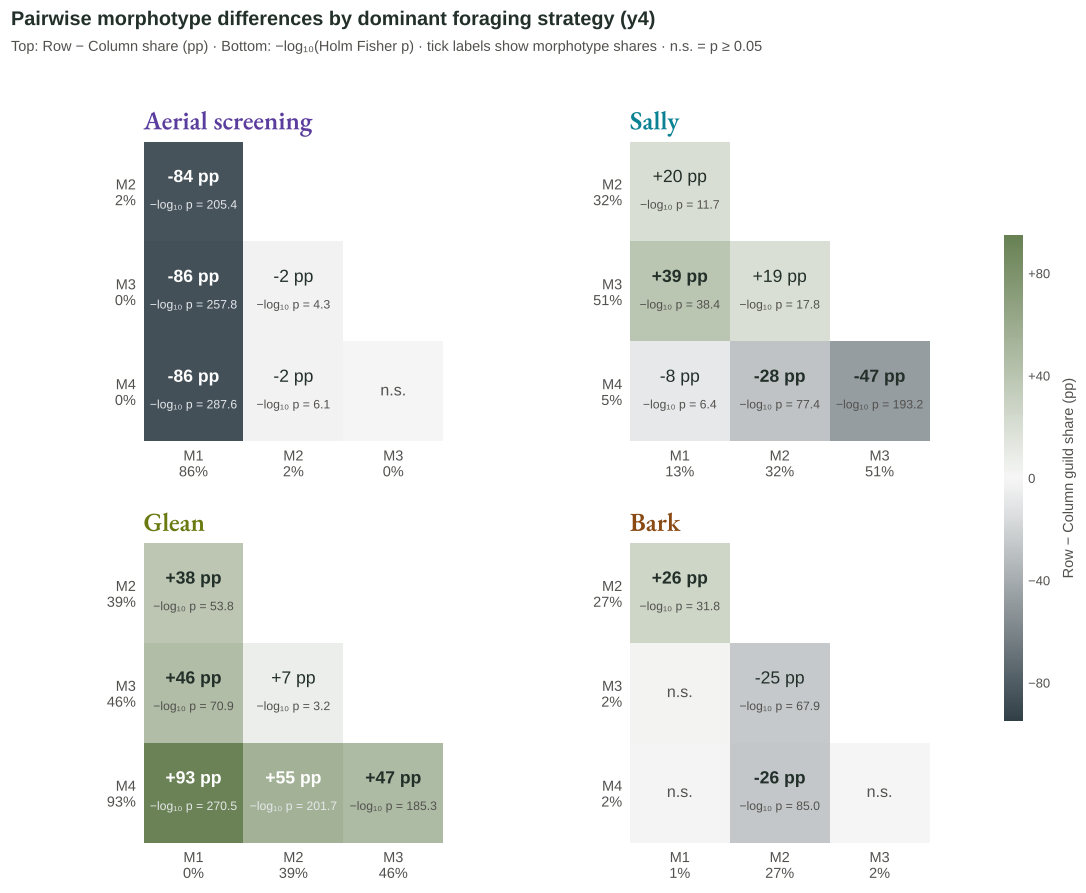

In [26]:
from matplotlib.colors import TwoSlopeNorm
import numpy as np
import matplotlib.pyplot as plt

Y4_SPEC = [
    ("Screening", "Aerial screening", "#5b3d9e"),
    ("Sally", "Sally", "#0b8294"),
    ("Glean", "Glean", "#6a7a10"),
    ("Bark", "Bark", "#8a4a14"),
]
PANEL_TITLE_FONT = dict(fontfamily=SERIF_FONT, fontsize=17, fontweight=600, loc="left")

morphs = list(MT)
k_m = len(morphs)
totals = ct.sum(axis=1)
shares_pct = ct.div(totals, axis=0) * 100.0

fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.5))
fig.subplots_adjust(left=0.09, right=0.84, top=0.84, bottom=0.09, wspace=0.28, hspace=0.34)
norm = TwoSlopeNorm(vmin=-95, vcenter=0, vmax=95)

for ax, (guild, lab, tc) in zip(axes.ravel(), Y4_SPEC):
    ax.grid(False)
    sub = pw_df[pw_df["guild"] == guild]

    diff_mat = np.full((k_m - 1, k_m - 1), np.nan)
    pholm_mat = np.full((k_m - 1, k_m - 1), np.nan)
    nlp_mat = np.full((k_m - 1, k_m - 1), np.nan)

    for _, r_ in sub.iterrows():
        a, b = r_["pair"].split(" vs ")
        i, j = morphs.index(a), morphs.index(b)
        r_idx, c_idx = j - 1, i

        ph = float(r_["p_holm"])
        diff_mat[r_idx, c_idx] = -r_["diff_pp"]  # Row (b) - Column (a)
        pholm_mat[r_idx, c_idx] = ph
        if ph < 0.05:
            nlp_mat[r_idx, c_idx] = 308.0 if ph <= 1e-308 else -np.log10(ph)

    im = ax.imshow(diff_mat, cmap=DIV, norm=norm, aspect="equal")

    for r_idx in range(k_m - 1):
        for c_idx in range(r_idx + 1):
            ph = pholm_mat[r_idx, c_idx]
            if ph >= 0.05:
                ax.text(
                    c_idx,
                    r_idx,
                    "n.s.",
                    ha="center",
                    va="center",
                    fontsize=10.5,
                    color=INK2,
                )
                continue

            val = diff_mat[r_idx, c_idx]
            nlp = nlp_mat[r_idx, c_idx]
            is_dark = abs(val) > 50
            txt_main = "white" if is_dark else INK
            txt_sub = "#e6e8eb" if is_dark else INK2

            pp_str = "0 pp" if abs(val) < 0.5 else f"{val:+.0f} pp"
            p_str = "−log₁₀ p > 308" if ph <= 1e-308 else f"−log₁₀ p = {nlp:.1f}"

            ax.text(
                c_idx,
                r_idx - 0.14,
                pp_str,
                ha="center",
                va="center",
                fontsize=11.5,
                fontweight="bold" if abs(val) >= 25 else "normal",
                color=txt_main,
            )
            ax.text(
                c_idx,
                r_idx + 0.14,
                p_str,
                ha="center",
                va="center",
                fontsize=8.0,
                color=txt_sub,
            )

    g_shares = shares_pct[guild]
    x_labels = [f"{m}\n{g_shares[m]:.0f}%" for m in morphs[:-1]]
    y_labels = [f"{m}\n{g_shares[m]:.0f}%" for m in morphs[1:]]

    ax.set_xticks(range(k_m - 1), x_labels)
    ax.set_yticks(range(k_m - 1), y_labels)
    ax.tick_params(colors=INK2, labelsize=9.5, length=0, pad=5)
    ax.set_title(lab, color=tc, pad=8, **PANEL_TITLE_FONT)

    for sp in ax.spines.values():
        sp.set_visible(False)

cax = fig.add_axes([0.87, 0.22, 0.016, 0.52])
cbar = fig.colorbar(im, cax=cax)
cbar.outline.set_visible(False)
cbar.set_ticks([-80, -40, 0, 40, 80])
cbar.set_ticklabels(["−80", "−40", "0", "+40", "+80"])
cbar.set_label("Row − Column guild share (pp)", fontsize=9.5, color=INK2, labelpad=8)
cbar.ax.tick_params(labelsize=8.5, colors=INK2, length=0)

suptitle(
    fig,
    "Pairwise morphotype differences by dominant foraging strategy (y4)",
    "Top: Row − Column share (pp) · Bottom: −log₁₀(Holm Fisher p) · "
    "tick labels show morphotype shares · n.s. = p ≥ 0.05",
    y=0.98,
)
save(fig, "06j_y4_pairwise_fisher_holm")

**Reading the figure** · Each cell compares the row morphotype with the column morphotype: colour and top number = row − column share (pp), bottom = −log₁₀ of the Holm p; n.s. = not significant.

**Takeaway.** 20 of 24 comparisons differ. The four that do not involve techniques almost absent from both groups: screening M3 vs M4, and bark among M1, M3 and M4. The largest gaps: gleaning M4 vs M1 (+93 pp) and vs M2 (+55 pp), sallying M3 vs M4 (+47 pp), bark M2 vs every other group (+25 to +27 pp). M2 and M3 glean almost equally (7 pp).

## II.4 · What a model needs to recognise the morphotypes (surrogate)
**What these cells do.** Four classifiers predict the morphotype from the 7 external variables alone, with 5 folds that hold out whole families, scored by balanced accuracy (chance = 0.25). The best one is then explained by permutation importance (the drop in balanced accuracy when one variable is shuffled), plotted against the univariate effect sizes from II.1.
**Why.** II.1 tests one variable at a time; the surrogate shows which variables still matter once the others are known.

Surrogate model ranking (5-fold StratifiedGroupKFold by Family1, N = 4,049):
                   model  bal_acc  bal_acc_sd
           Random Forest    0.597       0.071
     Logistic Lasso (L1)    0.593       0.060
 Decision Tree (depth=5)    0.593       0.071
Logistic Regression (L2)    0.591       0.061
       Majority baseline    0.250       0.000

Top model selected for 06b: Random Forest


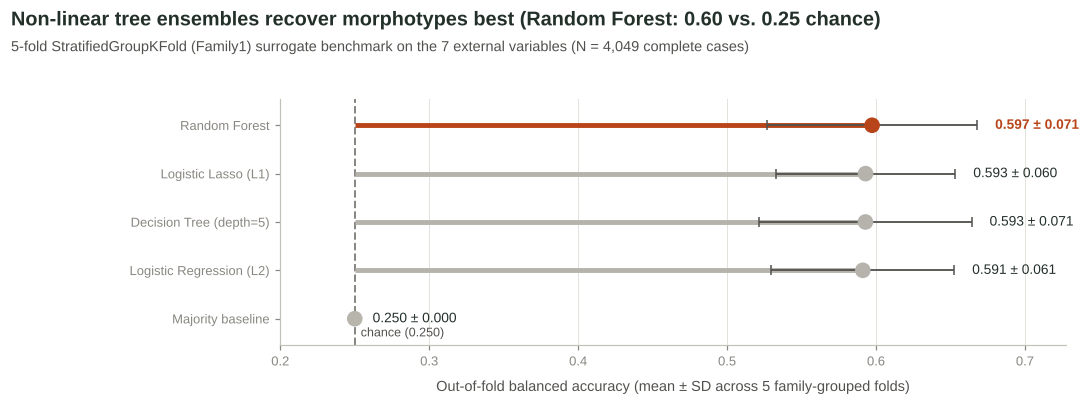

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# 1. Complete-case dataset built directly from Chapter 0's EXT_VARS
feat_cols = [col for _, col, _, _ in EXT_VARS]
cat_cols = [col for _, col, kind, _ in EXT_VARS if kind == "cat"]
num_cols = [col for _, col, kind, _ in EXT_VARS if kind == "num"]

sub = df.loc[df[feat_cols + ["Cluster", "Family1"]].notna().all(axis=1)].reset_index(drop=True)
X_sub = sub[feat_cols]
y_cl = sub["Cluster"].to_numpy()

# 2. Shared preprocessing + candidate surrogate models (all class-balanced)
prep_surr = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("num", StandardScaler(), num_cols),
])

surrogate_models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1
    ),
    "Logistic Regression (L2)": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=SEED
    ),
    "Logistic Lasso (L1)": LogisticRegression(
        penalty="l1", solver="saga", C=1.0, max_iter=3000, class_weight="balanced", random_state=SEED
    ),
    "Decision Tree (depth=5)": DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=10, class_weight="balanced", random_state=SEED
    ),
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
}

# 3. 5-fold StratifiedGroupKFold benchmark grouped by Family1 (balanced accuracy only)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(sgkf.split(X_sub, y_cl, groups=sub["Family1"]))
fitted_pipes = {name: [] for name in surrogate_models}
rank_rows = []

for name, clf in surrogate_models.items():
    fold_bacc = []
    for tr, te in folds:
        pipe = Pipeline([("prep", clone(prep_surr)), ("clf", clone(clf))])
        pipe.fit(X_sub.iloc[tr], y_cl[tr])
        fitted_pipes[name].append(pipe)
        fold_bacc.append(balanced_accuracy_score(y_cl[te], pipe.predict(X_sub.iloc[te])))

    rank_rows.append(
        dict(model=name, bal_acc=np.mean(fold_bacc), bal_acc_sd=np.std(fold_bacc))
    )

rank_df = pd.DataFrame(rank_rows).sort_values("bal_acc", ascending=True).reset_index(drop=True)
best_model_name = rank_df.iloc[-1]["model"]
best_acc = float(rank_df.iloc[-1]["bal_acc"])

print(f"Surrogate model ranking (5-fold StratifiedGroupKFold by Family1, N = {len(sub):,}):")
print(rank_df.iloc[::-1].round(3).to_string(index=False))
print(f"\nTop model selected for 06b: {best_model_name}")

# 4. Horizontal lollipop comparison chart
fig, ax = plt.subplots(figsize=(10.2, 3.8))
fig.subplots_adjust(left=0.25, right=0.95, top=0.77, bottom=0.18)

yy = np.arange(len(rank_df))
HI_COL = globals().get("MT_TXT", ["#1f62b5", "#b8451a"])[1]
cols = [
    HI_COL if m == best_model_name else ("#b8b5ad" if "baseline" in m else OTHER)
    for m in rank_df["model"]
]

ax.axvline(0.25, color=MUTED, lw=1.3, ls="--", zorder=1)
ax.hlines(yy, 0.25, rank_df["bal_acc"], color=cols, lw=3.2, zorder=2)
ax.errorbar(
    rank_df["bal_acc"], yy, xerr=rank_df["bal_acc_sd"],
    fmt="none", ecolor=INK2, elinewidth=1.2, capsize=3, zorder=3,
)
ax.scatter(rank_df["bal_acc"], yy, color=cols, s=85, zorder=4)

for yi, (_, r) in zip(yy, rank_df.iterrows()):
    is_best = r["model"] == best_model_name
    ax.text(
        r["bal_acc"] + r["bal_acc_sd"] + 0.012, yi,
        f"{r['bal_acc']:.3f} ± {r['bal_acc_sd']:.3f}",
        va="center", fontsize=9,
        fontweight="bold" if is_best else "normal",
        color=HI_COL if is_best else INK,
    )

ax.text(0.254, -0.42, "chance (0.250)", fontsize=8.2, color=INK2, va="bottom")
ax.set_yticks(yy, rank_df["model"])
ax.set_ylim(-0.55, len(rank_df) - 0.45)
ax.set_xlim(0.20, rank_df["bal_acc"].max() + 0.13)
ax.set_xlabel("Out-of-fold balanced accuracy (mean ± SD across 5 family-grouped folds)", fontsize=9.5, labelpad=8)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRID, linewidth=0.6)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)

suptitle(
    fig,
    f"Non-linear tree ensembles recover morphotypes best ({best_model_name}: {best_acc:.2f} vs. 0.25 chance)",
    f"5-fold StratifiedGroupKFold (Family1) surrogate benchmark on the 7 external variables (N = {len(sub):,} complete cases)",
    y=0.98,
)
save(fig, "06a_surrogate_model_ranking")

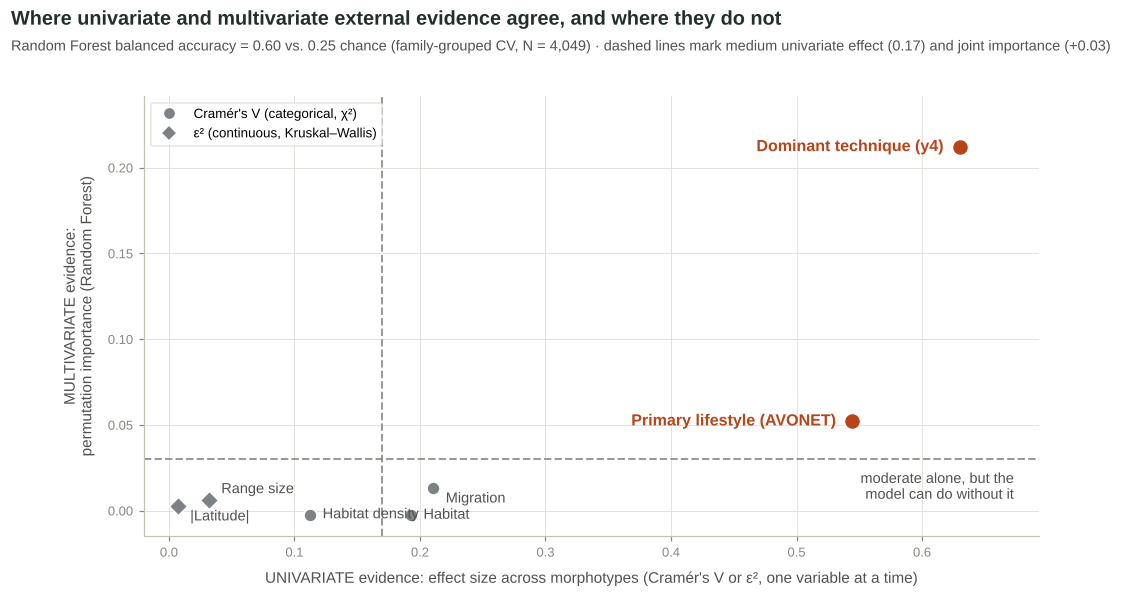

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.inspection import permutation_importance

# 1. Compute OOF permutation importance using the already-fitted winning model from 06a
perm_folds = [
    permutation_importance(
        pipe, X_sub.iloc[te], y_cl[te],
        scoring="balanced_accuracy", n_repeats=10, random_state=SEED + fold, n_jobs=-1,
    ).importances_mean
    for fold, ((_, te), pipe) in enumerate(zip(folds, fitted_pipes[best_model_name]))
]

surr_df = pd.DataFrame({"variable": feat_cols, "perm_imp": np.mean(perm_folds, axis=0)})
plot_df = surr_df.merge(EXT[["variable", "label", "effect", "effect_size"]], on="variable", how="inner")

# 2. 2D Quadrant Plot: Univariate effect size (EXT) vs. Joint permutation importance
X_THRESH = 0.17
Y_THRESH = 0.03
HI_COL = globals().get("MT_TXT", ["#1f62b5", "#b8451a"])[1]
plot_df["holds_both"] = (plot_df["effect"] >= X_THRESH) & (plot_df["perm_imp"] >= Y_THRESH)

x_max = max(0.68, float(plot_df["effect"].max()) * 1.10)
y_max = max(0.24, float(plot_df["perm_imp"].max()) * 1.14)

fig, ax = plt.subplots(figsize=(10.5, 5.2))
ax.axvline(X_THRESH, color=MUTED, lw=1.3, ls="--", alpha=0.85, zorder=1)
ax.axhline(Y_THRESH, color=MUTED, lw=1.3, ls="--", alpha=0.85, zorder=1)

NUDGES = {
    "|Latitude|": (0.010, -0.002, "left", "top"),
    "Range size": (0.010, 0.002, "left", "bottom"),
    "Habitat density": (0.010, 0.0, "left", "center"),
    "Habitat": (0.010, 0.0, "left", "center"),
    "Migration": (0.010, -0.002, "left", "top"),
    "Primary lifestyle (AVONET)": (-0.013, 0.0, "right", "center"),
    "Dominant technique (y4)": (-0.013, 0.0, "right", "center"),
}

for _, r in plot_df.iterrows():
    hi = r["holds_both"]
    is_cat = r["effect_size"] == "Cramér's V"
    ax.scatter(
        r["effect"], r["perm_imp"],
        marker="o" if is_cat else "D",
        s=115 if hi else 75,
        color=HI_COL if hi else "#7d8285",
        edgecolor="white", linewidth=1.2, zorder=4 if hi else 3,
    )
    dx, dy, ha, va = NUDGES.get(r["label"], (0.010, 0.0, "left", "center"))
    ax.text(
        r["effect"] + dx, r["perm_imp"] + dy, r["label"],
        fontsize=10.5 if hi else 9.5,
        fontweight="bold" if hi else "normal",
        color=HI_COL if hi else INK2,
        ha=ha, va=va, zorder=5,
    )

ax.text(
    x_max - 0.02, Y_THRESH - 0.007,
    "moderate alone, but the\nmodel can do without it",
    fontsize=9.5, color=INK2, ha="right", va="top",
)

metric_handles = [
    Line2D([], [], linestyle="none", marker="o", markersize=8, markerfacecolor="#7d8285",
           markeredgecolor="white", label="Cramér's V (categorical, χ²)"),
    Line2D([], [], linestyle="none", marker="D", markersize=7.5, markerfacecolor="#7d8285",
           markeredgecolor="white", label="ε² (continuous, Kruskal–Wallis)"),
]
ax.legend(handles=metric_handles, loc="upper left", frameon=True, facecolor="white", edgecolor=GRID, fontsize=8.8)

ax.set_xlim(-0.02, x_max)
ax.set_ylim(-0.015, y_max)
ax.set_xlabel("UNIVARIATE evidence: effect size across morphotypes (Cramér's V or ε², one variable at a time)", fontsize=10, labelpad=8)
ax.set_ylabel(f"MULTIVARIATE evidence:\npermutation importance ({best_model_name})", fontsize=10, labelpad=8)
ax.grid(True, color=GRID, linewidth=0.6)

suptitle(
    fig,
    "Where univariate and multivariate external evidence agree, and where they do not",
    f"{best_model_name} balanced accuracy = {best_acc:.2f} vs. 0.25 chance (family-grouped CV, N = {len(sub):,}) · "
    "dashed lines mark medium univariate effect (0.17) and joint importance (+0.03)",
    y=1.03,
)
save(fig, "06b_surrogate_univariate_vs_multivariate_2d")

**Reading the figures** · **Takeaway.** All four models reach about 0.60 balanced accuracy on unseen families (0.25 by chance), so the result does not depend on the model. The random forest relies almost entirely on the **dominant technique** (+0.21) and, less, on primary lifestyle (+0.05). Habitat and migration differ moderately on their own but add nothing once these are known; geography adds nothing.

### Findings · Chapter II
* All 7 external variables differ (q < 0.001), but only the **dominant technique** (V = 0.63) and primary lifestyle (0.54) differ strongly; geography is small to negligible.
* **The island is aerial screening:** 86% of M1, at most 2% elsewhere.
* **The continuum is a sally–glean gradient:** M3 is 51% sally, M4 93% glean; M2 mixes and holds the bark foragers (27%).
* Pairwise, 20 of 24 comparisons differ after Holm; the exceptions are techniques nearly absent from both groups.
* From external variables only, a model recognises the morphotype on unseen families (balanced accuracy 0.60, chance 0.25), almost entirely through the dominant technique.
* Species-level p-values are optimistic (relatives are not independent); the effect sizes carry the result.

# Chapter III · Stress test: does shape predict the technique on lineages never seen?
**Last chapter → this chapter:** the morphotypes hunt differently, but groups are our own construction. **Question:** can the *raw features*, with no clusters involved, predict a bird's main technique for families (and orders) the model never trained on? **Why it matters:** a rule that only works on relatives of the training birds would be ancestry in disguise; a rule that transfers to new lineages points to convergence, the same body–function link evolving again and again.

## III.1 · Predicting the main technique: models, folds and the leakage test
**The target.** The dominant technique from Chapter 0: glean 2,446 species (59%), sally 1,060 (26%), bark 320 (8%), aerial screening 293 (7%). A four-class problem; many birds are mixtures, so the label is a simplification.
**What this cell does.**
- **Two models.** Multinomial logistic regression (standardised features, balanced class weights): linear boundaries. Random forest (400 trees, ≥ 3 species per leaf, balanced subsamples): thresholds and interactions.
- **Two splits.** *Naive* folds (`StratifiedKFold`) put relatives on both sides; *family* folds (`StratifiedGroupKFold`) hold out whole families.
- 5 folds × 3 repeats. Out-of-fold probabilities are pooled within each repeat and scored; we report the mean over the 3 repeats.
- **Shuffled-label baseline:** the same models and family folds with permuted labels (3 permutations).

**Metrics.** Each technique against the rest, from the probabilities: *ROC-AUC* (0.5 = chance) and *PR-AUC* (no skill = the technique's share of species). *Macro* = the mean over the four techniques.
**Why two splits.** If the forest beats the linear model only under naive folds, its extra skill is memorising lineages. The naive − family gap measures that leak.

In [29]:
# Reuse STRAT_COLS and STRAT_LAB from earlier cells
assert df[STRAT_COLS].notna().all().all(), "Missing values in STRAT_COLS would corrupt argmax labels"
y4 = df[STRAT_COLS].to_numpy().argmax(axis=1)
counts4 = np.bincount(y4, minlength=len(STRAT_COLS))
print("Main technique counts:", dict(zip(STRAT_LAB, counts4)), "| shares:", dict(zip(STRAT_LAB, (counts4 / len(y4)).round(3))))

MODELS = {
    "Logistic regression": lambda s: make_pipeline(
        StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=3000, random_state=s)
    ),
    "Random forest": lambda s: RandomForestClassifier(
        400, min_samples_leaf=3, class_weight="balanced_subsample", random_state=s, n_jobs=-1
    ),
}
M_COL = {"Logistic regression": OCHRE, "Random forest": FOREST}
SCHEMES = {
    "naive (StratifiedKFold)": lambda s: StratifiedKFold(5, shuffle=True, random_state=s),
    "by family (StratifiedGroupKFold)": lambda s: StratifiedGroupKFold(5, shuffle=True, random_state=s),
}
SN, SF = list(SCHEMES)
HEAD = ["macro_roc", "macro_pr"]


def metrics4(y, P):
    """Macro and per-class ROC/PR AUC from class probabilities P (rows = species, cols = 4 techniques)."""
    out, rocs, prs = {}, [], []
    for c, lab in enumerate(STRAT_LAB):
        y_bin = y == c
        ok = 0 < y_bin.sum() < len(y)
        roc = roc_auc_score(y_bin, P[:, c]) if ok else np.nan
        pr = average_precision_score(y_bin, P[:, c]) if ok else np.nan
        out[f"roc_{lab}"], out[f"pr_{lab}"] = roc, pr
        rocs.append(roc)
        prs.append(pr)
    out["macro_roc"] = np.nanmean(rocs)
    out["macro_pr"] = np.nanmean(prs)
    return out


def eval_oof(make_model, splitter, X, y, groups, seed, record_folds=False):
    """Fit 5-fold CV and return pooled OOF probabilities plus optional per-fold metrics."""
    P = np.zeros((len(y), len(STRAT_COLS)))
    fold_rows = []
    for f_, (tr, te) in enumerate(splitter(seed).split(X, y, groups)):
        mdl = make_model(seed).fit(X[tr], y[tr])
        P[np.ix_(te, mdl.classes_)] = mdl.predict_proba(X[te])
        if record_folds:
            fold_rows.append(dict(rep=seed, fold=f_, **metrics4(y[te], P[te])))
    return P, fold_rows


cv_rows, OOF = [], {}
for sname, splitter in SCHEMES.items():
    for mname, make in MODELS.items():
        for rep in range(3):
            P, _ = eval_oof(make, splitter, XF, y4, groups, seed=rep, record_folds=False)
            cv_rows.append(dict(scheme=sname, model=mname, rep=rep, **metrics4(y4, P)))
            if rep == 0:
                OOF[(sname, mname)] = P

cv = pd.DataFrame(cv_rows)
print(cv.groupby(["model", "scheme"])[HEAD].agg(["mean", "std"]).round(3).to_string())

scheme_means = cv.groupby(["model", "scheme"])[HEAD].mean().unstack("scheme")
gap = pd.DataFrame({f"{c} gap (naive − family)": scheme_means[(c, SN)] - scheme_means[(c, SF)] for c in HEAD})
print("\n", gap.round(3).to_string(), sep="")

# Shuffled-label baseline: same models, family folds, and fold-averaging as `cv`
rng_null = np.random.default_rng(SEED)
null_rows = []
for mname, make in MODELS.items():
    for b in range(3):
        ysh = rng_null.permutation(y4)
        _, null_folds = eval_oof(make, SCHEMES[SF], XF, ysh, groups, seed=b, record_folds=True)
        null_rows.extend(dict(model=mname, **r) for r in null_folds)

null = pd.DataFrame(null_rows).groupby("model")[HEAD].mean()
print("\nShuffled-label baseline (mean across family folds):")
print(null.round(3).to_string())

Main technique counts: {'Screening': np.int64(293), 'Sally': np.int64(1060), 'Glean': np.int64(2446), 'Bark': np.int64(320)} | shares: {'Screening': np.float64(0.071), 'Sally': np.float64(0.257), 'Glean': np.float64(0.594), 'Bark': np.float64(0.078)}


                                                     macro_roc        macro_pr       
                                                          mean    std     mean    std
model               scheme                                                           
Logistic regression by family (StratifiedGroupKFold)     0.872  0.001    0.674  0.004
                    naive (StratifiedKFold)              0.922  0.000    0.795  0.001
Random forest       by family (StratifiedGroupKFold)     0.884  0.001    0.688  0.002
                    naive (StratifiedKFold)              0.967  0.000    0.916  0.001

                     macro_roc gap (naive − family)  macro_pr gap (naive − family)
model                                                                             
Logistic regression                           0.050                          0.121
Random forest                                 0.083                          0.228



Shuffled-label baseline (mean across family folds):
                     macro_roc  macro_pr
model                                   
Logistic regression      0.498     0.252
Random forest            0.496     0.256


**Reading the output** · **Takeaway.** On unseen families macro ROC-AUC is 0.87 (LR) and 0.88 (RF), macro PR-AUC 0.67 and 0.69, against 0.50 and 0.25 with shuffled labels. Naive folds inflate the forest most (+0.08 ROC-AUC, +0.23 PR-AUC, against +0.05 and +0.12 for LR): part of its naive score is lineage memory.

In [30]:
mean_ = cv.groupby(["model", "scheme"]).mean(numeric_only=True)
sd_ = cv.groupby(["model", "scheme"]).std(numeric_only=True)
SHORT = {"Logistic regression": "LR", "Random forest": "RF"}

# Family-clustered 95% bootstrap CI on pooled OOF predictions (for SF = unseen families)
rng_boot = np.random.default_rng(SEED)
fam_groups = df.groupby("Family1").indices
fam_keys = list(fam_groups.keys())
n_fams = len(fam_keys)

boot_half = {}
for mname in MODELS:
    P_oof = OOF[(SF, mname)]
    boot_rows = []
    for _ in range(500):
        sampled = rng_boot.choice(n_fams, size=n_fams, replace=True)
        idx = np.concatenate([fam_groups[fam_keys[i]] for i in sampled])
        boot_rows.append(metrics4(y4[idx], P_oof[idx]))
    bdf = pd.DataFrame(boot_rows)
    # Half-width of 95% CI so dumbbell's symmetric xerr works unchanged
    boot_half[mname] = (bdf.quantile(0.975) - bdf.quantile(0.025)) / 2.0
    
def dumbbell(ax, rows):
    """rows: dicts(label, color, fam, sd, naive, chance) or None for a gap. Filled = unseen families, open = naive."""
    yy, ticks, labs = 0.0, [], []
    for r in rows:
        if r is None:
            yy += 0.6
            continue
        ax.plot([r["fam"], r["naive"]], [yy, yy], color=r["color"], lw=2, alpha=0.5)
        ax.errorbar(r["fam"], yy, xerr=r["sd"], fmt="o", color=r["color"], ms=7, capsize=2)
        ax.scatter(r["naive"], yy, s=50, facecolor="white", edgecolor=r["color"], lw=1.6, zorder=3)
        if r.get("chance") is not None:
            ax.plot([r["chance"]] * 2, [yy - 0.35, yy + 0.35], color=MUTED, lw=1.6, zorder=1)
        ax.text(1.02, yy, f"{r['fam']:.2f} → {r['naive']:.2f}", va="center", fontsize=8, color=INK2,
                transform=ax.get_yaxis_transform())
        ticks.append(yy)
        labs.append(r["label"])
        yy += 1
    ax.set_yticks(ticks)
    ax.set_yticklabels(labs)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)

#### Technique by technique
**What these cells do.** Each technique scored against the other three, with a 95% family-level bootstrap interval (500 resamples of whole families) on the unseen-family score.

          Logistic regression        Random forest       
                          roc     pr           roc     pr
Screening               0.991  0.921         0.996  0.958
Sally                   0.760  0.575         0.828  0.617
Glean                   0.874  0.902         0.877  0.903
Bark                    0.863  0.299         0.834  0.272


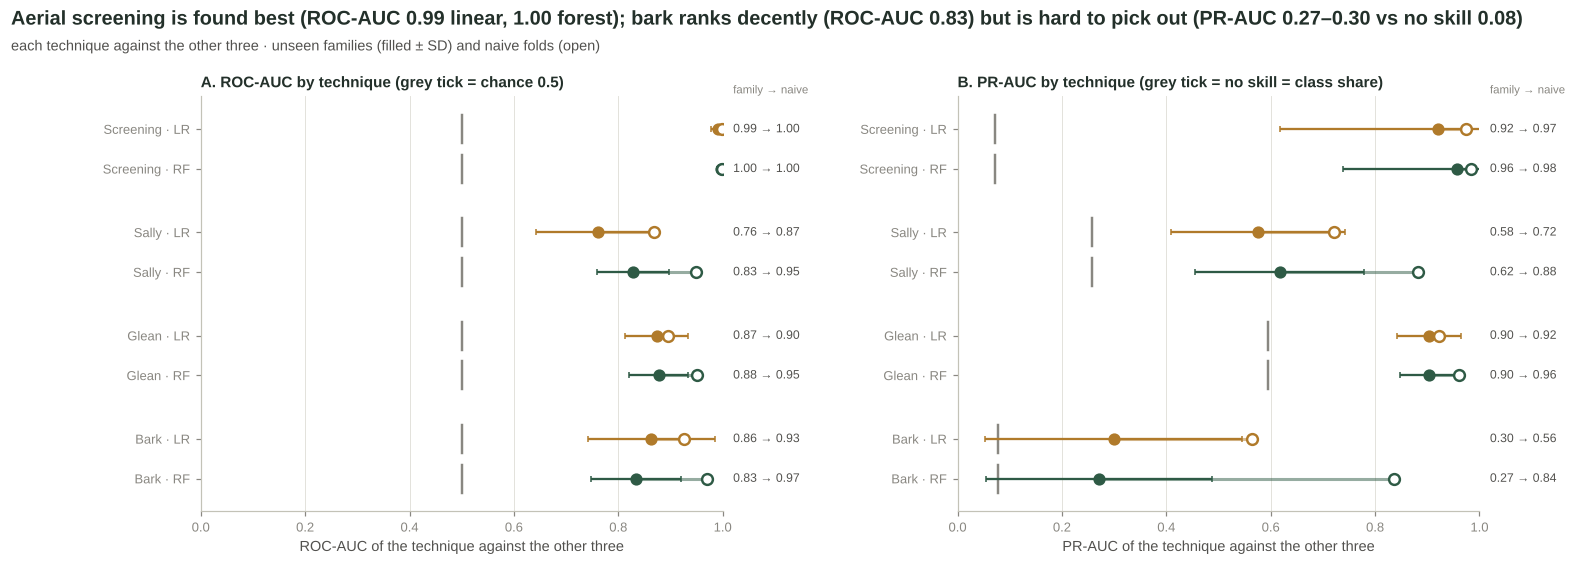

In [31]:
prev4 = np.bincount(y4, minlength=len(STRAT_LAB)) / len(y4)
PERCLS = pd.DataFrame({(m, s, met): [mean_.loc[(m, s), f"{met}_{l}"] for l in STRAT_LAB]
                       for m in MODELS for s in SCHEMES for met in ("roc", "pr")}, index=STRAT_LAB)
print(PERCLS.xs(SF, axis=1, level=1).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.9), gridspec_kw={"wspace": 0.45})
for ax, (met, mlab) in zip(axes, [("roc", "ROC-AUC"), ("pr", "PR-AUC")]):
    rows = []
    for c, lab in enumerate(STRAT_LAB):
        for mname in MODELS:
            rows.append(dict(label=f"{lab} · {SHORT[mname]}", color=M_COL[mname], fam=mean_.loc[(mname, SF), f"{met}_{lab}"],
                             sd=boot_half[mname][f"{met}_{lab}"], naive=mean_.loc[(mname, SN), f"{met}_{lab}"],
                             chance=0.5 if met == "roc" else prev4[c]))
        rows.append(None)
    dumbbell(ax, rows[:-1])
    ax.set_xlim(0, 1.0)
    ax.set_xlabel(f"{mlab} of the technique against the other three")
    ax.set_title(f"{'A' if met == 'roc' else 'B'}. {mlab} by technique (grey tick = {'chance 0.5' if met == 'roc' else 'no skill = class share'})",
                 fontsize=10)
    ax.text(1.02, -0.9, "family → naive", fontsize=7.5, color=MUTED, transform=ax.get_yaxis_transform())
air_r = mean_.loc[("Logistic regression", SF), "roc_Screening"]
bark_r = mean_.loc[("Random forest", SF), "roc_Bark"]
bark_pr = [mean_.loc[(m, SF), "pr_Bark"] for m in MODELS]
suptitle(fig, f"Aerial screening is found best (ROC-AUC {air_r:.2f} linear, {mean_.loc[('Random forest', SF), 'roc_Screening']:.2f} forest); bark ranks "
         f"decently (ROC-AUC {bark_r:.2f}) but is hard to pick out (PR-AUC {min(bark_pr):.2f}–{max(bark_pr):.2f} vs no skill {prev4[3]:.2f})", "each technique against the other three · unseen families (filled ± SD) and naive folds (open)", y=1.04)
save(fig, "08a1_per_strategy")

**Reading the figure** · Filled dot = unseen families (± 95% interval), open dot = naive folds, grey tick = no skill.

**Takeaway.** Aerial screening is found almost perfectly (ROC-AUC 0.99 LR, 1.00 RF; PR-AUC 0.92–0.96 against a no-skill 0.07). Gleaning ranks well (0.87–0.88; PR-AUC 0.90 against 0.59). Sallying is the hardest common technique (0.76 LR, 0.83 RF; PR-AUC 0.58–0.62 against 0.26): many salliers also glean. Bark ranks decently (0.86 LR, 0.83 RF) but is hard to pick out (PR-AUC 0.30 / 0.27 against 0.08).

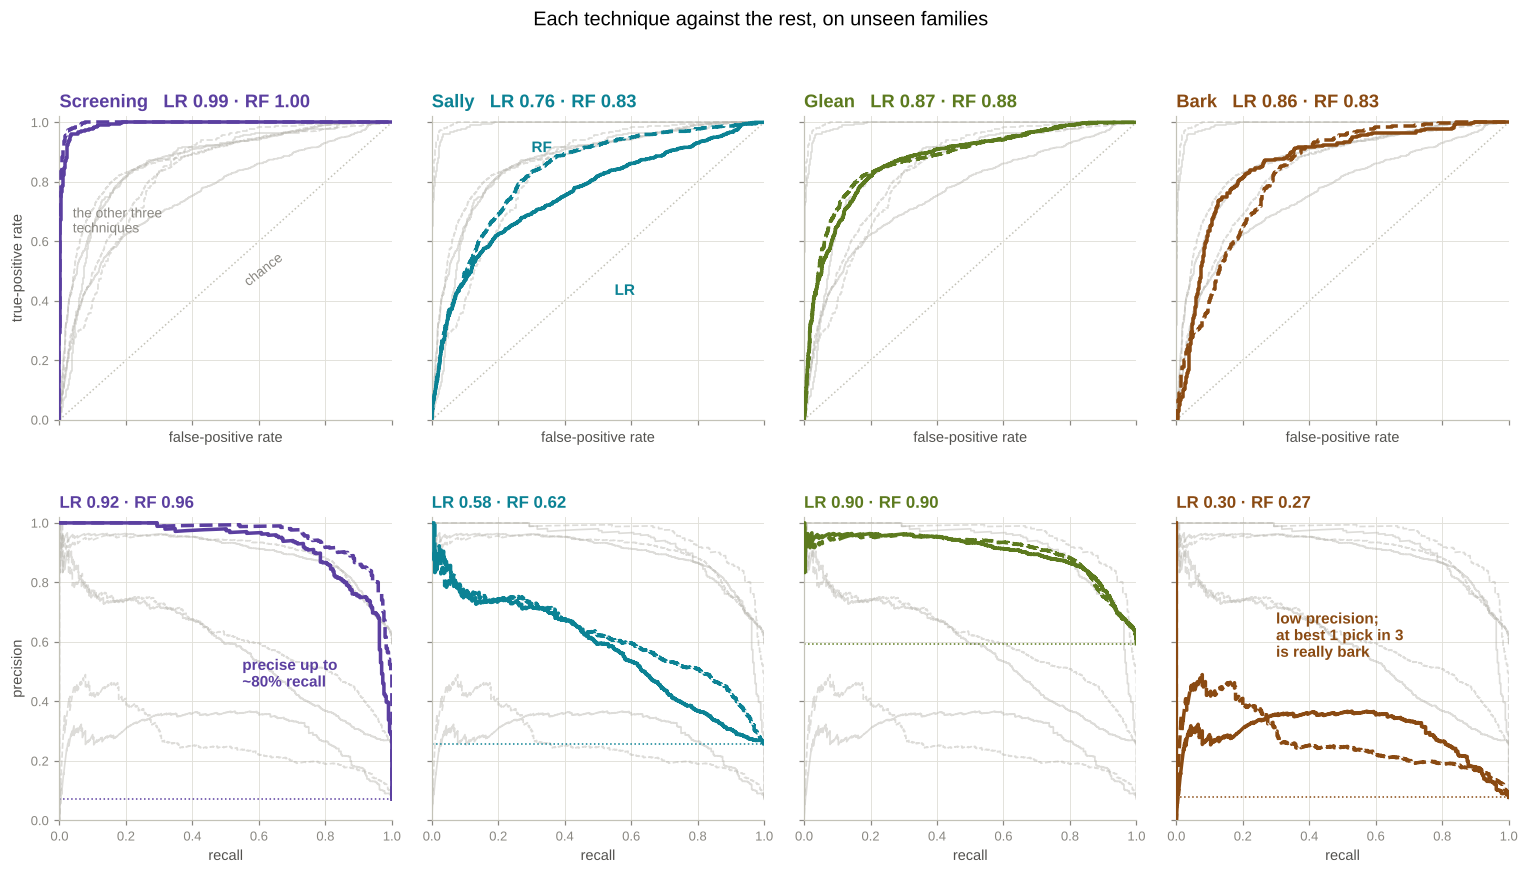

In [32]:
# Small multiples: one panel per technique, the other three kept in grey as a reference (unseen families, out-of-fold)
TECH_COL = {"Screening": "#5b3fa0", "Sally": "#0b8294", "Glean": "#5c7a1e", "Bark": "#8a4a12"}
fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharex=True, sharey=True, gridspec_kw={"hspace": 0.32, "wspace": 0.12})
for row, kind in enumerate(["ROC", "Precision–recall"]):
    for col, focus in enumerate(range(4)):
        ax = axes[row, col]
        col_focus = TECH_COL[STRAT_LAB[focus]]
        for pass_ in ("others", "focus"):
            for c in range(4):
                if (c == focus) != (pass_ == "focus"):
                    continue
                for mname, ls in [("Logistic regression", "-"), ("Random forest", "--")]:
                    P = OOF[(SF, mname)]
                    if kind == "ROC":
                        x_, y_, _ = roc_curve(y4 == c, P[:, c])
                    else:
                        y_, x_, _ = precision_recall_curve(y4 == c, P[:, c])
                    ax.plot(x_, y_, ls=ls, color=col_focus if c == focus else OTHER,
                            lw=2.3 if c == focus else 1.1, alpha=1 if c == focus else 0.45,
                            zorder=3 if c == focus else 1)
        if kind == "ROC":
            ax.plot([0, 1], [0, 1], color=AXIS, lw=1, ls=":", zorder=0)
            if col == 0:
                ax.text(0.55, 0.45, "chance", fontsize=9, color=MUTED, rotation=38)
                ax.text(0.04, 0.63, "the other three\ntechniques", fontsize=9, color=MUTED)
            met = "roc"
        else:
            ax.axhline(prev4[focus], color=col_focus, lw=1, ls=":", zorder=2)
            met = "pr"
        sc = {SHORT[m]: mean_.loc[(m, SF), f"{met}_{STRAT_LAB[focus]}"] for m in MODELS}
        title = f"LR {sc['LR']:.2f} · RF {sc['RF']:.2f}"
        if row == 0:
            ax.set_title(f"{STRAT_LAB[focus]}   {title}", fontsize=12, color=col_focus, fontweight="bold", loc="left")
        else:
            ax.set_title(title, fontsize=11, color=col_focus, loc="left")
        ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
        if col == 0:
            ax.set_ylabel("true-positive rate" if kind == "ROC" else "precision")
        ax.set_xlabel("false-positive rate" if kind == "ROC" else "recall")
axes[0, 1].text(0.30, 0.90, "RF", fontsize=10, color=TECH_COL["Sally"], fontweight="bold")
axes[0, 1].text(0.55, 0.42, "LR", fontsize=10, color=TECH_COL["Sally"], fontweight="bold")
axes[1, 0].text(0.55, 0.45, "precise up to\n~80% recall", fontsize=10, color=TECH_COL["Screening"], fontweight="bold")
axes[1, 3].text(0.3, 0.55, "low precision;\nat best 1 pick in 3\nis really bark", fontsize=10, color=TECH_COL["Bark"], fontweight="bold")
fig.suptitle("Each technique against the rest, on unseen families", fontsize=13, y=1.0)
fig.subplots_adjust(top=0.88, bottom=0.08)
save(fig, "08a3_small_multiples")

**Reading the figure** · Same out-of-fold predictions on unseen families (repeat 1), one technique per column; the other three in grey. Top: ROC (dotted diagonal = chance). Bottom: precision–recall (dotted line = class share). Solid = LR, dashed = RF.

**Takeaway.** Screening hugs the top-left corner. Gleaning sits well above chance. Sallying is weaker, and the forest beats the linear model on it. Bark has a decent ROC curve but low precision: it ranks birds reasonably but cannot pick out the few bark foragers cleanly.

#### Which techniques get confused?
**What this cell does.** It turns the out-of-fold probabilities (unseen families, repeat 1) into a predicted technique, the most probable one, and draws a confusion matrix per model, each row as a share of the true technique.

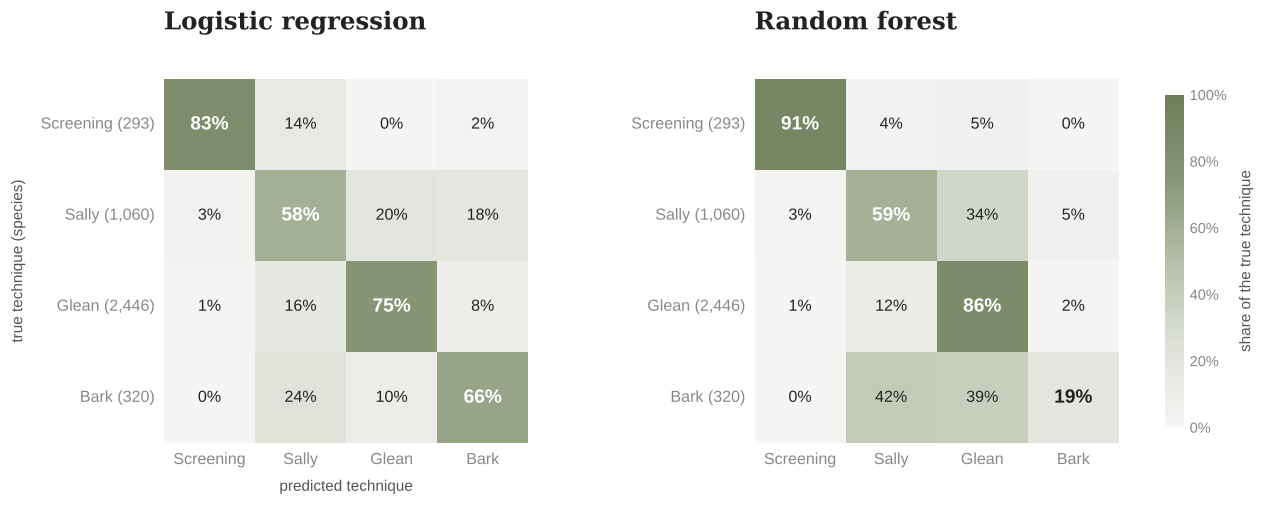

In [33]:
from matplotlib.colors import LinearSegmentedColormap

n_cls = len(STRAT_LAB)

CM = {m: confusion_matrix(y4, OOF[(SF, m)].argmax(axis=1)) for m in MODELS}
PCT = {m: c / c.sum(axis=1, keepdims=True) for m, c in CM.items()}
acc = {m: np.trace(c) / len(y4) for m, c in CM.items()}

sage_cmap = LinearSegmentedColormap.from_list(
    "sage_cm", ["#f5f5f4", "#dde1d7", "#b5bfa9", "#879575", "#6d7d59"]
)

fig, axes = plt.subplots(1, len(MODELS), figsize=(12.2, 4.8))
fig.subplots_adjust(left=0.14, right=0.89, top=0.82, bottom=0.13, wspace=0.42)
cbar_ax = fig.add_axes([0.905, 0.16, 0.014, 0.63])

for idx, (ax, mname) in enumerate(zip(axes, MODELS)):
    c, pct = CM[mname], PCT[mname]

    hm = sns.heatmap(
        pct,
        annot=False,
        cmap=sage_cmap,
        vmin=0,
        vmax=1,
        ax=ax,
        cbar=(idx == len(MODELS) - 1),
        cbar_ax=cbar_ax if idx == len(MODELS) - 1 else None,
        linewidths=0,
        square=True,
    )

    for i in range(n_cls):
        for j in range(n_cls):
            val = pct[i, j]
            ax.text(
                j + 0.5,
                i + 0.5,
                f"{val:.0%}",
                ha="center",
                va="center",
                fontsize=12.5 if i == j else 10.5,
                fontweight="bold" if i == j else "normal",
                color="white" if val > 0.50 else "#222222",
            )

    ax.set_xticklabels(STRAT_LAB, rotation=0)
    ax.set_yticklabels([f"{s} ({c[i].sum():,})" for i, s in enumerate(STRAT_LAB)], rotation=0)
    ax.tick_params(axis="both", length=0, colors="#888888", labelsize=10.5, pad=6)

    ax.set_xlabel("predicted technique" if idx == 0 else "", color="#555555", fontsize=10, labelpad=8)
    ax.set_ylabel("true technique (species)" if idx == 0 else "", color="#555555", fontsize=10, labelpad=10)

    ax.text(
        0.0, 1.12, mname,
        transform=ax.transAxes,
        fontfamily="serif",
        fontsize=16,
        fontweight="bold",
        color="#222222",
        va="bottom",
        ha="left",
    )

cbar = hm.collections[0].colorbar
cbar.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar.ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
cbar.ax.tick_params(length=0, colors="#888888", labelsize=9.5, pad=4)
cbar.set_label("share of the true technique", color="#555555", fontsize=10, labelpad=8)
cbar.outline.set_visible(False)

save(fig, "08e_confusion_matrices")

**Reading the figure** · Each row sums to 100%; the diagonal is the share found.

**Takeaway.** Both models find most aerial screeners (83% LR, 91% RF) and gleaners (75%, 86%), and about 58–59% of salliers; the most common error is sally → glean (20% LR, 34% RF). Bark is where they differ: LR finds 66% of bark foragers, the forest only 19%, filing the rest under sally (42%) and glean (39%). Overall the most probable technique is right for 70% (LR) and 74% (RF) of species.

## III.2 · A harder split: leave one order out
**Question it serves.** Family folds still let a model train on close cousins in the same order. Does the rule transfer to **entirely new orders**?
**What this cell does.** It holds out each order once (`LeaveOneGroupOut`), trains on all the others and pools the predictions. Naive and family folds are scored the same way (pooled, repeat 1), so the three schemes are comparable.
**Why pooled.** Passeriformes holds 79% of species and many orders contain a single technique, so a per-order score is often undefined.

In [34]:
# Update this line inside eval_oof() in the previous cell so it handles missing classes in y[tr]:
# P[np.ix_(te, mdl.classes_)] = mdl.predict_proba(X[te])

assert df["Order1"].notna().all(), "Missing values in Order1"
ord_g = df["Order1"].to_numpy()
logo = lambda _: LeaveOneGroupOut()

OOF_ORD = {mname: eval_oof(make, logo, XF, y4, ord_g, seed=SEED)[0] for mname, make in MODELS.items()}

SCH3 = [
    ("naive folds", lambda m: OOF[(SN, m)]),
    ("unseen families", lambda m: OOF[(SF, m)]),
    ("unseen orders", lambda m: OOF_ORD[m]),
]
pool = pd.DataFrame([dict(model=m, scheme=s, **metrics4(y4, get_oof(m))) for m in MODELS for s, get_oof in SCH3])
print(pool[["model", "scheme"] + HEAD].round(3).to_string(index=False))

print("\nPer technique, unseen orders:")
tech_cols = [f"roc_{l}" for l in STRAT_LAB] + [f"pr_{l}" for l in STRAT_LAB]
print(pool.loc[pool["scheme"] == "unseen orders"].set_index("model")[tech_cols].round(2).to_string())

              model          scheme  macro_roc  macro_pr
Logistic regression     naive folds      0.922     0.795
Logistic regression unseen families      0.871     0.673
Logistic regression   unseen orders      0.822     0.603
      Random forest     naive folds      0.966     0.914
      Random forest unseen families      0.883     0.688
      Random forest   unseen orders      0.823     0.624

Per technique, unseen orders:
                     roc_Screening  roc_Sally  roc_Glean  roc_Bark  pr_Screening  pr_Sally  pr_Glean  pr_Bark
model                                                                                                        
Logistic regression           0.99       0.71       0.82      0.76          0.94      0.45      0.85     0.18
Random forest                 0.99       0.77       0.86      0.67          0.95      0.50      0.89     0.15


In [35]:
is_pass = ord_g == "Passeriformes"
print(f"Passeriformes share: {is_pass.mean():.1%} ({is_pass.sum():,} / {len(y4):,} species)")

split_ord = pd.DataFrame(
    [
        dict(model=m, subset=label, **metrics4(y4[mask], OOF_ORD[m][mask]))
        for m in MODELS
        for label, mask in [
            ("Passeriformes (trained on non-passerines)", is_pass),
            ("Non-passerines (trained on passerines+)", ~is_pass),
        ]
    ]
)
print(split_ord[["model", "subset"] + HEAD].round(3).to_string(index=False))

Passeriformes share: 78.8% (3,247 / 4,119 species)
              model                                    subset  macro_roc  macro_pr
Logistic regression Passeriformes (trained on non-passerines)      0.778     0.584
Logistic regression   Non-passerines (trained on passerines+)      0.743     0.569
      Random forest Passeriformes (trained on non-passerines)      0.848     0.640
      Random forest   Non-passerines (trained on passerines+)      0.728     0.559


**Reading the output** · **Takeaway.** On unseen orders macro ROC-AUC is 0.82 for both models (PR-AUC 0.60 LR, 0.62 RF). Aerial screening still reaches 0.99; bark falls most (0.76 LR, 0.67 RF). Passerines predicted from non-passerines keep ROC-AUC 0.78 (LR) and 0.85 (RF); non-passerines predicted mostly from passerines 0.74 and 0.73.

#### Three schemes side by side

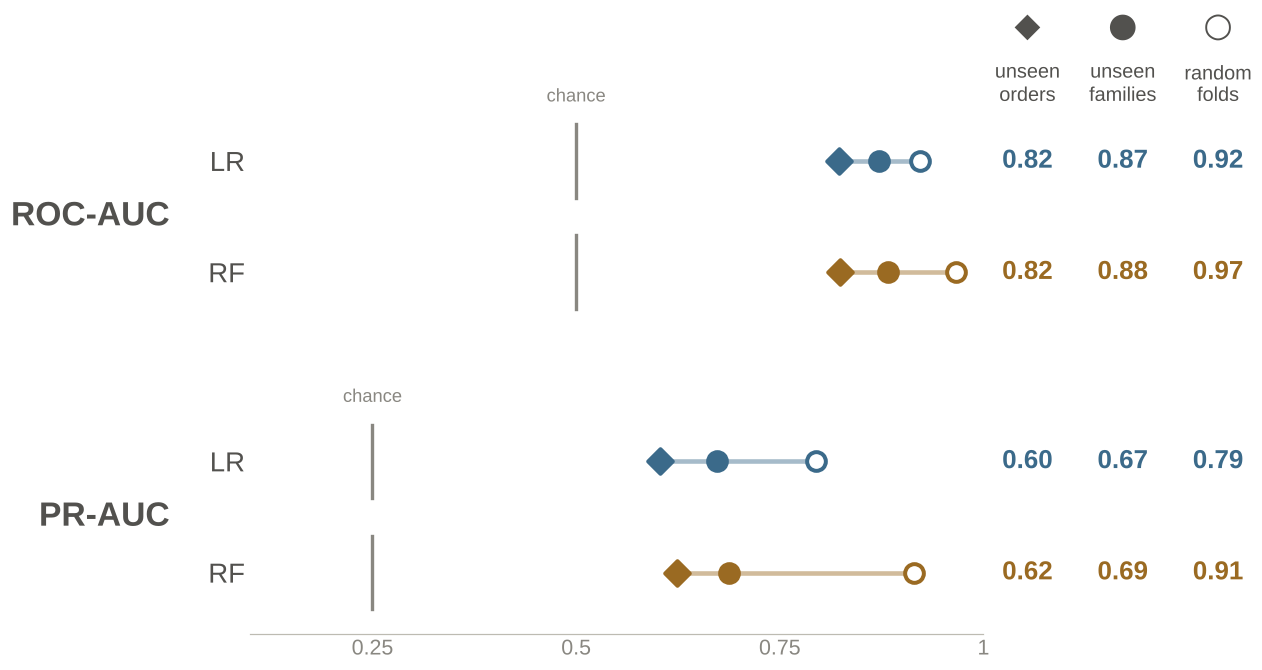

In [36]:
# Macro scores under the three schemes, pooled out-of-fold (unseen orders, unseen families, random folds)
MODEL_STYLE = {
    "Logistic regression": ("LR", "#3b6a8a"),
    "Random forest": ("RF", "#9a6a22"),
}
METRICS = [
    ("ROC-AUC", "macro_roc", 0.50),
    ("PR-AUC", "macro_pr", 0.25),
]
SCHEMES_ORD = ["naive folds", "unseen families", "unseen orders"]
MARKERS = [("o", "white"), ("o", None), ("D", None)]
XC = [1.06, 1.19, 1.32]

pool_idx = pool.set_index(["model", "scheme"])

fig, ax = plt.subplots(figsize=(8.6, 6.3))
yy = 0.0
yticks, ylabels = [], []

for met_label, met_col, chance in METRICS:
    for idx, (mname, (short_lab, col)) in enumerate(MODEL_STYLE.items()):
        vals = [float(pool_idx.loc[(mname, s), met_col]) for s in SCHEMES_ORD]

        ax.plot([chance, chance], [yy - 0.33, yy + 0.33], color=MUTED, lw=2.2, zorder=1)
        if idx == 0:
            ax.text(chance, yy - 0.5, "chance", ha="center", va="bottom", fontsize=12, color=MUTED)

        ax.plot([min(vals), max(vals)], [yy, yy], color=col, lw=3, alpha=0.45, zorder=2, solid_capstyle="round")
        for x_val, (mk, fc) in zip(vals, MARKERS):
            ax.scatter(
                [x_val], [yy],
                s=150 if mk == "o" else 130,
                marker=mk,
                facecolor=fc or col,
                edgecolor=col,
                lw=2.6,
                zorder=4,
            )

        for x_col, x_val in zip(XC, vals[::-1]):
            ax.text(
                x_col, yy, f"{x_val:.2f}",
                transform=ax.get_yaxis_transform(),
                va="center", ha="center", fontsize=17, fontweight="bold", color=col,
            )

        yticks.append(yy)
        ylabels.append(short_lab)
        yy += 1.0

    ax.text(
        -0.11, yy - 1.5, met_label,
        transform=ax.get_yaxis_transform(),
        ha="right", va="center", fontsize=22, fontweight="bold", color=INK2,
    )
    yy += 0.7

ax.set_yticks(yticks, ylabels, fontsize=18, color=INK2)
ax.invert_yaxis()
ax.set_xlim(0.1, 1.0)
ax.set_xticks([0.25, 0.5, 0.75, 1.0], ["0.25", "0.5", "0.75", "1"], fontsize=14, color=MUTED)
ax.tick_params(length=0)
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)
ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_color("#bdbbb2")

for x_col, glyph, l1, l2 in zip(XC, ["\u25C6", "\u25CF", "\u25CB"], ["unseen", "unseen", "random"], ["orders", "families", "folds"]):
    ax.text(x_col, -1.2, glyph, transform=ax.get_yaxis_transform(), ha="center", va="center", fontsize=22, color=INK2, family="DejaVu Sans")
    ax.text(x_col, -0.7, f"{l1}\n{l2}", transform=ax.get_yaxis_transform(), ha="center", va="center", fontsize=13, color=INK2, linespacing=1.15)

save(fig, "macro_three_schemes")

**Reading the figure** · Macro ROC-AUC and PR-AUC under random folds (open circle), unseen families (filled circle) and unseen orders (diamond); the grey tick is chance.

**Takeaway.** The farther the test lineage, the lower the score. Macro ROC-AUC falls from 0.92 / 0.97 (LR / RF, random folds) to 0.87 / 0.88 on unseen families and 0.82 / 0.82 on unseen orders; macro PR-AUC from 0.80 / 0.91 to 0.67 / 0.69 and 0.60 / 0.62. The forest loses the most, but even on the strictest test both stay well above chance.

## III.3 · SHAP: the same model, one species at a time, technique by technique (lecture 6b)
**What this cell does.** It computes SHAP values **out of fold** for the random forest (family folds, approximate TreeSHAP for speed): each species is explained by a forest that never saw its family, with one set of values per technique.
**How SHAP works.** For one species and one technique, SHAP splits the predicted probability into a base rate plus one contribution per trait; a positive value pushes the bird toward that technique.
**Why.** It shows whether high and low values of a trait push in opposite directions, and how the story differs between techniques. Descriptive: correlated traits share their credit.

In [37]:
n_cls = len(STRAT_LAB)
SH = np.zeros(XF.shape + (n_cls,))

for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(XF, y4, groups):
    rf_s = MODELS["Random forest"](0).fit(XF[tr], y4[tr])
    sv = shap.TreeExplainer(rf_s).shap_values(XF[te], approximate=True, check_additivity=False)
    SH[te] = np.stack(sv, axis=-1) if isinstance(sv, list) else sv  # (species, traits, techniques)

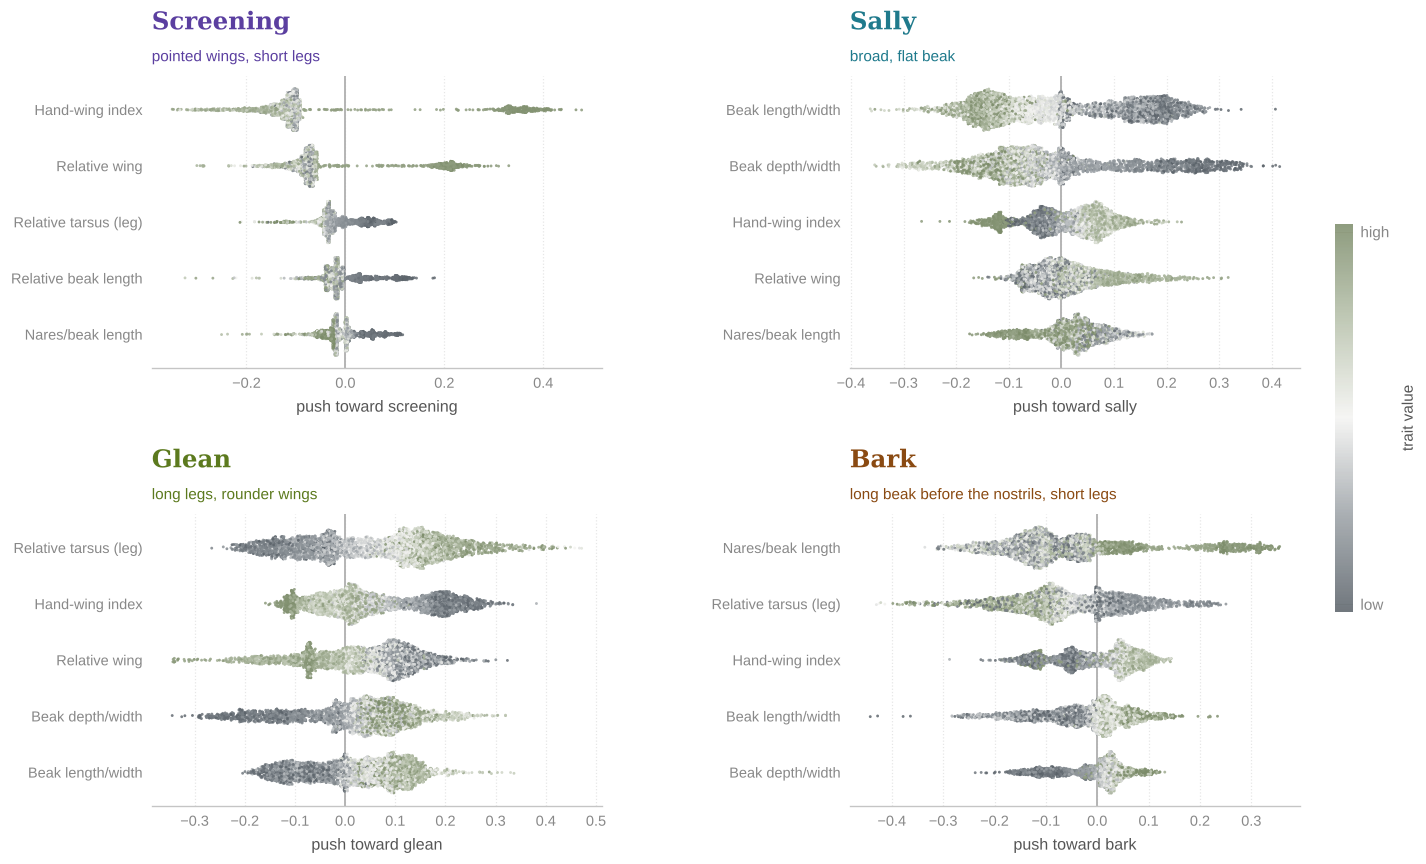

In [38]:
from matplotlib.colors import LinearSegmentedColormap

CLS_COL = ["#5b3fa0", "#1f7a8c", "#5c7a1e", "#8a4a12"]
SUBTITLES = {
    "Screening": "pointed wings, short legs",
    "Sally": "broad, flat beak",
    "Glean": "long legs, rounder wings",
    "Bark": "long beak before the nostrils, short legs",
}

bee_cmap = LinearSegmentedColormap.from_list(
    "bee_slate_sage", ["#586067", "#9ba1a6", "#f4f4f2", "#b7c1ab", "#7b8b69"]
)

TRAIT_RANKS = stats.rankdata(XF, axis=0) / len(XF)
TOP_K = min(5, XF.shape[1])

fig, axes = plt.subplots(2, 2, figsize=(14.5, 8.4))
fig.subplots_adjust(left=0.17, right=0.89, top=0.88, bottom=0.09, hspace=0.50, wspace=0.55)
cbar_ax = fig.add_axes([0.912, 0.30, 0.011, 0.42])

rng_b = np.random.default_rng(SEED)

for c, ax in enumerate(axes.ravel()):
    S_c = SH[:, :, c]
    mean_abs = np.abs(S_c).mean(axis=0)
    order_c = np.argsort(mean_abs)[-TOP_K:]

    for row, j in enumerate(order_c):
        v = S_c[:, j]
        cnt, edges = np.histogram(v, bins=75)
        bin_idx = np.clip(np.digitize(v, edges) - 1, 0, len(cnt) - 1)
        dens = cnt[bin_idx] / max(cnt.max(), 1)
        yj = row + rng_b.uniform(-1, 1, len(v)) * 0.37 * (dens ** 0.6)
        sc = ax.scatter(
            v,
            yj,
            c=TRAIT_RANKS[:, j],
            cmap=bee_cmap,
            vmin=0,
            vmax=1,
            s=3.5,
            lw=0,
            alpha=0.85,
            rasterized=True,
            zorder=3,
        )

    ax.axvline(0, color="#b0b0b0", lw=1.2, zorder=2)
    ax.xaxis.grid(True, linestyle=":", linewidth=0.8, color="#e6e6e6", zorder=0)
    ax.yaxis.grid(False)

    ax.set_ylim(-0.6, TOP_K - 0.4)
    ax.set_yticks(range(TOP_K))
    ax.set_yticklabels([NICE[INTERNAL_MORPH_COLS[j]] for j in order_c], fontsize=10.5, color="#777777")
    ax.tick_params(axis="both", length=0, colors="#888888", labelsize=9.5, pad=6)

    for spine in ("top", "right", "left"):
        ax.spines[spine].set_visible(False)
    ax.spines["bottom"].set_visible(True)
    ax.spines["bottom"].set_color("#c5c5c5")
    ax.spines["bottom"].set_linewidth(0.9)

    lab = STRAT_LAB[c]
    col = CLS_COL[c]
    ax.set_xlabel(f"push toward {lab.lower()}", fontsize=10.5, color="#555555", labelpad=6)

    ax.text(
        0.0, 1.14, lab,
        transform=ax.transAxes,
        fontfamily="serif",
        fontsize=16,
        fontweight="bold",
        color=col,
        va="bottom",
        ha="left",
    )
    ax.text(
        0.0, 1.04, SUBTITLES.get(lab, ""),
        transform=ax.transAxes,
        fontsize=10,
        color=col,
        va="bottom",
        ha="left",
    )

cb = fig.colorbar(sc, cax=cbar_ax)
cb.set_ticks([0.02, 0.98])
cb.set_ticklabels(["low", "high"])
cb.ax.tick_params(length=0, colors="#888888", labelsize=10, pad=5)
cb.set_label("trait value", color="#555555", fontsize=10, labelpad=8)
cb.outline.set_visible(False)

save(fig, "08c_shap_beeswarm")

**Reading the figure** · One dot per species; x = push on the predicted probability, colour = the species' trait value (green high, slate low). The top 5 traits per technique, ordered by mean |SHAP|.

**Takeaway.** Each technique has its own signature. **Screening:** high hand-wing index and long wings, short legs. **Sally:** a broad, flat beak (low beak length/width and depth/width), the flycatcher bill. **Glean:** long legs and short, rounded wings. **Bark:** a long bill in front of the nostrils (high nares/beak) and short legs. The strongest trait differs for every technique.

## III.4 · Families are not independent either
**Question it serves.** Species in the same family share ancestry. Could the body–technique link be only ancestry?
**What these cells do.** They draw the BirdLife family tree twice: with the most common morphotype of each family, then with the technique mix of its species. Branches show how families are related.
**Why.** It shows why species are not independent (whole clades share a morphotype) and whether the same technique appears in distant lineages. A visual check, not a phylogenetic model.

In [39]:
def parse_nexus_tree(path):
    with open(path) as f:
        txt = f.read()
    tr = re.search(r"TRANSLATE(.*?);", txt, re.S).group(1)
    idmap = dict(re.findall(r"(\d+)\s+(\w+),?", tr))
    nw = re.search(r"TREE \* UNTITLED = \[&R\] (.*?);", txt, re.S).group(1)
    pos = [0]

    def parse():
        if nw[pos[0]] == "(":
            pos[0] += 1
            ch = [parse()]
            while nw[pos[0]] == ",":
                pos[0] += 1
                ch.append(parse())
            pos[0] += 1
            node = {"ch": ch}
        else:
            m = re.match(r"(\d+)", nw[pos[0]:])
            pos[0] += len(m.group(1))
            node = {"name": idmap[m.group(1)], "ch": []}

        if pos[0] < len(nw) and nw[pos[0]] == ":":
            m = re.match(r":([0-9.eE+-]+)", nw[pos[0]:])
            pos[0] += len(m.group(0))
            node["len"] = float(m.group(1))
        else:
            node["len"] = 0.0
        return node

    return parse()


have_fams = set(df["Family1"].unique())


def prune_tree(n):
    if not n["ch"]:
        return dict(n) if n["name"] in have_fams else None
    kids = [k for k in (prune_tree(c) for c in n["ch"]) if k is not None]
    if not kids:
        return None
    if len(kids) == 1:
        k = kids[0]
        k["len"] += n["len"]
        return k
    return {"ch": kids, "len": n["len"], "name": None}


root = prune_tree(parse_nexus_tree("./datasets/Birdlife_Family_Phylogeny.nex"))

leaves = []


def assign_depths(n, d):
    n["d"] = d + n["len"]
    if not n["ch"]:
        n["i"] = len(leaves)
        leaves.append(n)
        return
    for c in n["ch"]:
        assign_depths(c, n["d"])


assign_depths(root, -root["len"])
NL = len(leaves)
W_STEP = 2 * np.pi / NL
depth_max = max(l["d"] for l in leaves)


def assign_angles(n):
    if not n["ch"]:
        n["a"] = W_STEP * (n["i"] + 0.5)
        return
    for c in n["ch"]:
        assign_angles(c)
    n["a"] = 0.5 * (n["ch"][0]["a"] + n["ch"][-1]["a"])


assign_angles(root)

fams = df["Family1"].value_counts()
LEAF = {l["name"]: l for l in leaves}
print(
    f"families in tree: {NL} | in data: {len(fams)} | matched: {len(set(LEAF) & set(fams.index))} "
    f"| species matched: {int(fams[fams.index.isin(LEAF)].sum())} of {int(fams.sum())}"
)

grp = df.groupby("Family1")
msh = grp[["I_Screen", "I_Sally", "I_Glean", "I_Bark"]].mean()
comp = pd.crosstab(df["Family1"], df["Cluster"], normalize="index").reindex(columns=[0, 1, 2, 3], fill_value=0.0)
valid_comp_fams = set(comp.index)

MC = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
TXTC = ["#1f62b5", "#b8451a", "#0f7550", "#8a5d00"]


def rr(d):
    return 0.12 + 0.60 * d / depth_max


def leaves_of(n):
    return [n] if not n["ch"] else [x for c in n["ch"] for x in leaves_of(c)]


def find_monophyletic(n, want):
    ls = {l["name"] for l in leaves_of(n)}
    if want <= ls and len(ls & valid_comp_fams) == len(want):
        return n
    for c in n["ch"]:
        res = find_monophyletic(c, want)
        if res is not None:
            return res
    return None


def draw_polar_tree(clade_colors):
    """Initialize polar tree canvas, highlight target clades, and draw branches."""
    fig = plt.figure(figsize=(12.5, 12.5))
    ax = fig.add_axes([0.02, 0.02, 0.96, 0.96], projection="polar")
    ax.set_axis_off()
    ax.set_ylim(0, 1.0)

    hl = {}

    def mark(n, col):
        hl[id(n)] = col
        for c in n["ch"]:
            mark(c, col)

    for fam_list, col in clade_colors:
        target = set(fam_list) & set(LEAF)
        if not target:
            continue

        def walk(n):
            desc = {l["name"] for l in leaves_of(n)}
            if desc <= target:
                mark(n, col)
            elif desc & target:
                for c in n["ch"]:
                    walk(c)

        walk(root)

    def style(n):
        return (hl[id(n)], 2.2, 1.0) if id(n) in hl else ("#7b827d", 0.9, 0.22)

    def draw(n):
        r = rr(n["d"])
        if n["ch"]:
            a1, a2 = n["ch"][0]["a"], n["ch"][-1]["a"]
            col, lw, al = style(n)
            th = np.linspace(a1, a2, 30)
            ax.plot(th, np.full_like(th, r), color=col, lw=lw, alpha=al, solid_capstyle="round")
            for c in n["ch"]:
                col, lw, al = style(c)
                ax.plot([c["a"], c["a"]], [r, rr(c["d"])], color=col, lw=lw, alpha=al, solid_capstyle="round")
                draw(c)

    draw(root)
    return fig, ax, hl


def add_clade_arc(ax, fams, text, color, r=0.87, tang=None, tr=1.0, ha=None, fs=19):
    """Draw outer clade arc, leader line, and label (auto-placing angle/alignment if omitted)."""
    valid = [f for f in fams if f in LEAF]
    if not valid:
        return
    node = find_monophyletic(root, set(valid))
    angles = [l["a"] for l in leaves_of(node)] if node is not None else [LEAF[f]["a"] for f in valid]
    a1, a2 = min(angles) - W_STEP * 0.55, max(angles) + W_STEP * 0.55
    am = 0.5 * (a1 + a2)

    if tang is None:
        tang = np.degrees(am) % 360
    if ha is None:
        if 80 < tang < 100 or 260 < tang < 280:
            ha = "center"
        else:
            ha = "left" if (tang < 90 or tang > 270) else "right"

    th = np.linspace(a1, a2, 80)
    ax.plot(th, np.full_like(th, r), color=color, lw=3.2, solid_capstyle="round")
    ax.plot([am, np.radians(tang)], [r, tr - 0.05], color=color, lw=1.1)
    ax.text(np.radians(tang), tr, text, ha=ha, va="center", fontsize=fs, color=color, fontweight="bold", linespacing=1.25)

families in tree: 137 | in data: 137 | matched: 137 | species matched: 4119 of 4119


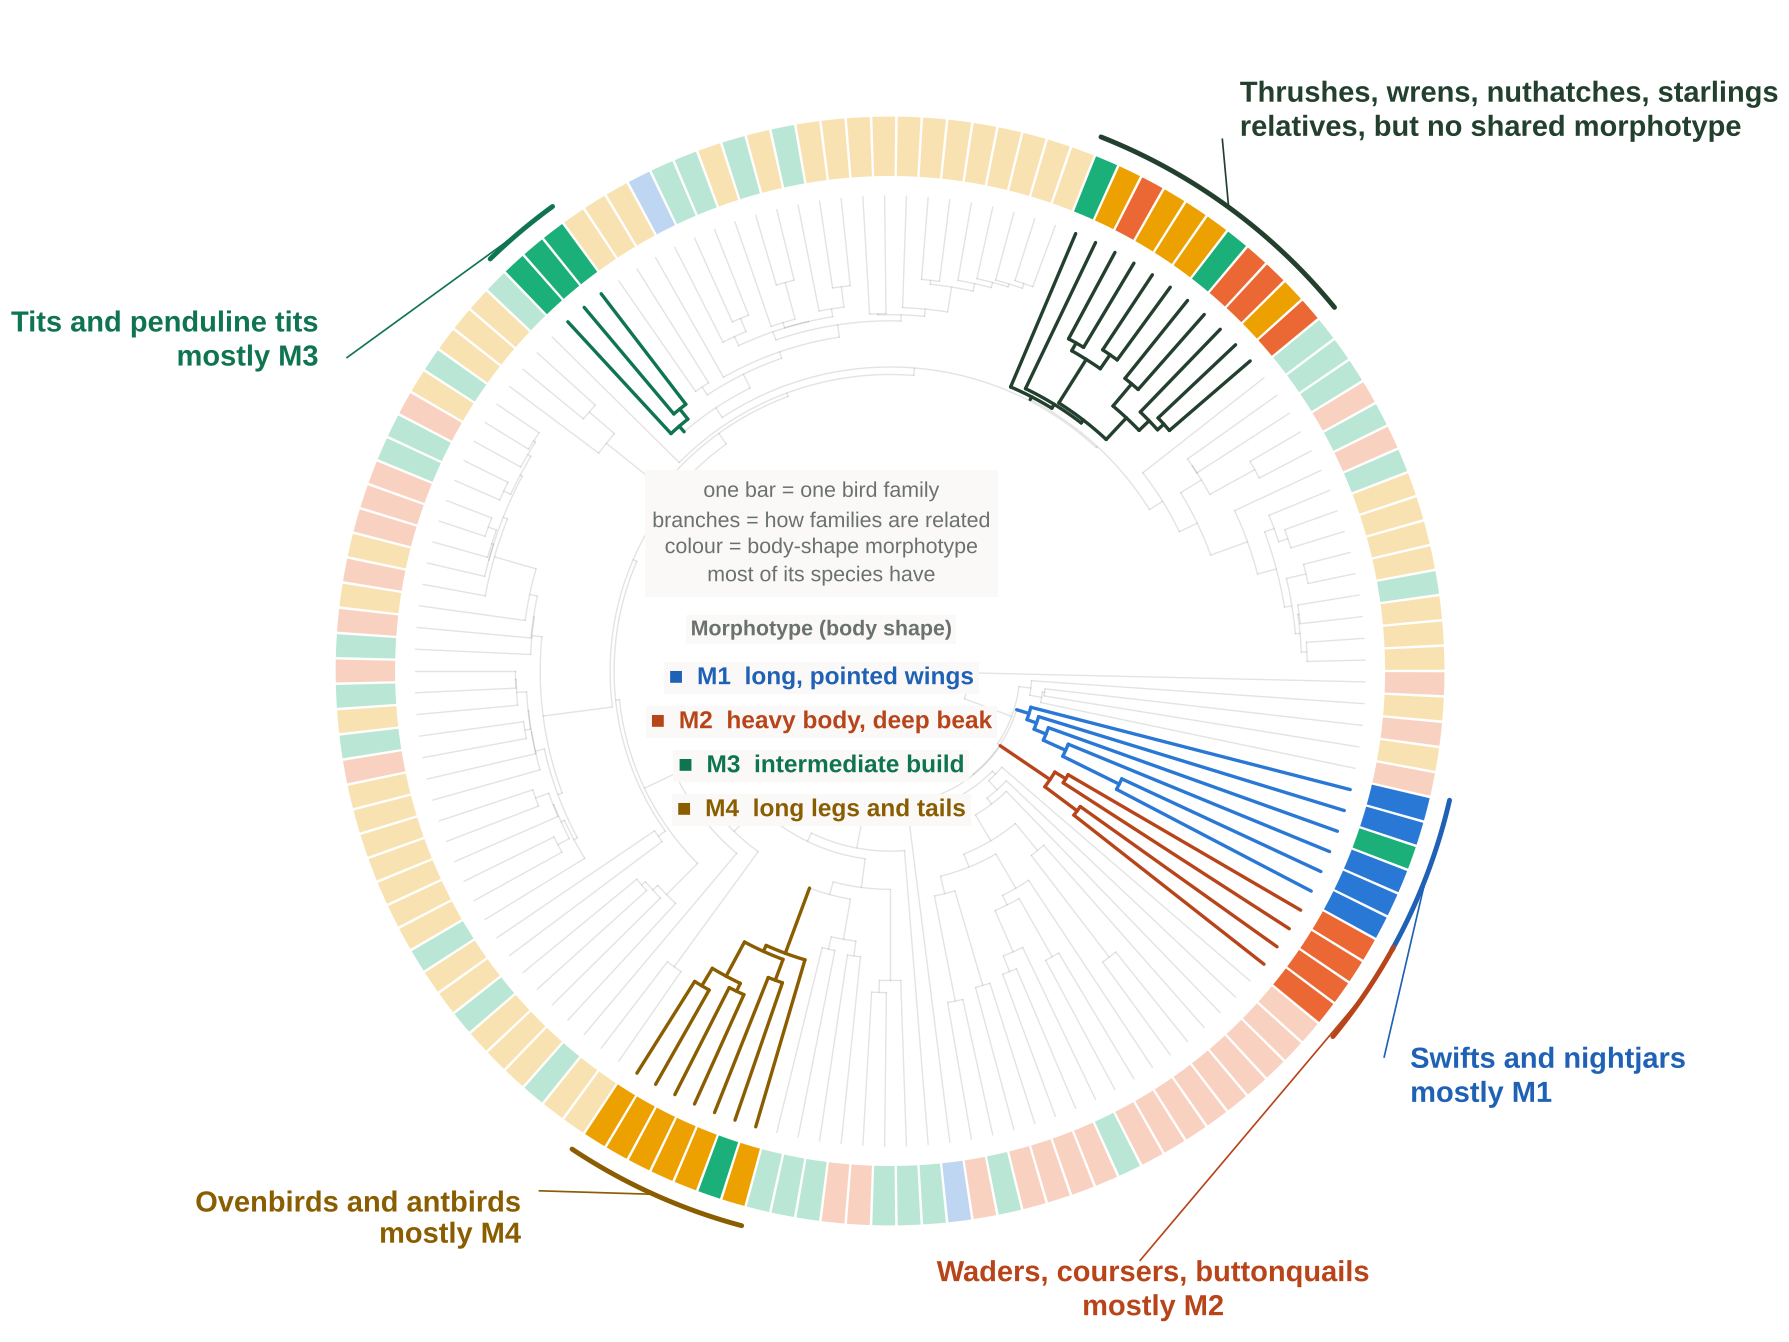

In [40]:
OVENBIRDS = ["Furnariidae", "Formicariidae", "Rhinocryptidae", "Grallariidae", "Melanopareiidae", "Conopophagidae", "Thamnophilidae"]
THRUSH_ALLIES = ["Sturnidae", "Mimidae", "Buphagidae", "Turdidae", "Muscicapidae", "Polioptilidae", "Troglodytidae", "Certhiidae", "Sittidae", "Elachuridae", "Ptiliogonatidae", "Regulidae"]
WADERS = ["Glareolidae", "Turnicidae", "Scolopacidae", "Charadriidae", "Burhinidae"]
TITS = ["Paridae", "Remizidae", "Stenostiridae"]
SWIFTS = ["Apodidae", "Hemiprocnidae", "Caprimulgidae", "Nyctibiidae", "Podargidae", "Aegothelidae"]
DARK_GREEN = "#23402F"

fig, ax, hl = draw_polar_tree(
    [(OVENBIRDS, "#8a5d00"), (THRUSH_ALLIES, DARK_GREEN), (SWIFTS, "#2a78d6"), (WADERS, "#b8451a"), (TITS, "#0f7550")]
)

rin, H = 0.75, 0.09
for l in leaves:
    nm = l["name"]
    if nm not in valid_comp_fams:
        continue
    dom_cluster = int(comp.loc[nm].to_numpy().argmax())
    ax.bar(l["a"], H, width=W_STEP * 0.9, bottom=rin, color=MC[dom_cluster], lw=0, alpha=1.0 if id(l) in hl else 0.3)

add_clade_arc(ax, OVENBIRDS, "Ovenbirds and antbirds\nmostly M4", TXTC[3], tang=236, tr=1.00, ha="right")
add_clade_arc(ax, THRUSH_ALLIES, "Thrushes, wrens, nuthatches, starlings\nrelatives, but no shared morphotype", DARK_GREEN, tang=58, tr=1.00, ha="left")
add_clade_arc(ax, SWIFTS, "Swifts and nightjars\nmostly M1", TXTC[0], tang=322, tr=1.00, ha="left")
add_clade_arc(ax, WADERS, "Waders, coursers, buttonquails\nmostly M2", TXTC[1], tang=293, tr=1.02, ha="center")
add_clade_arc(ax, TITS, "Tits and penduline tits\nmostly M3", TXTC[2], tang=150, tr=1.00, ha="right")

cx = 0.45
box_kw = dict(fc="#faf9f8", ec="none")
fig.text(cx, 0.60, "one bar = one bird family\nbranches = how families are related\ncolour = body-shape morphotype\nmost of its species have", ha="center", va="center", fontsize=14, color="#6b726d", linespacing=1.4, bbox={**box_kw, "pad": 5})
fig.text(cx, 0.53, "Morphotype (body shape)", ha="center", va="center", fontsize=14, color="#6b726d", fontweight="bold", bbox={**box_kw, "pad": 3})
for k, txt in enumerate(["M1  long, pointed wings", "M2  heavy body, deep beak", "M3  intermediate build", "M4  long legs and tails"]):
    fig.text(cx, 0.495 - k * 0.032, "\u25A0  " + txt, ha="center", va="center", fontsize=16, fontweight="bold", color=TXTC[k], bbox={**box_kw, "pad": 3})

fig.savefig(FIG_DIR / "tree_morphotypes.png", bbox_inches="tight", dpi=150, facecolor="#faf9f8")
plt.show()

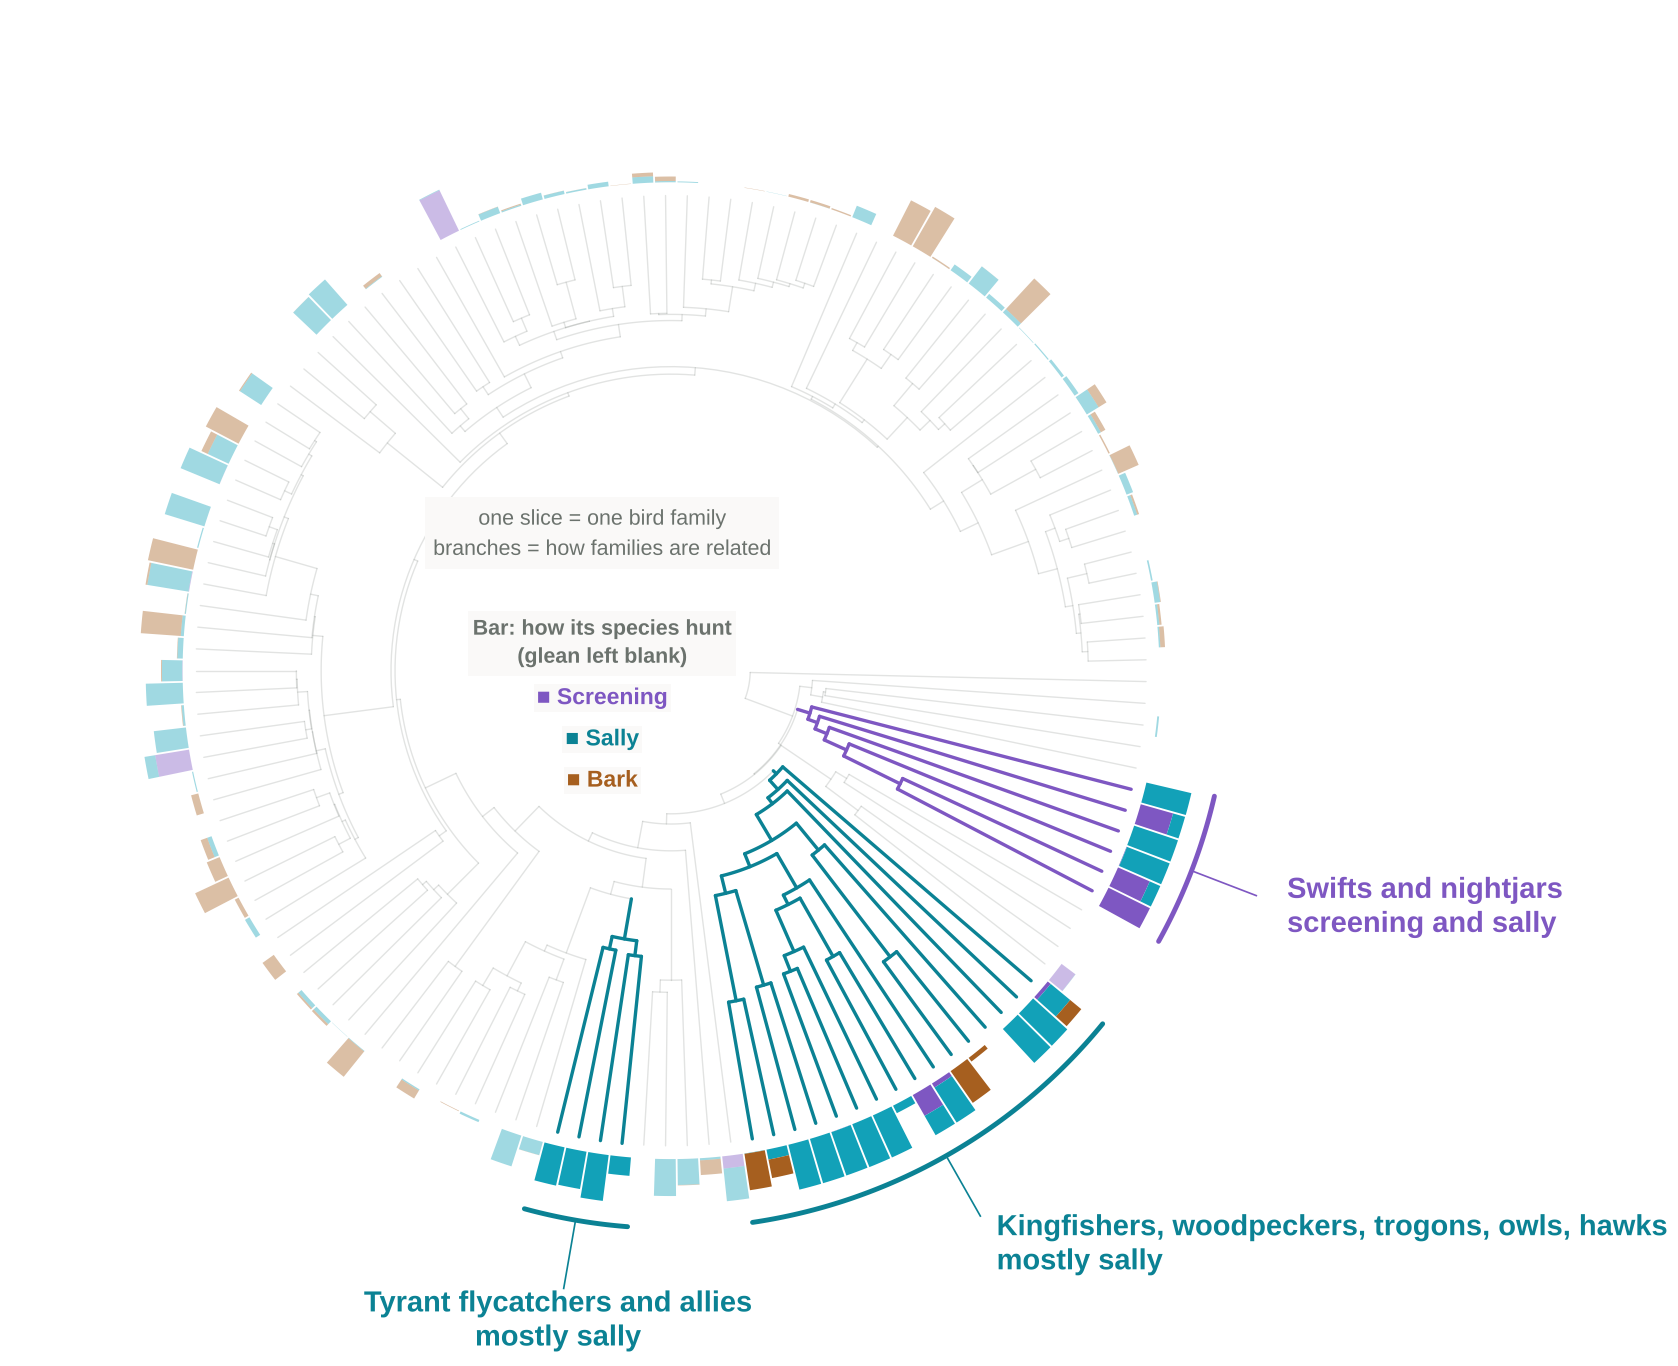

In [41]:
KINGFISHERS_ETC = [
    "Lybiidae", "Picidae", "Indicatoridae", "Bucconidae", "Galbulidae", "Alcedinidae",
    "Momotidae", "Todidae", "Brachypteraciidae", "Coraciidae", "Meropidae", "Phoeniculidae",
    "Upupidae", "Bucerotidae", "Trogonidae", "Leptosomidae", "Strigidae", "Accipitridae",
]
TYRANTS = ["Tityridae", "Tyrannidae", "Pipridae", "Cotingidae"]

fig, ax, hl = draw_polar_tree([(SWIFTS, "#7e57c2"), (KINGFISHERS_ETC, "#0b8294"), (TYRANTS, "#0b8294")])

rin, H = 0.74, 0.07
TC = ["#7e57c2", "#12a1b8", "#9aa39d", "#a65f1f"]
TL = ["Screening", "Sally", "Glean", "Bark"]

for l in leaves:
    nm = l["name"]
    if nm not in valid_comp_fams:
        continue
    bottom = rin
    shares = msh.loc[nm, ["I_Screen", "I_Sally", "I_Glean", "I_Bark"]].to_numpy(dtype=float)
    shares = shares / shares.sum()
    for k in (0, 1, 3):  # leave Glean (index 2) blank
        ax.bar(l["a"], H * shares[k], width=W_STEP * 0.92, bottom=bottom, color=TC[k], lw=0, alpha=1.0 if id(l) in hl else 0.4)
        bottom += H * shares[k]

add_clade_arc(ax, SWIFTS, "Swifts and nightjars\nscreening and sally", "#7e57c2", r=0.845)
add_clade_arc(ax, KINGFISHERS_ETC, "Kingfishers, woodpeckers, trogons, owls, hawks\nmostly sally", "#0b8294", r=0.845)
add_clade_arc(ax, TYRANTS, "Tyrant flycatchers and allies\nmostly sally", "#0b8294", r=0.845)

cx = 0.45
box_kw = dict(fc="#faf9f8", ec="none")
fig.text(cx, 0.60, "one slice = one bird family\nbranches = how families are related", ha="center", va="center", fontsize=14, color="#6b726d", linespacing=1.4, bbox={**box_kw, "pad": 5})
fig.text(cx, 0.52, "Bar: how its species hunt\n(glean left blank)", ha="center", va="center", fontsize=14, color="#6b726d", fontweight="bold", linespacing=1.4, bbox={**box_kw, "pad": 3})
for idx, k in enumerate((0, 1, 3)):
    col = "#0b8294" if k == 1 else TC[k]
    fig.text(cx, 0.480 - idx * 0.03, "\u25A0 " + TL[k], ha="center", va="center", fontsize=15, fontweight="bold", color=col, bbox={**box_kw, "pad": 2})

fig.savefig(FIG_DIR / "tree_techniques.png", bbox_inches="tight", dpi=150, facecolor="#faf9f8")
plt.show()

**Reading the figures** · **Takeaway.** Morphotypes follow clades: swifts and nightjars are M1 (frogmouths are the exception), ovenbirds and antbirds mostly M4, waders M2, tits M3, while the thrush allies mix three morphotypes. Techniques also recur in distant lineages: sallying in tyrant flycatchers and in kingfishers, trogons, jacamars and owls; bark foraging in woodpeckers and woodhoopoes. The highlighted kingfisher group is not uniform, though: woodpeckers and woodhoopoes are bark foragers, hoopoes and hornbills gleaners.

### Findings · Chapter III
* **Target:** the dominant technique, four unbalanced classes (glean 2,446, sally 1,060, bark 320, screening 293 species).
* On **unseen families** macro ROC-AUC is 0.87 (LR) and 0.88 (RF), against 0.50 with shuffled labels; macro PR-AUC 0.67 / 0.69 against 0.25. Random folds inflate the forest most.
* **Technique by technique:** screening 0.99 / 1.00, gleaning 0.87 / 0.88, sallying 0.76 / 0.83; bark ranks reasonably (0.86 / 0.83) but is hard to pick out (PR-AUC 0.30 / 0.27 against 0.08), and the forest finds only 19% of bark foragers.
* On **unseen orders** macro ROC-AUC is still 0.82 for both models.
* SHAP gives each technique its own signature: pointed wings for screening, a broad flat beak for sallying, long legs for gleaning, a long bill before the nostrils for bark.

# Conclusions
**What we asked, and what we found**
1. **Do invertivores come in body types, or form one continuum?** Both. One sharply separated type, the aerial screeners (M1, 322 species). The other three blend into each other (silhouette 0.18 against 0.09 on shuffled data), yet they hunt differently: M3 sallies, M4 gleans, M2 holds the bark foragers.
2. **Does shape predict the main technique, even on lineages a model has never seen?** Yes. Macro ROC-AUC 0.87–0.88 on unseen families and 0.82 on unseen orders, against 0.5 by chance; aerial screening reaches 0.99. Geography adds little.

**What stays open**
* Only M1 is separated; M2–M4 are graded, and four is our choice of cut (the only k that passed the stability rule, bootstrap ARI 0.95).
* Species are not independent: p-values are optimistic, and even family and order folds leave relatives of the test birds in training.
* The main technique simplifies a mixture; sallying and bark are the hardest to predict.